# Notebook 02 — Análise comparativa: normal vs. anomalia (coleta intercalada NOVOS_2.0)

**O que buscamos aqui:** no Notebook 01 entendemos cada gravação. Agora queremos saber **o que muda do normal para cada anomalia, velocidade por velocidade**, e se essa mudança é **maior do que a variação natural do próprio normal**. Quatro perguntas, as mesmas da coleta anterior:

1. Como o sinal e as features de tempo mudam do normal para a anomalia?
2. Quais frequências (faixas de 10 Hz) mudam, em qual eixo e em que direção?
3. A rotação (1X) e suas harmônicas mudam? A rotação é a mesma nas duas condições?
4. Quais features separam melhor as duas condições, e essa separação supera a variação natural do normal?

E uma quinta, nova nesta coleta: **o calço se diferencia do normal?** (a decisão formal fica para o Notebook 05; aqui é a primeira leitura).

| Passo | O que fazemos | O que buscamos |
| --- | --- | --- |
| 1 | Configurar parâmetros | A ordem da sessão e o que será comparado |
| 2 | Carregar as bases e achar os vizinhos | As mesmas bases do Notebook 01 e, para cada anomalia, os dois normais gravados antes e depois dela |
| 3 | Cortar em janelas e calcular as 99 features | A mesma tabela de features do dataset, mais o espectro de cada janela |
| 4 | Sinal no tempo | Ver a diferença de amplitude e de forma da onda |
| 5 | Features de tempo (desvio padrão, curtose e pico) | Quais mudam, para que lado, e quanto separam |
| 6 | Espectro médio | Em quais frequências a anomalia aparece |
| 7 | Mapa por faixa de 10 Hz | Onde, em qual eixo e em que direção cada faixa muda |
| 8 | Rotação 1X e harmônicas | A rotação mudou? 1X, 2X e 3X cresceram? |
| 9 | Resumo e controles | As melhores features e quantas superam a variação natural do normal |
| 10 | Todas as gravações entre si e falha contra falha | O quanto o normal muda sozinho e se dá para saber **qual** é a falha |

## O que muda em relação ao Notebook 02 da coleta anterior

Na coleta anterior havia **uma gravação normal** por velocidade, e o controle era comparar a segunda metade dessa gravação com a primeira (o aquecimento acontecia **dentro** da gravação). Na NOVOS_2.0 o Notebook 01 mostrou o contrário:

* **Dentro de cada gravação** o normal quase não muda (−6% a +7% do primeiro ao último terço).
* **Entre os lotes** o normal muda bastante: a rotação sobe cerca de 0,8 Hz de N1 a N5 nas Vel 1 e 2, e a vibração varia de 10% a 35%.

Então o controle antigo (metade × metade) ficaria **fraco demais** aqui: ele não vê a diferença entre lotes, e qualquer coisa gravada em outro momento da sessão pareceria uma falha. Por isso este notebook usa **duas referências**, cada uma com o seu controle:

| Referência | Contra o que a anomalia é comparada | Controle (a "variação natural") | Pergunta |
| --- | --- | --- | --- |
| **5 normais juntos** | As janelas dos 5 lotes de normal | **Lote contra resto:** cada lote normal comparado com os outros 4 | A anomalia foge do normal **mais do que um lote normal foge dos outros**? |
| **Vizinhos** | Os dois normais gravados logo antes e logo depois da anomalia | **Vizinho contra vizinho:** um vizinho comparado com o outro | A anomalia fica **fora dos dois vizinhos**, mais do que eles diferem entre si? |

A primeira é a régua **global** e rigorosa (comparável ao "teto do controle" da coleta anterior). A segunda é a régua **local**, que desconta o aquecimento: os vizinhos foram gravados no mesmo trecho da sessão que a anomalia.

Como no Notebook 01, os primeiros e os últimos `DESCARTAR_INICIO_S`/`DESCARTAR_FIM_S` segundos de cada base são descartados.

## Como ler a "separação"

Várias comparações usam a **separação**, um número de **−1 a +1** calculado para cada feature e cada velocidade:

* **0:** as janelas da anomalia e as da referência estão misturadas, sem diferença.
* **+1:** **todas** as janelas da anomalia têm valor maior que **todas** as da referência.
* **−1:** todas as janelas da anomalia têm valor menor.

Ela se baseia em posições (ranks) e não supõe distribuição normal. **Cuidado:** janelas vizinhas são parecidas entre si (autocorrelação), então a separação é um guia visual e **não** um teste estatístico. O teste vem no Notebook 03.

**Convenção das células:** cada função fica numa célula e a sua execução fica na célula seguinte.

## Passo 1 — Configuração

**O que buscamos:** concentrar num só lugar tudo o que muda de um experimento para outro. As duas escolhas mais importantes são a **ordem da sessão** (é ela que diz quem é vizinho de quem) e o **limiar do critério dos vizinhos**.

In [1]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from scipy.stats import kurtosis, rankdata
from IPython.display import display

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.linestyle": "--", "grid.alpha": 0.4})
pd.set_option("display.width", 200)

In [2]:
# ----------------------------------------------------------------------
# ONDE ESTÃO OS DADOS (a mesma pasta do Notebook 01)
# ----------------------------------------------------------------------
PASTA_BASES = Path(r"C:\Users\santo\OneDrive\Área de Trabalho\TCC\DADOS\NOVOS_DADOS\NOVOS_2.0")
BUSCAR_EM_SUBPASTAS = True        # True = lê também os CSVs dentro das subpastas (NORMAL_LOTE_1, CALCO, ...)
DESCARTAR_INICIO_S = 5            # segundos descartados no começo de cada base (Notebook 01, Passo 4.1)
DESCARTAR_FIM_S = 5               # segundos descartados no fim de cada base

# ----------------------------------------------------------------------
# ORDEM DA SESSÃO (a mesma do Notebook 01)
# Um item por bloco, na ordem em que foram gravados. Os lotes do normal recebem os números na ordem em que aparecem.
# ATENÇÃO: a ordem entre fita_1g e fita_05g NÃO foi anotada; aqui está assumida (1 g antes de 0,5 g).
# ----------------------------------------------------------------------
ORDEM_SESSAO = [
    "ventilador_normal", "calco", "ventilador_normal", "fita_1g", "ventilador_normal",
    "fita_05g", "ventilador_normal", "papel", "ventilador_normal",
]
CONDICAO_NORMAL = "ventilador_normal"   # a condição de referência (todos os lotes dela)
CONDICOES_COMPARADAS = None             # None = todas as outras condições da pasta, na ordem da sessão

# ----------------------------------------------------------------------
# COMO OS DADOS FORAM COLETADOS
# ----------------------------------------------------------------------
TAXA_AMOSTRAGEM_HZ = 1000
EIXOS = ["x", "y", "z"]
UNIDADE = "m/s²"

# ----------------------------------------------------------------------
# JANELAS E FEATURES (a mesma receita do dataset de 99 features)
# ----------------------------------------------------------------------
JANELA_S = 5                      # janela de 5 s, sem sobreposição
FAIXA_FFT_HZ = (5, 305)           # faixas de 10 Hz de 5 a 305 Hz
LARGURA_FAIXA_HZ = 10

# ----------------------------------------------------------------------
# CRITÉRIO DOS VIZINHOS (Passos 5, 7 e 9)
# Uma feature "passa no critério dos vizinhos" quando a anomalia fica do MESMO LADO dos dois vizinhos,
# com separação de pelo menos LIMIAR_VIZINHOS contra cada um, e maior do que a separação entre os dois vizinhos.
# ----------------------------------------------------------------------
LIMIAR_VIZINHOS = 0.5

# ----------------------------------------------------------------------
# GRÁFICOS
# ----------------------------------------------------------------------
INICIO_TRECHO_S = None            # onde começa o trecho de 1 s do Passo 4 (None = meio de cada base)
F_MAX_PLOT_HZ = 300               # limite superior do espectro do Passo 6
ESCALA_Y_FFT = "linear"           # "linear" ou "log"
FREQS_REFERENCIA_HZ = [120, 240]  # linhas elétricas (confirmadas pelo orientador), marcadas nos espectros

# ----------------------------------------------------------------------
# ROTAÇÃO 1X E HARMÔNICAS (Passo 8)
# ----------------------------------------------------------------------
FAIXA_BUSCA_1X_HZ = (8, 30)       # faixa onde procuramos o pico de rotação
DESVIO_MAX_1X_HZ = 2.0            # numa janela, o 1X só pode ficar a até esta distância da rotação típica da base
N_HARMONICAS = 3                  # mede 1X, 2X e 3X
TOLERANCIA_HARMONICA_HZ = 0.6     # a amplitude de kX é o maior pico a até esta distância de k vezes o 1X

# ----------------------------------------------------------------------
# RESUMO (Passo 9)
# ----------------------------------------------------------------------
N_TOP = 5                         # quantas features mostrar por velocidade

# ----------------------------------------------------------------------
# APARÊNCIA
# ----------------------------------------------------------------------
COR_NORMAIS = "darkgrey"          # os 5 normais juntos
COR_VIZINHOS = "dodgerblue"       # os dois normais vizinhos da anomalia
COR_COMPARADA = "crimson"         # a anomalia
CORES_VIZINHOS_SINAL = ["dodgerblue", "navy"]   # vizinho anterior e posterior no Passo 4
NOMES_EIXOS = {"x": "Eixo X (lateral)", "y": "Eixo Y (frontal)", "z": "Eixo Z (vertical)"}

## Passo 2 — Carregar as bases e achar os vizinhos de cada anomalia

**O que buscamos:** ler a pasta (as funções de leitura são as mesmas do Notebook 01, que entendem o sufixo `_lote_<K>` dos normais), colocar cada gravação na sua **posição da sessão** e montar as duas referências:

* **5 normais juntos:** os blocos N1 a N5.
* **Vizinhos:** para cada anomalia, o normal gravado **logo antes** e o normal gravado **logo depois** dela. Por exemplo, com a ordem N1, calço, N2, ..., os vizinhos do calço são N1 e N2.

A posição da sessão é usada **só para escolher a referência**. Ela não entra como feature em nenhum notebook.

In [3]:
PADRAO_NOME = re.compile(r"^(?P<condicao>.+)_vel_(?P<velocidade>\d+)(?:_lote_(?P<lote>\d+))?$")


def ler_rotulo_do_nome(nome_base):
    """Separa o nome em condição, velocidade e lote.

    'fita_1g_vel_2' -> ('fita_1g', 2, 0);  'ventilador_normal_vel_1_lote_3' -> ('ventilador_normal', 1, 3).
    Lote 0 quer dizer que a condição foi gravada uma vez só.
    """
    encontrado = PADRAO_NOME.match(nome_base)
    if encontrado is None:
        raise ValueError(
            f"Nome fora do padrão: '{nome_base}'. Use <condicao>_vel_<N> ou <condicao>_vel_<N>_lote_<K>."
        )
    return encontrado["condicao"], int(encontrado["velocidade"]), int(encontrado["lote"] or 0)


def carregar_base(caminho):
    """Lê um CSV e devolve só as colunas x, y e z como números decimais."""
    df = pd.read_csv(caminho)
    faltando = [eixo for eixo in EIXOS if eixo not in df.columns]
    if faltando:
        raise ValueError(f"{Path(caminho).name}: faltam as colunas {faltando}. Colunas encontradas: {list(df.columns)}")
    return df[EIXOS].astype(float)


def carregar_todas_as_bases(pasta):
    """Lê todos os CSVs da pasta. Devolve (bases, catalogo)."""
    arquivos = sorted(Path(pasta).rglob("*.csv") if BUSCAR_EM_SUBPASTAS else Path(pasta).glob("*.csv"))
    if not arquivos:
        raise FileNotFoundError(f"Nenhum CSV em '{pasta}'. Confira PASTA_BASES.")
    bases, linhas = {}, []
    for arquivo in arquivos:
        nome = arquivo.stem
        condicao, velocidade, lote = ler_rotulo_do_nome(nome)
        bases[nome] = carregar_base(arquivo)
        linhas.append({"base": nome, "condicao": condicao, "velocidade": velocidade, "lote": lote,
                       "linhas": len(bases[nome]), "duracao_s": len(bases[nome]) / TAXA_AMOSTRAGEM_HZ})
    catalogo = pd.DataFrame(linhas).sort_values(["condicao", "lote", "velocidade"]).set_index("base")
    return {nome: bases[nome] for nome in catalogo.index}, catalogo


def aparar_bases(bases, catalogo, inicio_s=DESCARTAR_INICIO_S, fim_s=DESCARTAR_FIM_S):
    """Descarta inicio_s segundos do começo e fim_s do fim de cada base (o mesmo corte do Notebook 01)."""
    inicio, fim = int(inicio_s * TAXA_AMOSTRAGEM_HZ), int(fim_s * TAXA_AMOSTRAGEM_HZ)
    aparadas = {nome: df.iloc[inicio: len(df) - fim].reset_index(drop=True) for nome, df in bases.items()}
    catalogo = catalogo.copy()
    catalogo["linhas"] = [len(aparadas[nome]) for nome in catalogo.index]
    catalogo["duracao_s"] = catalogo["linhas"] / TAXA_AMOSTRAGEM_HZ
    return aparadas, catalogo

In [4]:
def adicionar_posicao_na_sessao(catalogo, ordem_sessao=ORDEM_SESSAO, condicao_normal=CONDICAO_NORMAL):
    """Acrescenta ao catálogo a posição de cada gravação na sessão e reordena o catálogo por ela.

    Colunas novas: posicao_sessao (o bloco, 1 a 9), bloco (N1 a N5 para os normais; o nome da condição para as
    anomalias) e grupo (o texto usado nas tabelas, por exemplo '2. calco').
    """
    catalogo = catalogo.copy()
    posicao, lote_atual = {}, 0
    for i, condicao in enumerate(ordem_sessao, start=1):
        if condicao == condicao_normal:
            lote_atual += 1
            posicao[(condicao, lote_atual)] = i
        else:
            posicao[(condicao, 0)] = i
    sem_posicao = sorted(set(zip(catalogo["condicao"], catalogo["lote"])) - set(posicao))
    if sem_posicao:
        raise ValueError(f"Estas condições/lotes não estão em ORDEM_SESSAO: {sem_posicao}. Ajuste o Passo 1.")
    catalogo["posicao_sessao"] = [posicao[(c, l)] for c, l in zip(catalogo["condicao"], catalogo["lote"])]
    eh_normal = catalogo["condicao"] == condicao_normal
    catalogo["bloco"] = np.where(eh_normal, "N" + catalogo["lote"].astype(str), catalogo["condicao"])
    catalogo["grupo"] = catalogo["posicao_sessao"].astype(str) + ". " + catalogo["bloco"]
    return catalogo.sort_values(["posicao_sessao", "velocidade"])


def encontrar_vizinhos(catalogo, condicao_normal=CONDICAO_NORMAL):
    """Para cada anomalia, a lista [normal logo antes, normal logo depois] na sessão (só um, se estiver na ponta)."""
    blocos = catalogo.drop_duplicates("bloco").sort_values("posicao_sessao")
    normais = blocos[blocos["condicao"] == condicao_normal]
    vizinhos = {}
    for _, linha in blocos[blocos["condicao"] != condicao_normal].iterrows():
        antes = normais.loc[normais["posicao_sessao"] < linha["posicao_sessao"], "bloco"].tail(1).tolist()
        depois = normais.loc[normais["posicao_sessao"] > linha["posicao_sessao"], "bloco"].head(1).tolist()
        vizinhos[linha["condicao"]] = antes + depois
    return vizinhos


def definir_comparacoes(catalogo, condicoes_comparadas=None, condicao_normal=CONDICAO_NORMAL):
    """Lista das anomalias comparadas, na ordem da sessão."""
    anomalias = (catalogo[catalogo["condicao"] != condicao_normal]
                 .drop_duplicates("condicao").sort_values("posicao_sessao")["condicao"].tolist())
    if condicoes_comparadas is None:
        return anomalias
    faltando = [c for c in condicoes_comparadas if c not in anomalias]
    if faltando:
        raise ValueError(f"Condição comparada não encontrada: {faltando}. Anomalias na pasta: {anomalias}")
    return list(condicoes_comparadas)

In [5]:
bases, catalogo = carregar_todas_as_bases(PASTA_BASES)
bases, catalogo = aparar_bases(bases, catalogo)
catalogo = adicionar_posicao_na_sessao(catalogo)
velocidades = sorted(catalogo["velocidade"].unique())
BLOCOS_NORMAIS = catalogo.loc[catalogo["condicao"] == CONDICAO_NORMAL].drop_duplicates("bloco")["bloco"].tolist()
vizinhos = encontrar_vizinhos(catalogo)
condicoes_comparadas = definir_comparacoes(catalogo, CONDICOES_COMPARADAS)

print(f"Normais (5 normais juntos): {BLOCOS_NORMAIS}")
print(f"Anomalias comparadas: {condicoes_comparadas}")
print("Vizinhos de cada anomalia:")
for condicao in condicoes_comparadas:
    print(f"  {condicao:10s} -> {' e '.join(vizinhos[condicao])}")
display(catalogo.pivot_table(index="grupo", columns="velocidade", values="duracao_s", sort=False)
        .rename_axis(columns="Vel").round(1))

Normais (5 normais juntos): ['N1', 'N2', 'N3', 'N4', 'N5']
Anomalias comparadas: ['calco', 'fita_1g', 'fita_05g', 'papel']
Vizinhos de cada anomalia:
  calco      -> N1 e N2
  fita_1g    -> N2 e N3
  fita_05g   -> N3 e N4
  papel      -> N4 e N5


Vel,1,2,3
grupo,,,
1. N1,171.5,176.0,181.0
2. calco,179.0,185.0,218.5
3. N2,193.5,181.0,178.0
4. fita_1g,169.0,175.5,175.0
5. N3,188.0,184.0,190.0
6. fita_05g,190.5,192.0,188.5
7. N4,191.0,189.5,189.0
8. papel,191.0,191.0,193.0
9. N5,192.0,192.0,213.0


### O que encontramos no Passo 2

* **27 bases em 9 blocos**, na ordem N1, calço, N2, fita 1 g, N3, fita 0,5 g, N4, papel, N5. Depois do corte de 5 s no começo e no fim, cada base tem de **169 a 218,5 s**.
* **Vizinhos:** calço → N1 e N2; fita 1 g → N2 e N3; fita 0,5 g → N3 e N4; papel → N4 e N5. Cada anomalia tem um normal antes e um depois, então o critério dos vizinhos vale para as quatro.
* **Lembrete:** a ordem entre as duas fitas foi assumida (Notebook 01, Passo 10). Se ela for trocada em `ORDEM_SESSAO`, os vizinhos das fitas mudam (fita 0,5 g passaria a ter N2 e N3) e os números deste notebook mudam para elas.

## Passo 3 — Cortar em janelas e calcular as 99 features

**O que buscamos:** transformar cada base na **tabela de features** que o dataset do grupo usa, para comparar condições em números e não só a olho. É a mesma receita da coleta anterior.

Cada base é cortada em janelas de `JANELA_S` segundos, sem sobreposição. Em cada janela, depois de remover o componente DC (a gravidade), calculamos:

* **9 features de tempo:** desvio padrão (`std`), curtose de Fisher (`kurt`) e pico (`pico`, o maior valor absoluto), por eixo.
* **90 features de frequência:** FFT com janela de Hanning, dividida em faixas de 10 Hz de 5 a 305 Hz. O valor de cada faixa é o **máximo** da magnitude dentro dela, por eixo (`fft_005_015Hz_x` etc.).

Guardamos também o **espectro completo de cada janela**, para o espectro médio (Passo 6) e para a rotação 1X (Passo 8). Cada linha da tabela leva também o **bloco** (N1 a N5 ou a anomalia), que é como as funções escolhem as referências.

In [6]:
def faixas_de_frequencia():
    """Lista de faixas (início, fim) em Hz, como (5, 15), (15, 25), ..., (295, 305)."""
    limites = np.arange(FAIXA_FFT_HZ[0], FAIXA_FFT_HZ[1] + LARGURA_FAIXA_HZ, LARGURA_FAIXA_HZ)
    return [(int(inicio), int(fim)) for inicio, fim in zip(limites[:-1], limites[1:])]


def colunas_fft_do_eixo(eixo):
    """Nomes das colunas de FFT de um eixo, na ordem das faixas."""
    return [f"fft_{inicio:03d}_{fim:03d}Hz_{eixo}" for inicio, fim in faixas_de_frequencia()]


def calcular_features_e_espectros(df, janela_s=JANELA_S):
    """Corta a base em janelas sem sobreposição e calcula as features de cada janela.

    Devolve (features, frequencias, espectros); espectros tem o formato (janela, frequência, eixo).
    """
    tamanho = int(janela_s * TAXA_AMOSTRAGEM_HZ)
    n_janelas = len(df) // tamanho
    janelas = df[EIXOS].to_numpy()[: n_janelas * tamanho].reshape(n_janelas, tamanho, len(EIXOS))
    janelas = janelas - janelas.mean(axis=1, keepdims=True)         # remove o componente DC de cada janela

    colunas = {}
    std, curtose, pico = janelas.std(axis=1, ddof=1), kurtosis(janelas, axis=1, fisher=True), np.abs(janelas).max(axis=1)
    for k, eixo in enumerate(EIXOS):
        colunas[f"std_{eixo}"], colunas[f"kurt_{eixo}"], colunas[f"pico_{eixo}"] = std[:, k], curtose[:, k], pico[:, k]

    # FFT com janela de Hanning; o fator 4/N compensa a energia que a janela remove
    magnitude = np.abs(np.fft.rfft(janelas * np.hanning(tamanho)[None, :, None], axis=1)) * (4.0 / tamanho)
    frequencias = np.fft.rfftfreq(tamanho, d=1.0 / TAXA_AMOSTRAGEM_HZ)
    for inicio, fim in faixas_de_frequencia():
        maximo_da_faixa = magnitude[:, (frequencias >= inicio) & (frequencias < fim), :].max(axis=1)
        for k, eixo in enumerate(EIXOS):
            colunas[f"fft_{inicio:03d}_{fim:03d}Hz_{eixo}"] = maximo_da_faixa[:, k]

    no_intervalo = (frequencias >= FAIXA_FFT_HZ[0]) & (frequencias < FAIXA_FFT_HZ[1])
    return pd.DataFrame(colunas), frequencias[no_intervalo], magnitude[:, no_intervalo, :]


def analisar_todas_as_bases(bases, catalogo, janela_s=JANELA_S):
    """Calcula as features de todas as bases e junta numa só tabela (com base, bloco, condicao, velocidade e janela)."""
    tabelas, espectros_por_base, frequencias = [], {}, None
    for nome, df in bases.items():
        features, frequencias, espectros = calcular_features_e_espectros(df, janela_s)
        features.insert(0, "janela", np.arange(len(features)))
        for coluna in ("posicao_sessao", "velocidade", "lote", "condicao", "bloco"):
            features.insert(0, coluna, catalogo.loc[nome, coluna])
        features.insert(0, "base", nome)
        tabelas.append(features)
        espectros_por_base[nome] = espectros
    return pd.concat(tabelas, ignore_index=True), frequencias, espectros_por_base

In [7]:
features, frequencias, espectros_por_base = analisar_todas_as_bases(bases, catalogo)

COLUNAS_TEMPO = [f"{tipo}_{eixo}" for tipo in ("std", "kurt", "pico") for eixo in EIXOS]
COLUNAS_FFT = [coluna for eixo in EIXOS for coluna in colunas_fft_do_eixo(eixo)]

print(f"Features por janela: {len(COLUNAS_TEMPO)} de tempo + {len(COLUNAS_FFT)} de FFT = {len(COLUNAS_TEMPO) + len(COLUNAS_FFT)}")
print(f"Janelas de {JANELA_S} s por bloco e velocidade:")
ordem_blocos = catalogo.drop_duplicates("bloco")["bloco"].tolist()
display(features.groupby(["bloco", "velocidade"]).size().unstack().reindex(ordem_blocos).rename_axis(columns="Vel"))

Features por janela: 9 de tempo + 90 de FFT = 99
Janelas de 5 s por bloco e velocidade:


Vel,1,2,3
bloco,,,
N1,34,35,36
calco,35,37,43
N2,38,36,35
fita_1g,33,35,35
N3,37,36,38
fita_05g,38,38,37
N4,38,37,37
papel,38,38,38
N5,38,38,42


### Funções de apoio para as comparações

Estas funções são usadas em todos os passos a seguir:

* **`selecionar_janelas`:** pega as janelas de um ou mais blocos (N1, N2, ..., calco, ...) numa velocidade.
* **`calcular_separacao`:** a separação de −1 a +1 explicada no início, para cada feature.
* **`controle_lote_contra_resto`:** cada lote normal contra os outros 4 juntos. É o controle da referência "5 normais": mostra o quanto **uma gravação normal** pode fugir das outras **sem falha nenhuma**.
* **`comparar_com_os_normais`:** o coração do notebook. Para uma anomalia numa velocidade, devolve por feature:

| Coluna | O que é |
| --- | --- |
| `sep_5_normais` | separação da anomalia contra os 5 normais juntos |
| `controle_lote_resto` | a maior separação (sem sinal) de um lote normal contra os outros 4, nessa feature |
| `sep_vizinhos` | separação da anomalia contra os dois vizinhos juntos |
| `sep_antes`, `sep_depois` | separação contra cada vizinho, separado |
| `viz_x_viz` | separação do vizinho de depois contra o de antes (controle local) |
| `forca_vizinhos` | a **menor** das duas separações contra os vizinhos, se as duas tiverem o mesmo sinal (senão 0) |
| `passa_vizinhos` | `forca_vizinhos` ≥ `LIMIAR_VIZINHOS` **e** maior que `viz_x_viz` em módulo |

A `forca_vizinhos` responde: "a anomalia fica do mesmo lado **dos dois** vizinhos, e com que folga?". Se a anomalia fica entre os dois vizinhos (por exemplo, acima de N1 e abaixo de N2), a força é zero: a diferença pode ser só o normal mudando ao longo da sessão.

In [8]:
EPS = 1e-12   # evita divisão por zero nas razões


def selecionar_janelas(features, blocos, velocidade):
    """Janelas de uma lista de blocos (N1, ..., calco, ...) numa velocidade."""
    return features[features["bloco"].isin(blocos) & (features["velocidade"] == velocidade)]


def calcular_separacao(grupo_a, grupo_b, colunas):
    """Separação (de -1 a +1) entre dois grupos de janelas, feature por feature.

    Positivo significa que o grupo_a tem valores maiores que o grupo_b. É a área sob a curva ROC
    reescalada (2 x AUC - 1), calculada pelas posições (ranks) dos valores.
    """
    n_a, n_b = len(grupo_a), len(grupo_b)
    if n_a == 0 or n_b == 0:
        return pd.Series(np.nan, index=colunas)
    postos = rankdata(np.vstack([grupo_a[colunas].to_numpy(), grupo_b[colunas].to_numpy()]), axis=0)
    auc = (postos[:n_a].sum(axis=0) - n_a * (n_a + 1) / 2) / (n_a * n_b)
    return pd.Series(2 * auc - 1, index=colunas)


def controle_lote_contra_resto(features, velocidade, colunas, blocos_normais):
    """Separação de cada lote normal contra os outros lotes juntos. Tabela (feature x lote), com sinal."""
    return pd.DataFrame({
        lote: calcular_separacao(selecionar_janelas(features, [lote], velocidade),
                                 selecionar_janelas(features, [b for b in blocos_normais if b != lote], velocidade),
                                 colunas)
        for lote in blocos_normais
    })


def comparar_com_os_normais(features, condicao, velocidade, colunas, vizinhos, blocos_normais, limiar=LIMIAR_VIZINHOS):
    """Compara uma anomalia com os 5 normais juntos e com os seus vizinhos, feature por feature (ver a tabela acima)."""
    anomalia = selecionar_janelas(features, [condicao], velocidade)
    viz = vizinhos[condicao]
    tabela = pd.DataFrame(index=colunas)
    tabela["sep_5_normais"] = calcular_separacao(anomalia, selecionar_janelas(features, blocos_normais, velocidade), colunas)
    tabela["controle_lote_resto"] = controle_lote_contra_resto(features, velocidade, colunas, blocos_normais).abs().max(axis=1)
    tabela["sep_vizinhos"] = calcular_separacao(anomalia, selecionar_janelas(features, viz, velocidade), colunas)
    tabela["sep_antes"] = calcular_separacao(anomalia, selecionar_janelas(features, viz[:1], velocidade), colunas)
    tabela["sep_depois"] = calcular_separacao(anomalia, selecionar_janelas(features, viz[-1:], velocidade), colunas)
    if len(viz) == 2:
        tabela["viz_x_viz"] = calcular_separacao(selecionar_janelas(features, viz[1:], velocidade),
                                                 selecionar_janelas(features, viz[:1], velocidade), colunas)
    else:
        tabela["viz_x_viz"] = 0.0
    mesmo_lado = np.sign(tabela["sep_antes"]) == np.sign(tabela["sep_depois"])
    tabela["forca_vizinhos"] = np.where(mesmo_lado, np.minimum(tabela["sep_antes"].abs(), tabela["sep_depois"].abs()), 0.0)
    tabela["passa_vizinhos"] = (tabela["forca_vizinhos"] >= limiar) & (tabela["forca_vizinhos"] > tabela["viz_x_viz"].abs())
    return tabela


def juntar_espectros(espectros_por_base, janelas):
    """Empilha os espectros das janelas escolhidas. Formato (janela, frequência, eixo)."""
    partes = [espectros_por_base[base][grupo["janela"].to_numpy()] for base, grupo in janelas.groupby("base", sort=False)]
    return np.concatenate(partes, axis=0)


def nome_da_base(catalogo, bloco, velocidade):
    """Nome da base de um bloco numa velocidade (ou None se não existir)."""
    candidatas = catalogo[(catalogo["bloco"] == bloco) & (catalogo["velocidade"] == velocidade)]
    return candidatas.index[0] if len(candidatas) else None

## Passo 4 — Sinal no tempo: vizinhos sobre anomalia

**O que buscamos:** ver, a olho, **como a onda muda** quando a anomalia aparece. Em cada velocidade (coluna) e eixo (linha), sobrepomos 1 segundo de cada **vizinho** (azul claro = o de antes, azul escuro = o de depois) e 1 segundo da **anomalia** (vermelho), sem o componente DC.

Como ler: uma anomalia que aumenta a vibração mostra a faixa vermelha mais larga que as azuis. Uma anomalia que muda a **forma** da onda (impactos) mostra picos que os vizinhos não têm. Se as três curvas se sobrepõem, a anomalia não aparece a olho. Cada coluna tem a **mesma escala** para os três eixos.

In [9]:
def escolher_inicio_do_trecho(df, duracao_s, inicio_s=None):
    """Segundo em que o trecho começa. Se inicio_s for None, usa o meio da base."""
    if inicio_s is not None:
        return inicio_s
    return max(0, int((len(df) / TAXA_AMOSTRAGEM_HZ - duracao_s) / 2))


def extrair_trecho(df, inicio_s, duracao_s):
    """Recorta um trecho da base e subtrai a média de cada eixo (remove o componente DC)."""
    inicio = int(inicio_s * TAXA_AMOSTRAGEM_HZ)
    trecho = df[EIXOS].iloc[inicio: inicio + int(duracao_s * TAXA_AMOSTRAGEM_HZ)]
    return (trecho - trecho.mean()).reset_index(drop=True)


def plotar_sinal_comparado(bases, catalogo, condicao, velocidades, vizinhos, duracao_s=1, inicio_s=None):
    """Grade (eixo x velocidade): os dois vizinhos (azuis) e a anomalia (vermelho), sem o componente DC."""
    fig, axs = plt.subplots(len(EIXOS), len(velocidades), figsize=(6 * len(velocidades), 3 * len(EIXOS)),
                            sharex=True, sharey="col", squeeze=False)
    curvas = [(bloco, cor, 1.0) for bloco, cor in zip(vizinhos[condicao], CORES_VIZINHOS_SINAL)] + [(condicao, COR_COMPARADA, 1.2)]
    for j, velocidade in enumerate(velocidades):
        for bloco, cor, largura in curvas:
            nome = nome_da_base(catalogo, bloco, velocidade)
            if nome is None:
                continue
            trecho = extrair_trecho(bases[nome], escolher_inicio_do_trecho(bases[nome], duracao_s, inicio_s), duracao_s)
            tempo = np.arange(len(trecho)) / TAXA_AMOSTRAGEM_HZ
            for i, eixo in enumerate(EIXOS):
                axs[i, j].plot(tempo, trecho[eixo], color=cor, linewidth=largura, alpha=0.75)
        axs[0, j].set_title(f"Vel {velocidade}", fontsize=12, fontweight="bold")
        axs[-1, j].set_xlabel("Tempo (s)")
    for i, eixo in enumerate(EIXOS):
        axs[i, 0].set_ylabel(f"{NOMES_EIXOS[eixo]}\nAceleração ({UNIDADE})")
    fig.legend(handles=[Patch(color=cor, label=bloco) for bloco, cor, _ in curvas],
               loc="upper center", ncol=len(curvas), fontsize=10, bbox_to_anchor=(0.5, 0.965))
    fig.suptitle(f"{duracao_s} s de sinal sem componente DC — {condicao} vs. vizinhos", fontsize=14, fontweight="bold", y=0.995)
    plt.tight_layout(rect=[0, 0, 1, 0.94])
    plt.show()

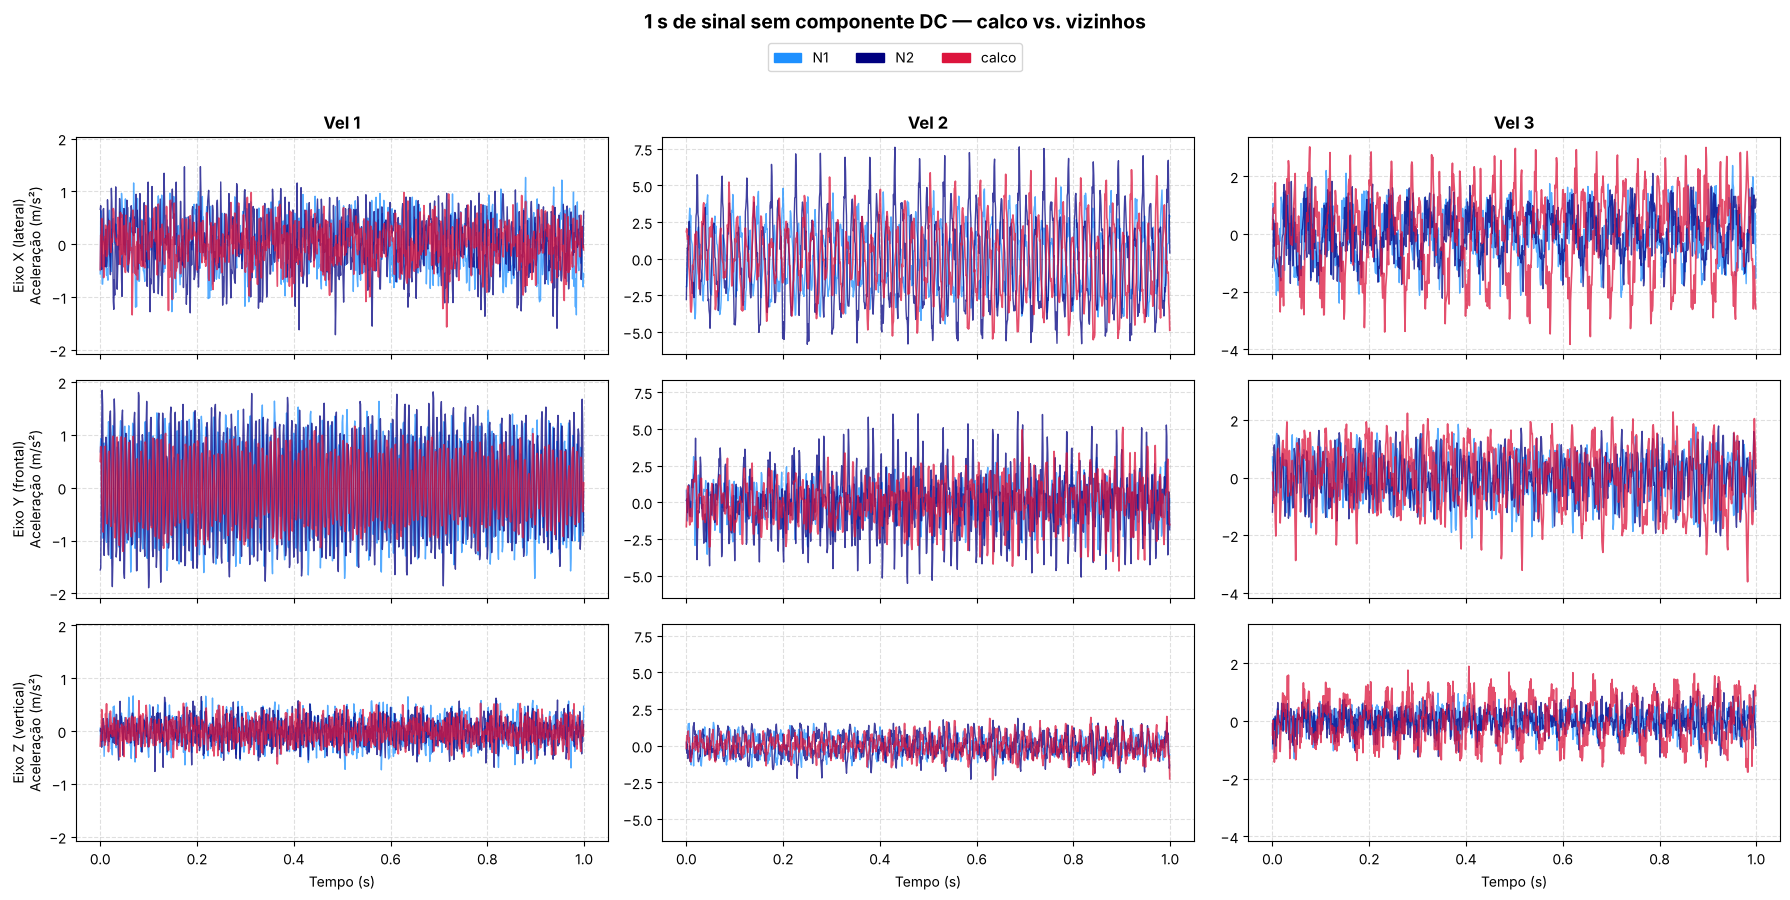

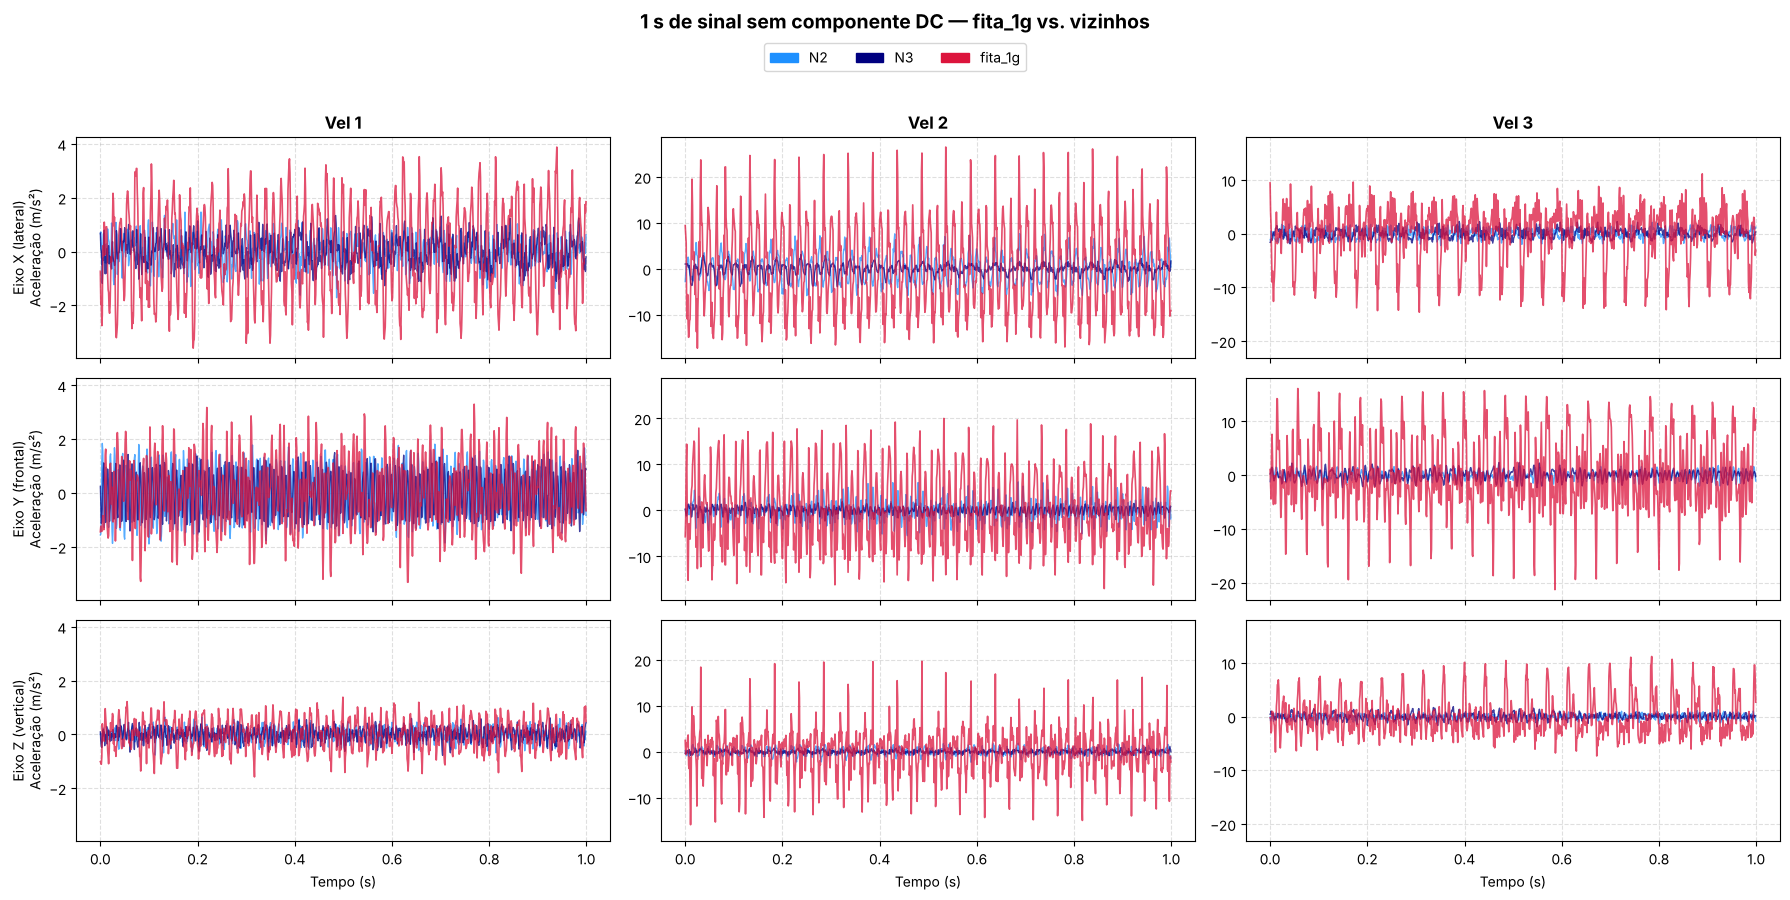

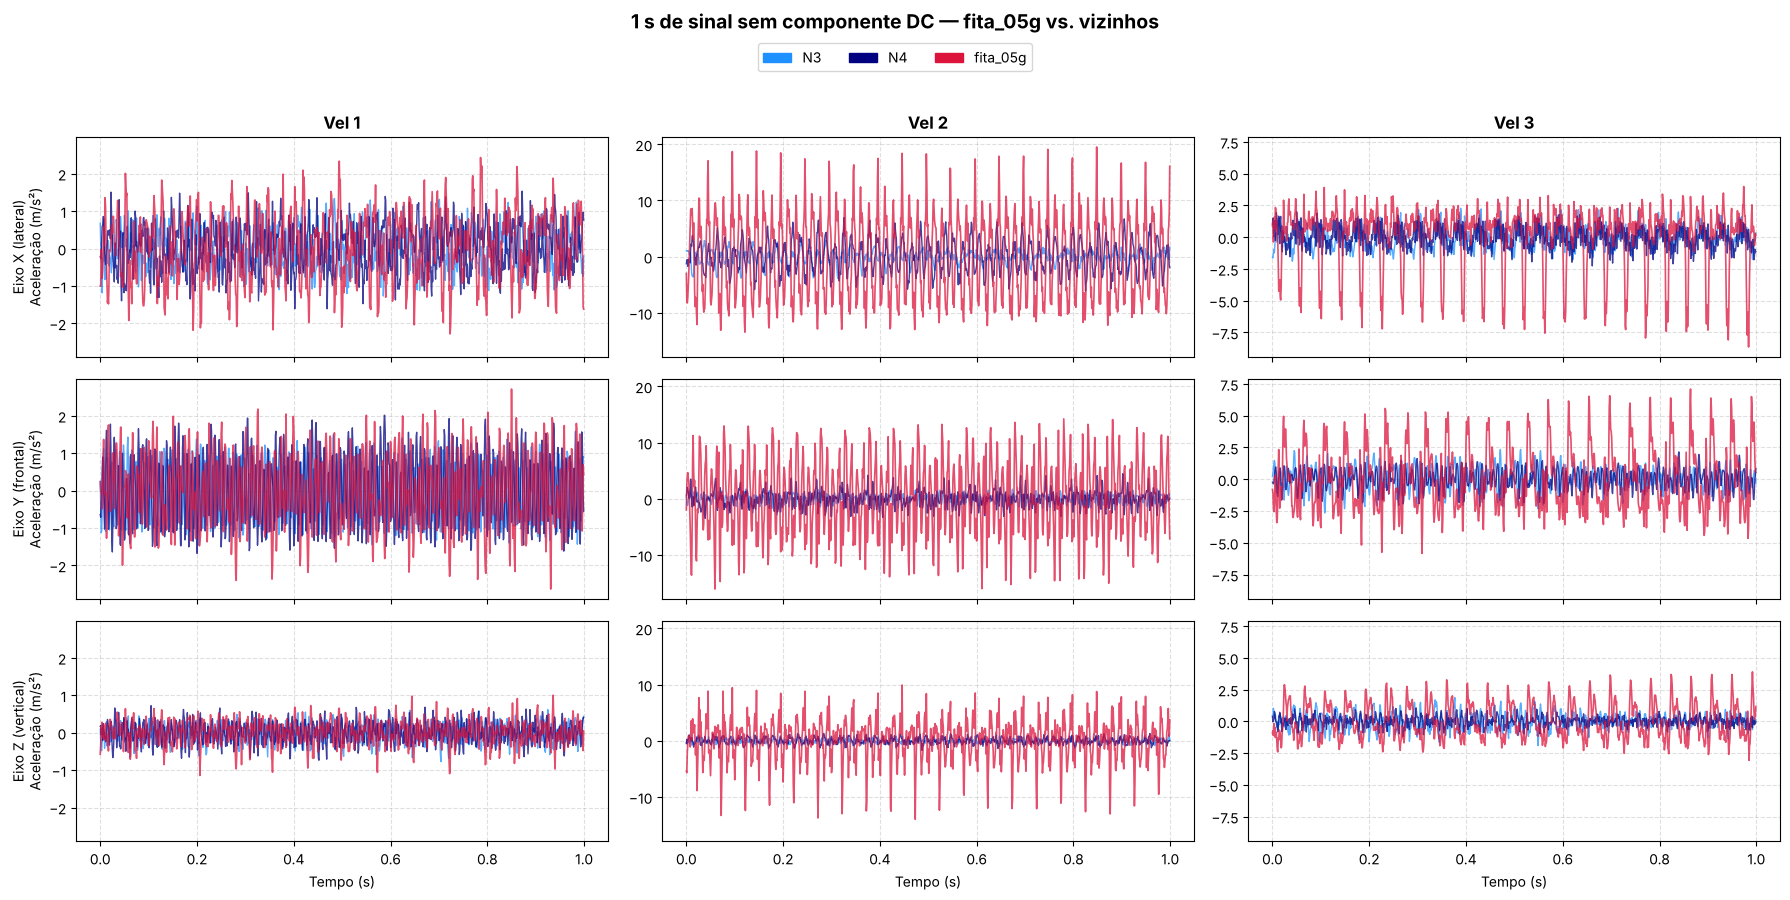

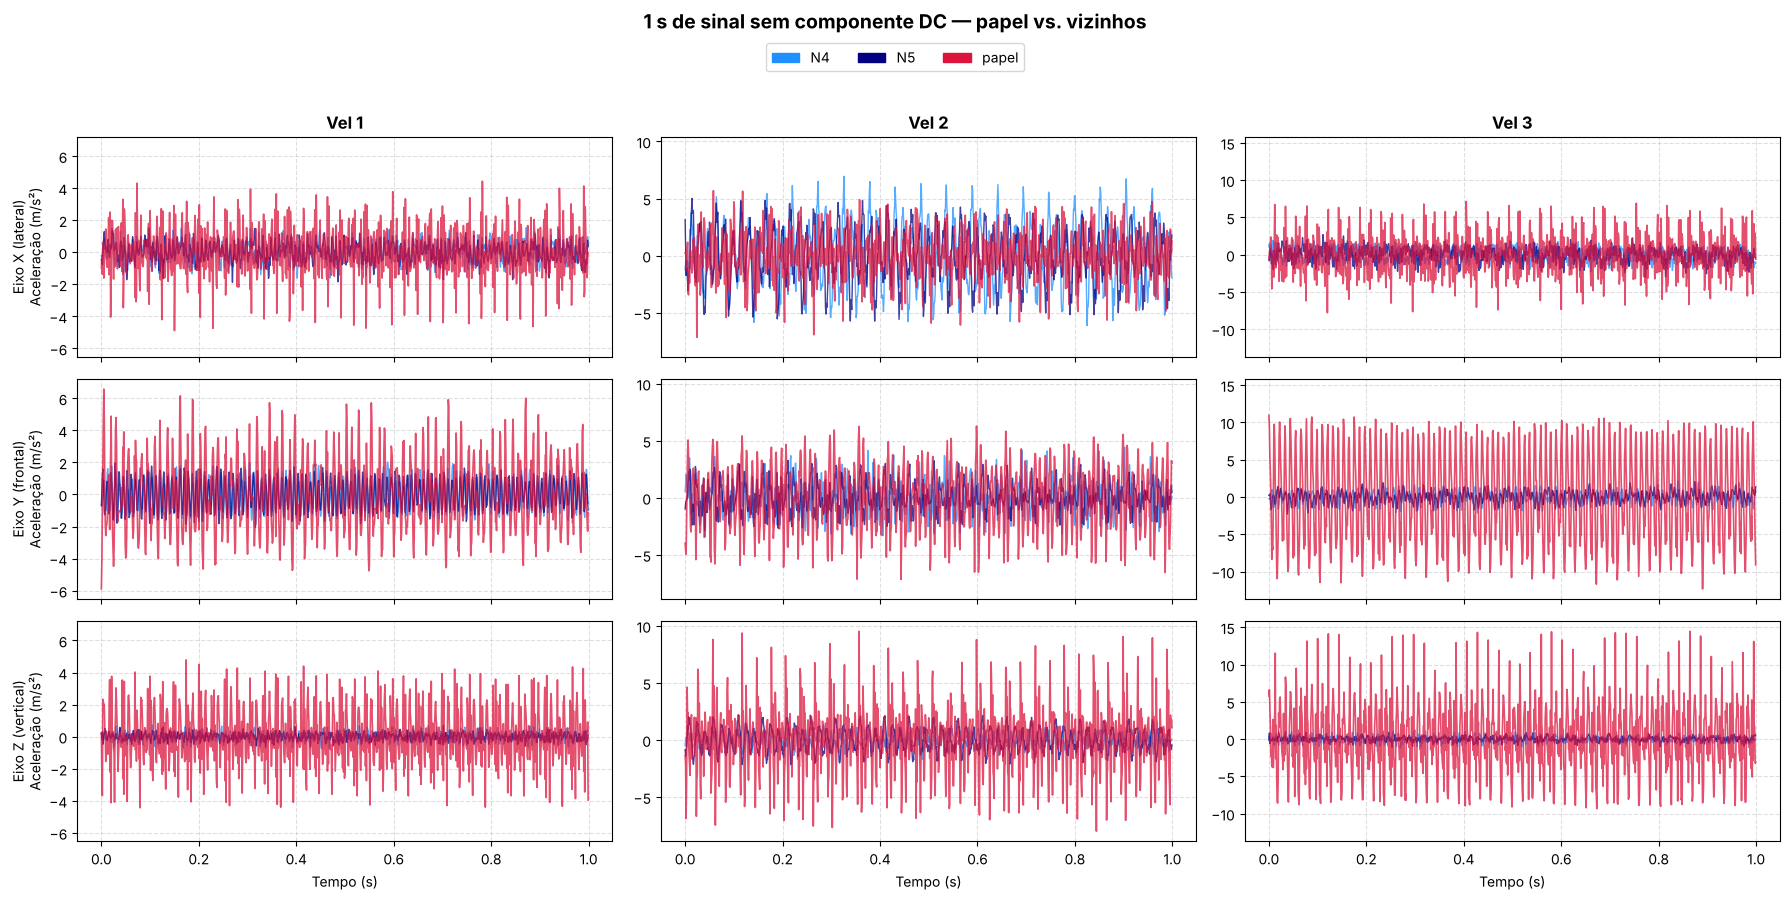

In [10]:
for condicao in condicoes_comparadas:
    plotar_sinal_comparado(bases, catalogo, condicao, velocidades, vizinhos, inicio_s=INICIO_TRECHO_S)

### O que encontramos no Passo 4

* **Fita 0,5 g:** na Vel 2 o sinal chega a cerca de ±15–20 m/s² nos três eixos, contra cerca de ±3–5 dos vizinhos. Na Vel 3 aparecem **impactos regulares**, com picos negativos de cerca de −7,5 m/s² no eixo X e picos positivos de cerca de +6 no eixo Y. Na Vel 1 a fita só se nota por picos um pouco maiores (cerca de ±2,5 contra ±1,5).
* **Fita 1 g:** o mesmo desenho, mais forte (pela tabela do Passo 5, o pico de X na Vel 2 vai de cerca de 7 para cerca de 26 m/s²).
* **Papel:** a mais visível na Vel 1 (picos de cerca de ±4–6 m/s², contra ±1,5 dos vizinhos) e na Vel 3, com uma sequência densa de impactos no eixo Y (cerca de ±10) e no eixo Z (cerca de ±14). Na Vel 2, no eixo X, o papel fica **parecido** com os vizinhos; ele aparece nos eixos Y e Z.
* **Calço:** nas Vel 1 e 2 as três curvas se sobrepõem. **Na Vel 3 o calço tem picos negativos um pouco maiores nos eixos X e Z** (até cerca de −3 a −4 m/s², contra cerca de −2 dos vizinhos). É a primeira pista de que o calço aparece mais na Vel 3.

## Passo 5 — Features de tempo: desvio padrão, curtose e pico

**O que buscamos:** descobrir **quais features de tempo mudam com a anomalia, para que lado e quanto**, em cada velocidade, e se essa mudança é **maior do que a variação natural do normal**.

| Feature | O que mede | Se a anomalia aumentar... |
| --- | --- | --- |
| Desvio padrão (`std`) | Intensidade geral da vibração | A máquina vibra mais |
| Pico (`pico`) | Maior valor absoluto da janela | Há batidas ou picos mais fortes |
| Curtose (`kurt`) | **Forma** da onda, não o tamanho. Perto de 0 é uma onda "comum"; alta indica picos isolados (impactos); negativa indica onda mais regular | A onda ficou mais "pontuda" |

### 5.1 — Boxplots

Em cada gráfico há **três caixas por velocidade**: **cinza** (os 5 normais juntos), **azul** (os dois vizinhos) e **vermelha** (a anomalia). A caixa cobre os 50% centrais das janelas e a linha preta é a mediana.

* **Caixa vermelha fora da cinza e da azul:** a feature distingue a anomalia do normal.
* **Caixa vermelha fora da azul, mas dentro da cinza:** a anomalia difere dos vizinhos, mas fica dentro do que o normal faz em outros momentos da sessão. Cuidado.

### 5.2 — Medianas

Os mesmos números, em tabela: 5 normais, vizinhos e anomalia.

### 5.3 — Mapa de separação

Cada linha é uma feature e cada quadrado mostra a **separação** (−1 a +1; vermelho = anomalia maior, azul = menor). As colunas vêm em **quatro blocos** de três velocidades:

| Bloco | O que mostra | Como ler |
| --- | --- | --- |
| **contra 5 normais** | anomalia × os 5 lotes juntos | a diferença global |
| **controle: lote × resto** | a maior separação (sem sinal) de um lote normal contra os outros 4 | o quanto **um normal** foge dos outros sozinho |
| **contra vizinhos** | anomalia × os dois vizinhos juntos | a diferença local |
| **controle: viz. × viz.** | o vizinho de depois contra o de antes | o quanto o normal mudou naquele trecho da sessão |

**Como interpretar:** cor forte num bloco de comparação e cor fraca no seu controle = a diferença vem da anomalia. Cor forte nos dois = o normal já muda sozinho tanto quanto, e a feature não é confiável naquela velocidade.

In [11]:
def plotar_boxplots_comparativo(features, condicao, linhas, velocidades, vizinhos, blocos_normais):
    """Grade (linhas = tipos de feature, colunas = eixos), com três caixas por velocidade: 5 normais, vizinhos e anomalia.

    linhas: lista de (prefixo, título, unidade), por exemplo ("std", "Desvio padrão", "m/s²").
    """
    grupos = [(-0.28, blocos_normais, COR_NORMAIS, "5 normais"),
              (0.0, vizinhos[condicao], COR_VIZINHOS, "vizinhos (" + " e ".join(vizinhos[condicao]) + ")"),
              (0.28, [condicao], COR_COMPARADA, condicao)]
    fig, axs = plt.subplots(len(linhas), len(EIXOS), figsize=(18, 3.6 * len(linhas)), squeeze=False)
    for i, (prefixo, titulo, unidade) in enumerate(linhas):
        for j, eixo in enumerate(EIXOS):
            ax = axs[i, j]
            for k, velocidade in enumerate(velocidades):
                for deslocamento, blocos, cor, _ in grupos:
                    valores = selecionar_janelas(features, blocos, velocidade)[f"{prefixo}_{eixo}"]
                    if len(valores) == 0:
                        continue
                    caixa = ax.boxplot(valores, positions=[k + deslocamento], widths=0.24, patch_artist=True,
                                       manage_ticks=False, flierprops={"markersize": 3, "alpha": 0.5})
                    for parte in caixa["boxes"]:
                        parte.set_facecolor(cor)
                        parte.set_alpha(0.75)
                    for mediana in caixa["medians"]:
                        mediana.set_color("black")
            ax.set_xticks(range(len(velocidades)))
            ax.set_xticklabels([f"Vel {v}" for v in velocidades])
            ax.set_title(f"{titulo} — {NOMES_EIXOS[eixo]}", fontsize=11, fontweight="bold")
            ax.set_ylabel(unidade)
    fig.legend(handles=[Patch(color=cor, label=rotulo) for _, _, cor, rotulo in grupos],
               loc="upper center", ncol=3, fontsize=10, bbox_to_anchor=(0.5, 1.0 - 0.1 / len(linhas)))
    fig.suptitle(f"{condicao} vs. normal", fontsize=14, fontweight="bold", y=0.995)
    plt.tight_layout(rect=[0, 0, 1, 1.0 - 0.17 / len(linhas)])
    plt.show()


def montar_tabela_de_medianas(features, condicao, colunas, velocidades, vizinhos, blocos_normais):
    """Mediana de cada feature, por velocidade, nos 5 normais, nos vizinhos e na anomalia."""
    tabela = {}
    for velocidade in velocidades:
        tabela[(f"Vel {velocidade}", "5 normais")] = selecionar_janelas(features, blocos_normais, velocidade)[colunas].median()
        tabela[(f"Vel {velocidade}", "vizinhos")] = selecionar_janelas(features, vizinhos[condicao], velocidade)[colunas].median()
        tabela[(f"Vel {velocidade}", "anomalia")] = selecionar_janelas(features, [condicao], velocidade)[colunas].median()
    return pd.DataFrame(tabela)


BLOCOS_DO_MAPA = [("sep_5_normais", "contra 5 normais"), ("controle_lote_resto", "controle: lote × resto"),
                  ("sep_vizinhos", "contra vizinhos"), ("viz_x_viz", "controle: viz. × viz.")]


def montar_matriz_de_separacao(features, condicao, colunas, velocidades, vizinhos, blocos_normais):
    """Matriz (feature x [4 blocos de velocidades]) com as separações e os controles (ver BLOCOS_DO_MAPA)."""
    comparacoes = {v: comparar_com_os_normais(features, condicao, v, colunas, vizinhos, blocos_normais) for v in velocidades}
    return pd.DataFrame({(titulo, f"V{v}"): comparacoes[v][coluna] for coluna, titulo in BLOCOS_DO_MAPA for v in velocidades})


def plotar_mapa_de_separacao(matriz, titulo):
    """Mapa de cores (vermelho = anomalia maior, azul = menor), com o valor em cada célula e os blocos separados."""
    blocos = list(dict.fromkeys(matriz.columns.get_level_values(0)))
    por_bloco = matriz.shape[1] // len(blocos)
    fig, ax = plt.subplots(figsize=(1.05 * matriz.shape[1] + 3, 0.42 * matriz.shape[0] + 2.4))
    imagem = ax.imshow(matriz.to_numpy(dtype=float), cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
    ax.set_xticks(range(matriz.shape[1]))
    ax.set_xticklabels(matriz.columns.get_level_values(1))
    ax.set_yticks(range(matriz.shape[0]))
    ax.set_yticklabels(matriz.index)
    ax.grid(False)
    for b, nome in enumerate(blocos):
        if b:
            ax.axvline(b * por_bloco - 0.5, color="black", linewidth=2 if b % 2 == 0 else 0.8)
        ax.text(b * por_bloco + (por_bloco - 1) / 2, -0.8, nome, ha="center", va="bottom", fontsize=10, fontweight="bold")
    for i in range(matriz.shape[0]):
        for j in range(matriz.shape[1]):
            valor = matriz.iat[i, j]
            if not np.isnan(valor):
                ax.text(j, i, f"{valor:.2f}", ha="center", va="center", fontsize=8,
                        color="white" if abs(valor) > 0.6 else "black")
    fig.colorbar(imagem, ax=ax, label="separação (+ anomalia maior, − anomalia menor)")
    ax.set_title(titulo, fontsize=12, fontweight="bold", pad=26)
    plt.tight_layout()
    plt.show()

### 5.1 a 5.3 — Para cada anomalia

==================== calco vs. normal (vizinhos: N1 e N2) ====================


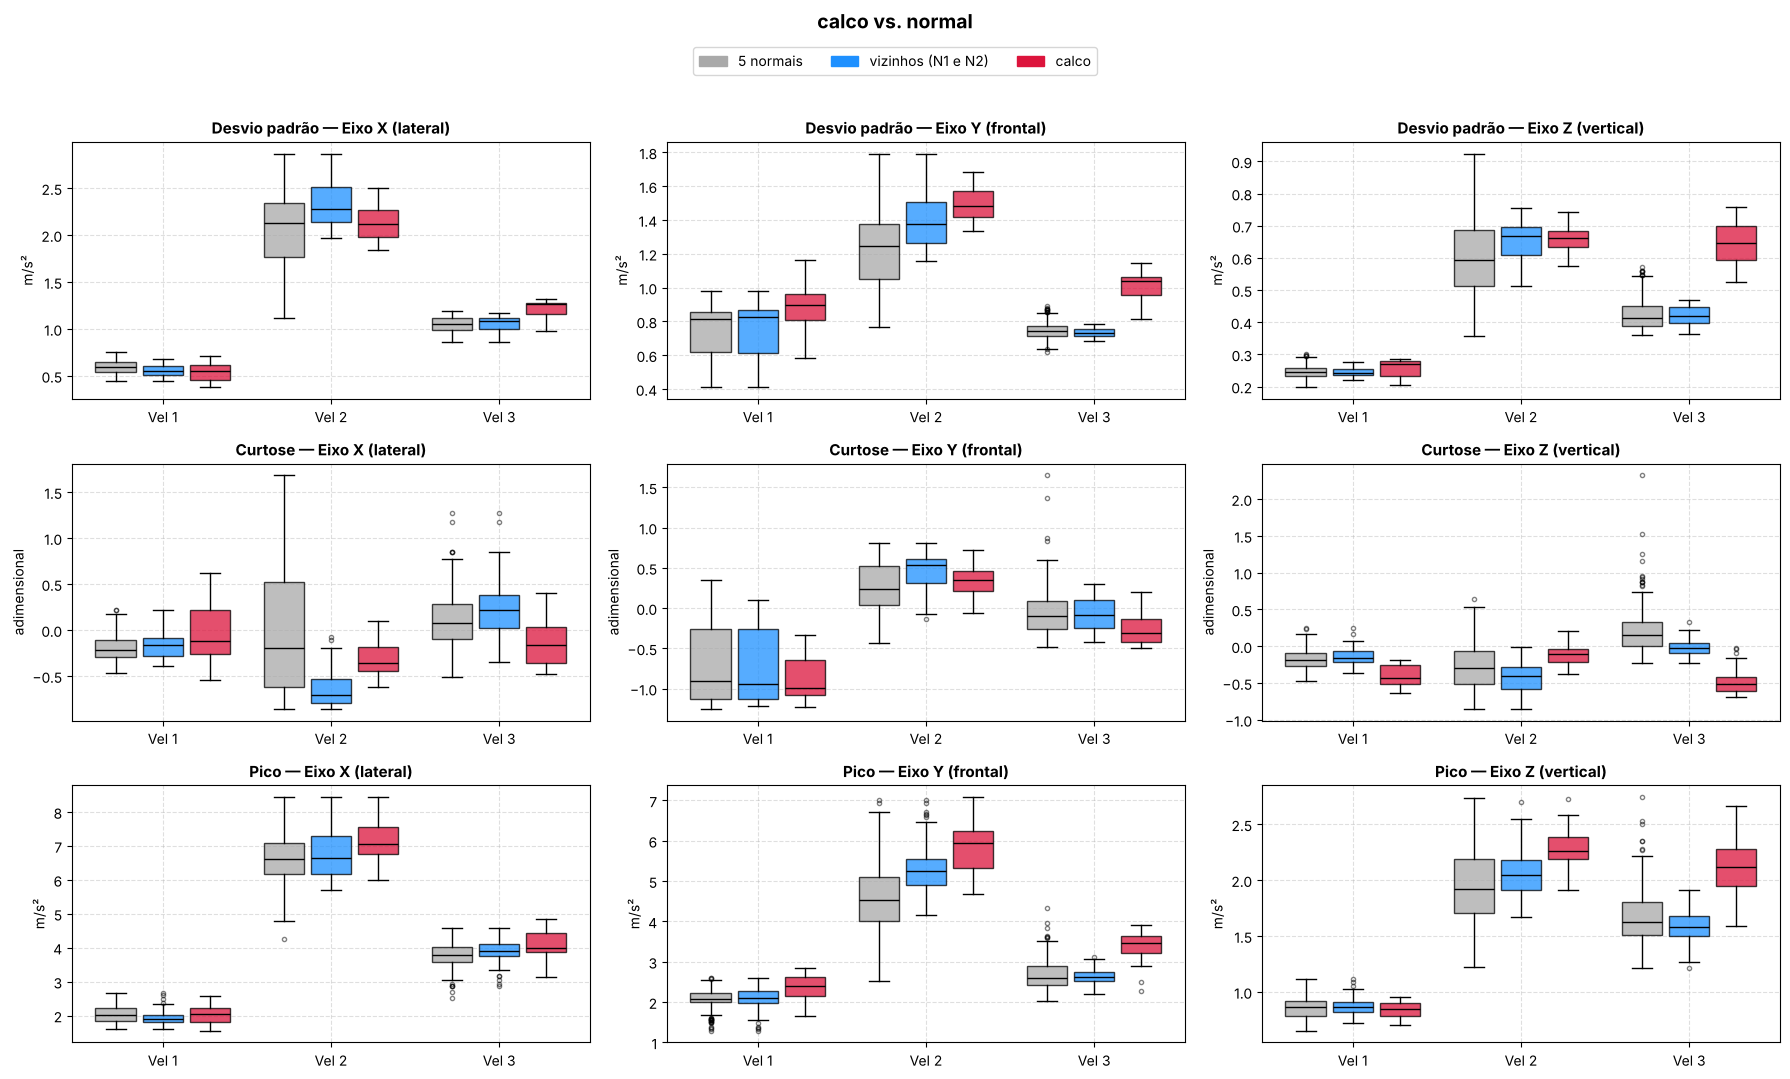

Medianas de cada feature de tempo:


Vel 1                       Vel 2                       Vel 3                  
       5 normais vizinhos anomalia 5 normais vizinhos anomalia 5 normais vizinhos anomalia
std_x      0.597    0.550    0.552     2.131    2.275    2.121     1.051    1.086    1.263
std_y      0.812    0.828    0.898     1.246    1.378    1.485     0.745    0.733    1.039
std_z      0.244    0.242    0.271     0.593    0.667    0.661     0.412    0.419    0.648
kurt_x    -0.219   -0.161   -0.118    -0.196   -0.711   -0.353     0.072    0.213   -0.158
kurt_y    -0.910   -0.949   -0.990     0.240    0.532    0.350    -0.100   -0.082   -0.314
kurt_z    -0.192   -0.165   -0.437    -0.300   -0.399   -0.102     0.158   -0.028   -0.512
pico_x     2.002    1.907    2.040     6.611    6.636    7.048     3.795    3.903    4.003
pico_y     2.084    2.108    2.399     4.535    5.256    5.943     2.608    2.623    3.462
pico_z     0.864    0.867    0.844     1.917    2.046    2.262     1.626    1.580    2.118

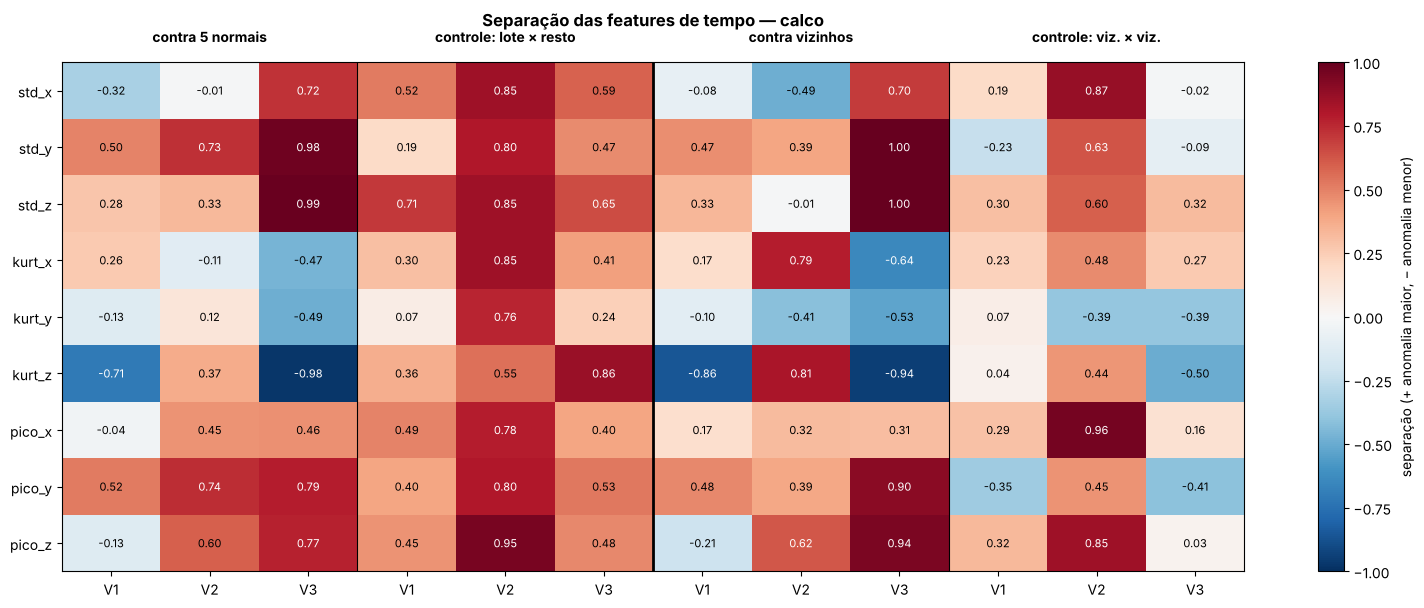

==================== fita_1g vs. normal (vizinhos: N2 e N3) ====================


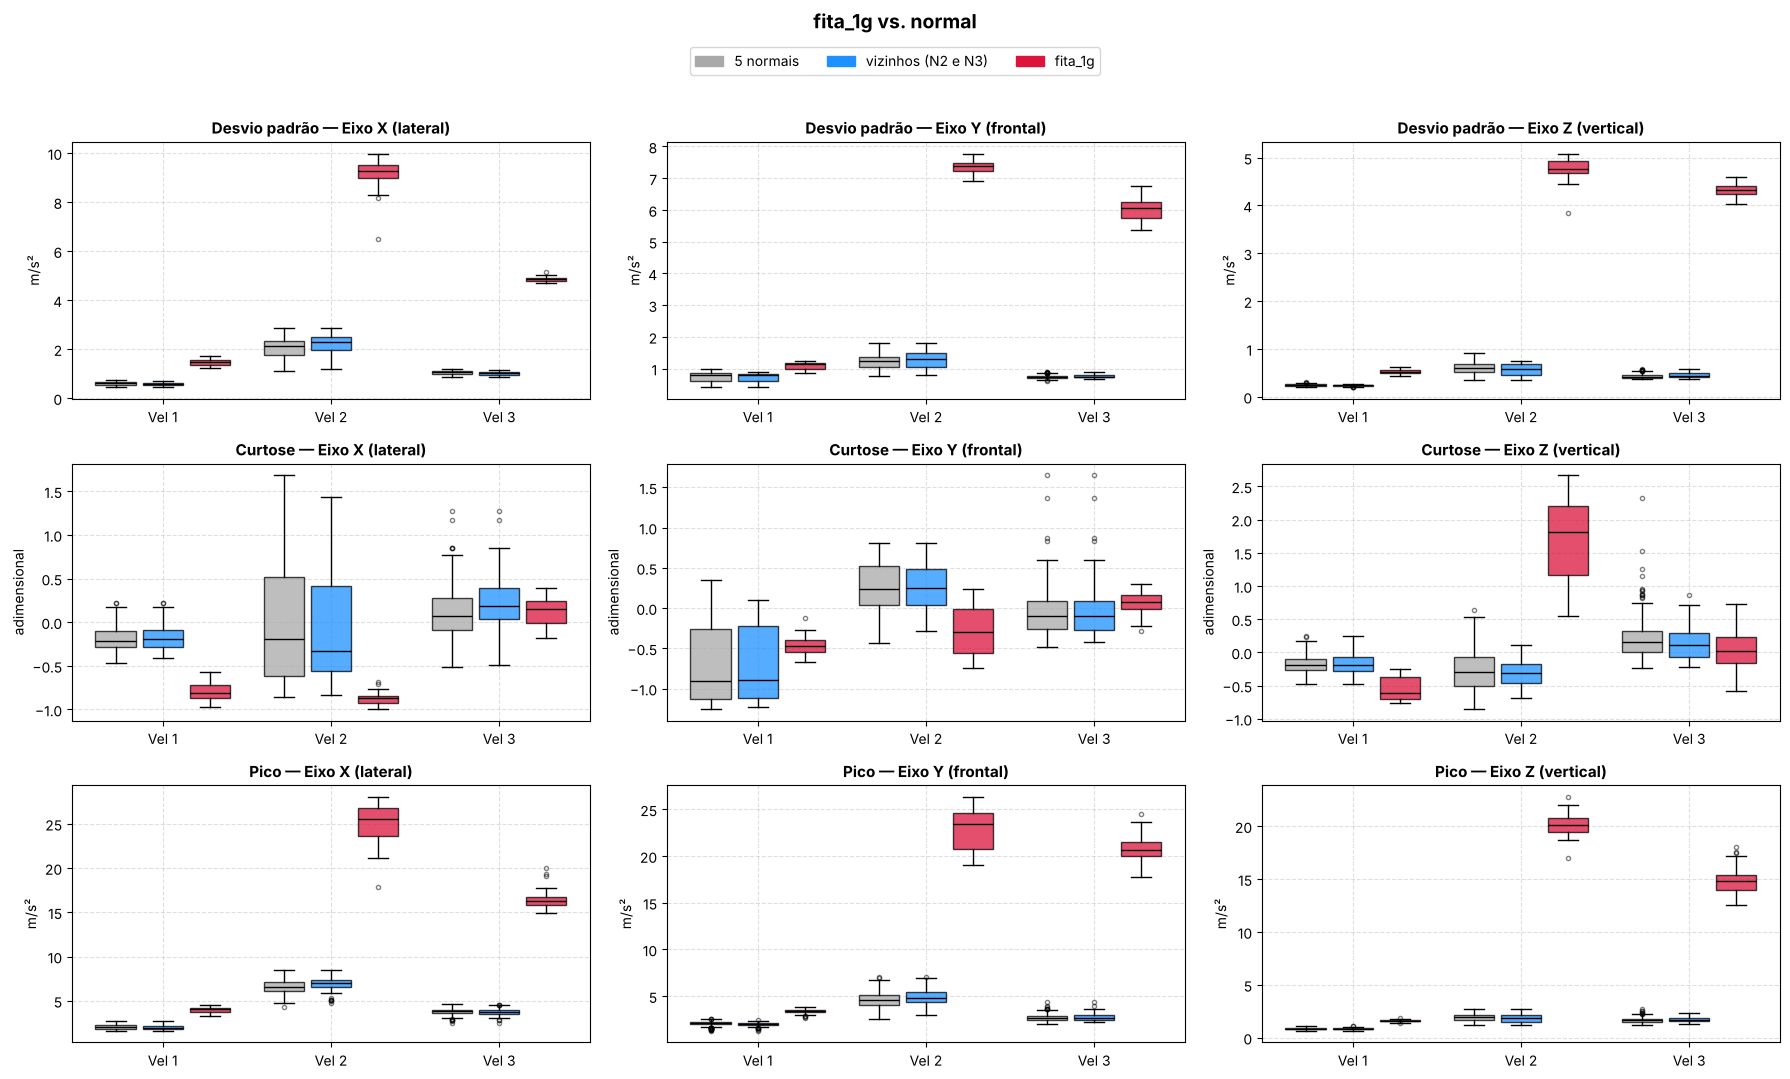

Medianas de cada feature de tempo:


Vel 1                       Vel 2                       Vel 3                  
       5 normais vizinhos anomalia 5 normais vizinhos anomalia 5 normais vizinhos anomalia
std_x      0.597    0.592    1.469     2.131    2.288    9.260     1.051    1.013    4.855
std_y      0.812    0.798    1.141     1.246    1.310    7.388     0.745    0.749    6.055
std_z      0.244    0.242    0.509     0.593    0.581    4.772     0.412    0.438    4.321
kurt_x    -0.219   -0.194   -0.810    -0.196   -0.332   -0.872     0.072    0.187    0.153
kurt_y    -0.910   -0.898   -0.467     0.240    0.248   -0.295    -0.100   -0.101    0.082
kurt_z    -0.192   -0.192   -0.612    -0.300   -0.315    1.815     0.158    0.104    0.024
pico_x     2.002    1.971    4.030     6.611    6.981   25.588     3.795    3.781   16.284
pico_y     2.084    2.046    3.413     4.535    4.774   23.440     2.608    2.631   20.600
pico_z     0.864    0.854    1.620     1.917    1.838   20.076     1.626    1.693   14.799

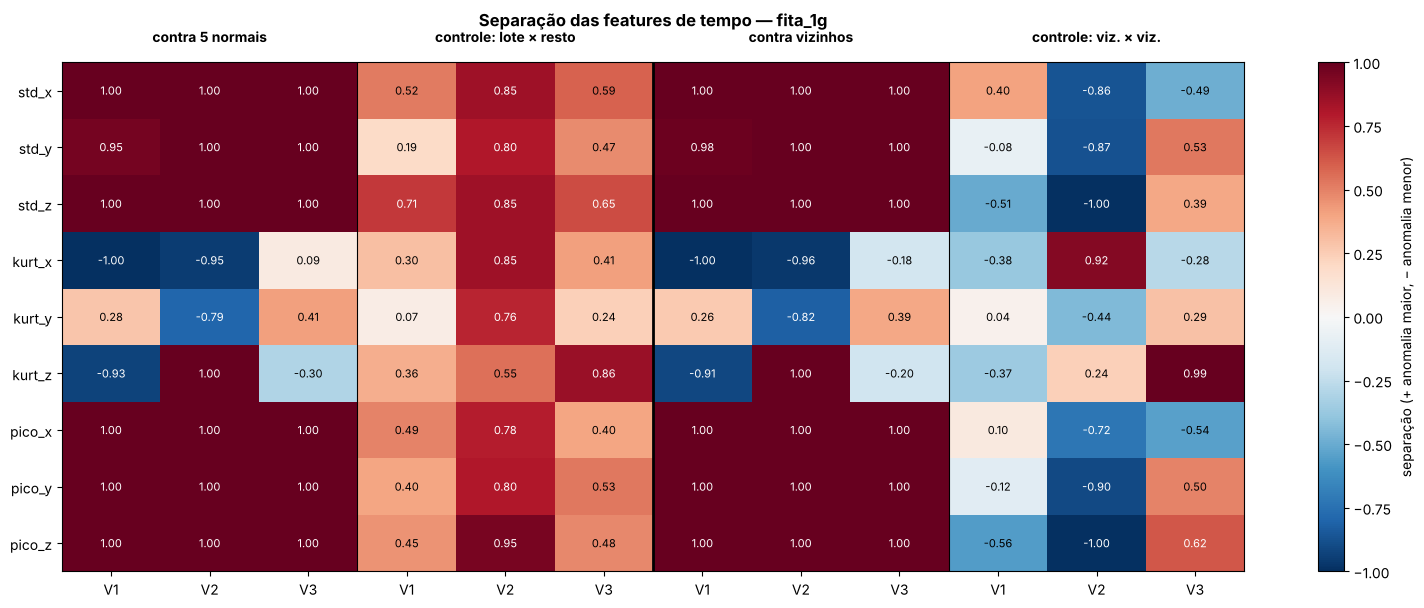

==================== fita_05g vs. normal (vizinhos: N3 e N4) ====================


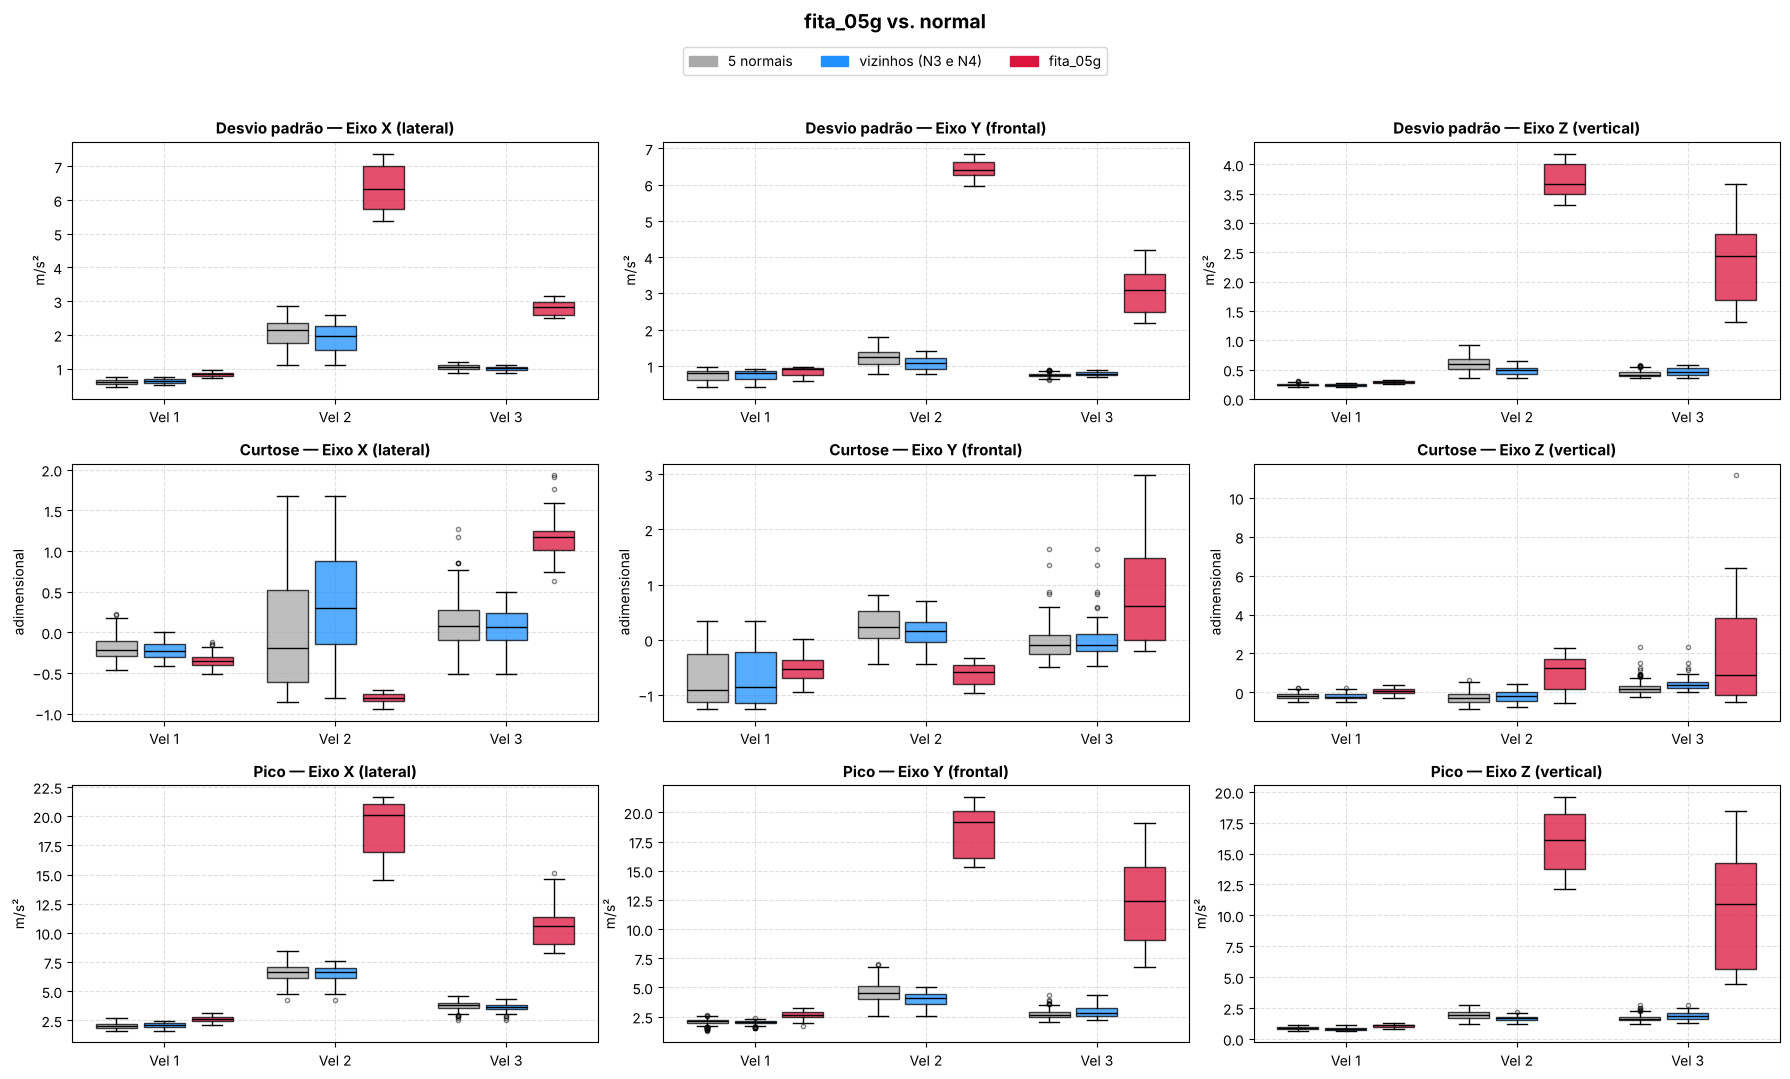

Medianas de cada feature de tempo:


Vel 1                       Vel 2                       Vel 3                  
       5 normais vizinhos anomalia 5 normais vizinhos anomalia 5 normais vizinhos anomalia
std_x      0.597    0.621    0.828     2.131    1.959    6.325     1.051    1.011    2.830
std_y      0.812    0.791    0.914     1.246    1.067    6.402     0.745    0.770    3.088
std_z      0.244    0.239    0.296     0.593    0.488    3.659     0.412    0.455    2.436
kurt_x    -0.219   -0.235   -0.347    -0.196    0.301   -0.806     0.072    0.066    1.173
kurt_y    -0.910   -0.860   -0.524     0.240    0.154   -0.590    -0.100   -0.101    0.605
kurt_z    -0.192   -0.221    0.069    -0.300   -0.182    1.253     0.158    0.367    0.881
pico_x     2.002    2.124    2.583     6.611    6.611   20.083     3.795    3.637   10.610
pico_y     2.084    2.057    2.672     4.535    4.098   19.194     2.608    2.825   12.442
pico_z     0.864    0.823    1.099     1.917    1.660   16.116     1.626    1.860   10.893

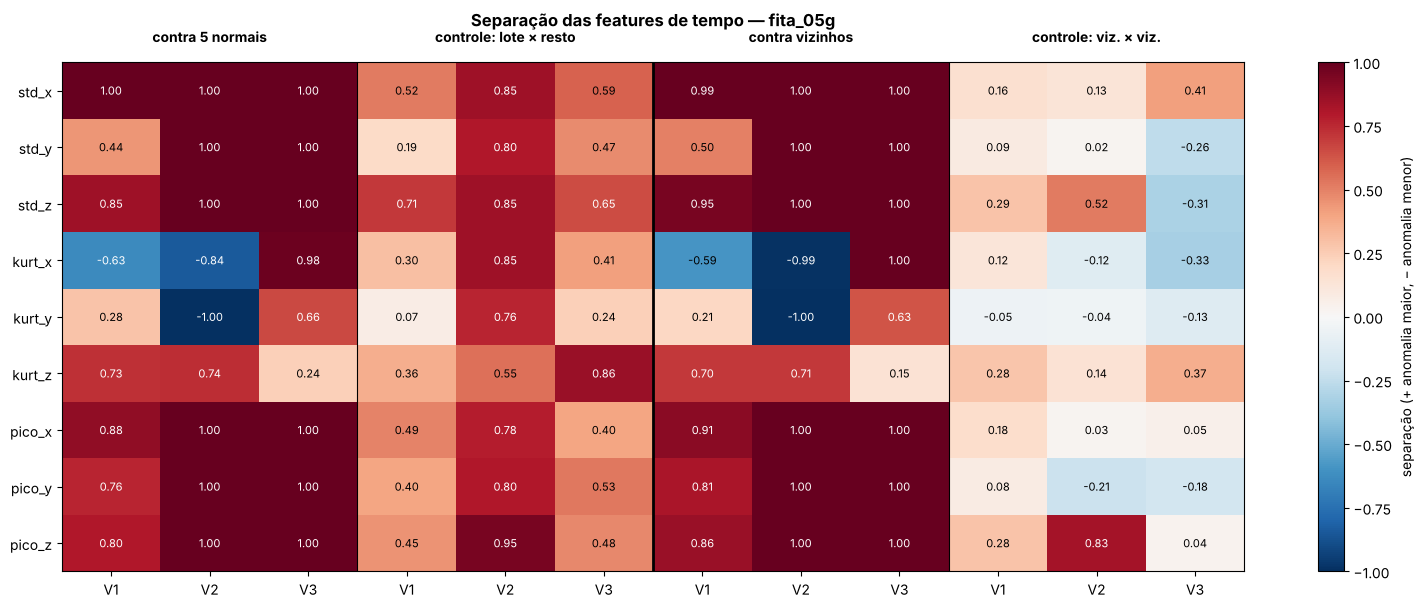

==================== papel vs. normal (vizinhos: N4 e N5) ====================


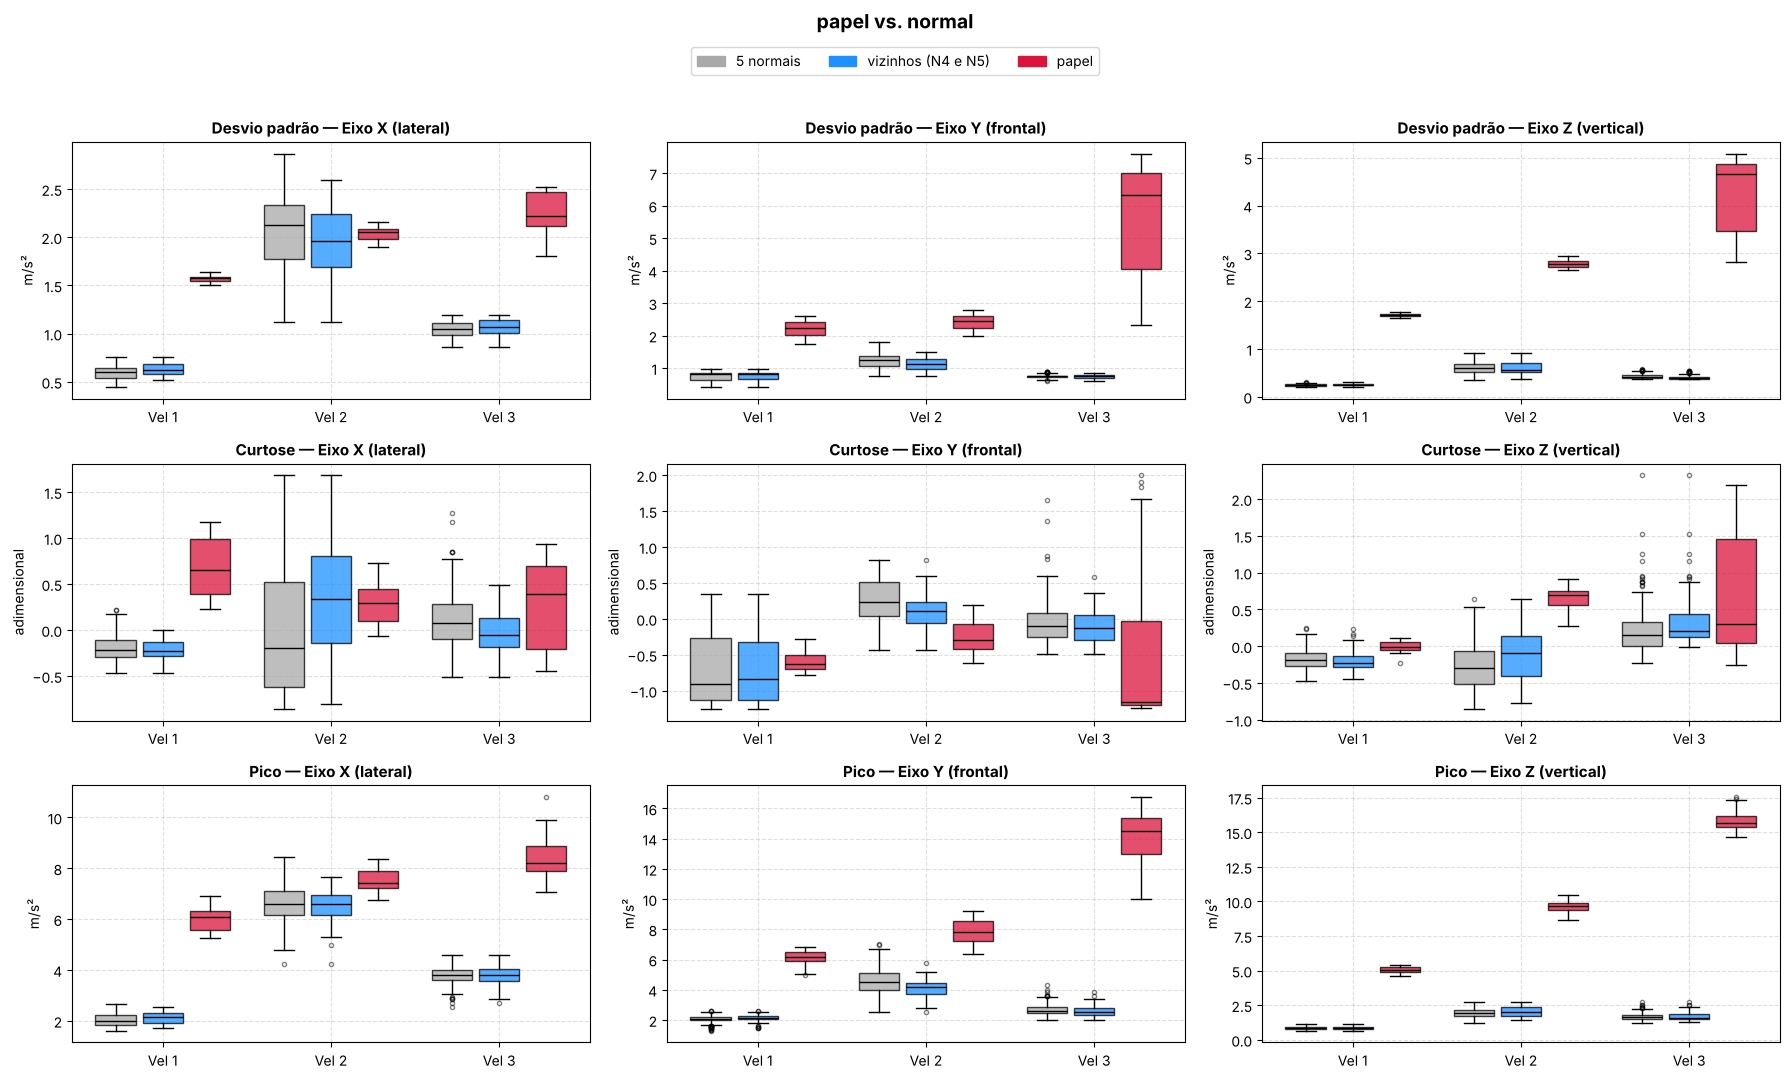

Medianas de cada feature de tempo:


Vel 1                       Vel 2                       Vel 3                  
       5 normais vizinhos anomalia 5 normais vizinhos anomalia 5 normais vizinhos anomalia
std_x      0.597    0.619    1.572     2.131    1.966    2.051     1.051    1.071    2.223
std_y      0.812    0.809    2.242     1.246    1.121    2.451     0.745    0.745    6.326
std_z      0.244    0.253    1.711     0.593    0.563    2.777     0.412    0.394    4.660
kurt_x    -0.219   -0.228    0.653    -0.196    0.339    0.297     0.072   -0.052    0.394
kurt_y    -0.910   -0.830   -0.620     0.240    0.115   -0.295    -0.100   -0.129   -1.161
kurt_z    -0.192   -0.224   -0.006    -0.300   -0.094    0.702     0.158    0.213    0.300
pico_x     2.002    2.160    6.098     6.611    6.601    7.417     3.795    3.805    8.221
pico_y     2.084    2.108    6.187     4.535    4.161    7.855     2.608    2.558   14.536
pico_z     0.864    0.888    5.055     1.917    2.009    9.650     1.626    1.609   15.646

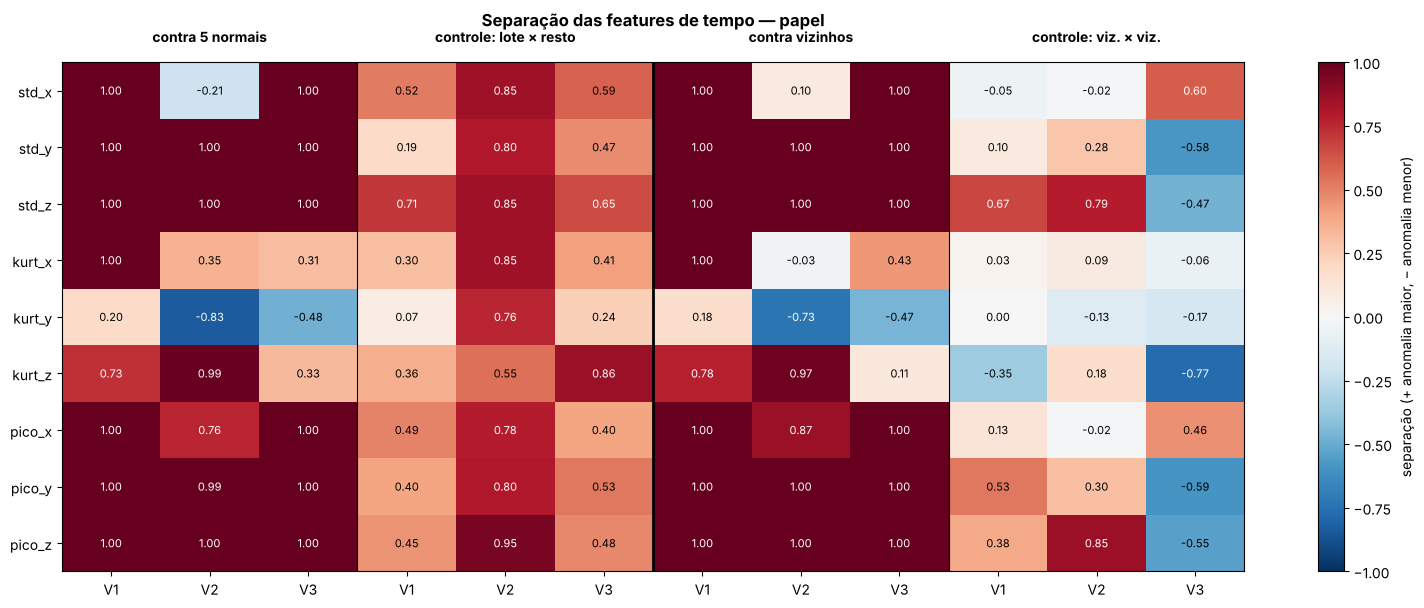

In [12]:
LINHAS_TEMPO = [("std", "Desvio padrão", UNIDADE), ("kurt", "Curtose", "adimensional"), ("pico", "Pico", UNIDADE)]

for condicao in condicoes_comparadas:
    print(f"==================== {condicao} vs. normal (vizinhos: {' e '.join(vizinhos[condicao])}) ====================")
    plotar_boxplots_comparativo(features, condicao, LINHAS_TEMPO, velocidades, vizinhos, BLOCOS_NORMAIS)
    print("Medianas de cada feature de tempo:")
    display(montar_tabela_de_medianas(features, condicao, COLUNAS_TEMPO, velocidades, vizinhos, BLOCOS_NORMAIS).round(3))
    matriz = montar_matriz_de_separacao(features, condicao, COLUNAS_TEMPO, velocidades, vizinhos, BLOCOS_NORMAIS)
    plotar_mapa_de_separacao(matriz, f"Separação das features de tempo — {condicao}")

### O que encontramos no Passo 5

**Fita 1 g (vizinhos N2 e N3):** separação de 1,00 contra os vizinhos em `std` e `pico` nas três velocidades. Vel 1: `std_x` de 0,59 para 1,47 (2,5 vezes). Vel 2: `std_x` de 2,29 para 9,26 (4 vezes) e `pico_x` de 7,0 para 25,6. Vel 3: `std_y` de 0,75 para 6,06 (8 vezes).

**Fita 0,5 g (vizinhos N3 e N4):** o mesmo padrão, menor. Vel 1: `std_x` de 0,62 para 0,83 (1,3 vez). Vel 2: `std_y` de 1,07 para 6,40 (6 vezes). Vel 3: `std_x` de 1,01 para 2,83 (2,8 vezes), com a curtose de X subindo de 0,07 para 1,17 (os impactos do Passo 4).

**Papel (vizinhos N4 e N5):** Vel 1: `std_z` de 0,25 para 1,71 (6,8 vezes). Vel 2: `std_x` **igual** aos vizinhos (1,97 contra 2,05), mas `std_z` de 0,56 para 2,78 (4,9 vezes). Vel 3: `std_y` de 0,75 para 6,33 (8,5 vezes).

**Calço (vizinhos N1 e N2):**
* **Vel 3:** `std_y` de 0,73 para 1,04 e `std_z` de 0,42 para 0,65, com separação de 1,00 contra os vizinhos e de 0,98 a 0,99 contra os 5 normais. O controle "lote × resto" dessas features fica em 0,47 e 0,65, ou seja, **nenhum lote normal foge tanto dos outros nelas**.
* **Vel 1 e 2:** diferenças pequenas no `std` (separação até 0,49 contra os vizinhos). O que muda é a **curtose de Z**, que fica menor na Vel 1 (−0,44 contra −0,17; separação −0,86); na Vel 2 ela sobe (0,81), mas nessa velocidade os próprios vizinhos diferem bastante (controle viz. × viz. de 0,39 a 0,96, em módulo, nas features de tempo).
* **Mapa:** nas Vel 1 e 2, o bloco "controle: lote × resto" tem cor tão forte quanto o bloco "contra 5 normais" (na Vel 2 vai até 0,95). **Só no tempo, o calço nas Vel 1 e 2 fica dentro do que o normal faz sozinho.**

## Passo 6 — Espectro médio: normal sobre anomalia

**O que buscamos:** ver **em quais frequências** a anomalia aparece. Usamos **todas as janelas** de cada grupo: a linha é a **média** do espectro e a faixa sombreada vai do percentil 10 ao 90.

* **Cinza:** a faixa (percentis 10 a 90) dos **5 normais juntos**, ou seja, tudo o que o normal fez ao longo da sessão.
* **Azul:** média e faixa dos **dois vizinhos**.
* **Vermelho:** média e faixa da **anomalia**.
* **Linhas pontilhadas:** 120 e 240 Hz, as linhas elétricas confirmadas pelo orientador.

Como ler: picos vermelhos que **não existem** no azul nem no cinza são frequências novas da anomalia. Picos nas mesmas frequências, mas mais altos que a faixa cinza, indicam a mesma vibração mais forte. Cada coluna (velocidade) compartilha a escala vertical entre os três eixos.

In [13]:
def resumir_espectros(espectros):
    """Média e percentis 10 e 90 de um conjunto de espectros (janela, frequência, eixo)."""
    return espectros.mean(axis=0), np.percentile(espectros, 10, axis=0), np.percentile(espectros, 90, axis=0)


def plotar_espectros_comparados(features, frequencias, espectros_por_base, condicao, velocidades, vizinhos, blocos_normais):
    """Grade (eixo x velocidade): faixa dos 5 normais (cinza), vizinhos (azul) e anomalia (vermelho)."""
    fig, axs = plt.subplots(len(EIXOS), len(velocidades), figsize=(7 * len(velocidades), 3.2 * len(EIXOS)),
                            sharex=True, sharey="col", squeeze=False)
    visivel = frequencias <= F_MAX_PLOT_HZ
    f = frequencias[visivel]
    for j, velocidade in enumerate(velocidades):
        _, p10, p90 = resumir_espectros(juntar_espectros(espectros_por_base, selecionar_janelas(features, blocos_normais, velocidade)))
        for i in range(len(EIXOS)):
            axs[i, j].fill_between(f, p10[visivel, i], p90[visivel, i], color=COR_NORMAIS, alpha=0.35, linewidth=0)
        for cor, blocos in ((COR_VIZINHOS, vizinhos[condicao]), (COR_COMPARADA, [condicao])):
            janelas = selecionar_janelas(features, blocos, velocidade)
            if len(janelas) == 0:
                continue
            media, p10, p90 = resumir_espectros(juntar_espectros(espectros_por_base, janelas))
            for i in range(len(EIXOS)):
                axs[i, j].fill_between(f, p10[visivel, i], p90[visivel, i], color=cor, alpha=0.2, linewidth=0)
                axs[i, j].plot(f, media[visivel, i], color=cor, linewidth=1.0)
        for i in range(len(EIXOS)):
            for freq in FREQS_REFERENCIA_HZ:
                axs[i, j].axvline(freq, color="black", linestyle=":", linewidth=0.8, alpha=0.6)
        axs[0, j].set_title(f"Vel {velocidade}", fontsize=12, fontweight="bold")
        axs[-1, j].set_xlabel("Frequência (Hz)")
    for i, eixo in enumerate(EIXOS):
        axs[i, 0].set_ylabel(f"{NOMES_EIXOS[eixo]}\nMagnitude ({UNIDADE})")
    if ESCALA_Y_FFT == "log":
        for ax in axs.ravel():
            ax.set_yscale("log")
    fig.legend(handles=[Patch(color=COR_NORMAIS, alpha=0.5, label="5 normais (percentis 10 a 90)"),
                        Patch(color=COR_VIZINHOS, label="vizinhos (" + " e ".join(vizinhos[condicao]) + ")"),
                        Patch(color=COR_COMPARADA, label=condicao),
                        Line2D([], [], color="black", linestyle=":", label="120 e 240 Hz (elétricas)")],
               loc="upper center", ncol=4, fontsize=10, bbox_to_anchor=(0.5, 0.965))
    fig.suptitle(f"Espectro médio com Hanning (faixas = percentis 10 a 90) — {condicao} vs. normal",
                 fontsize=14, fontweight="bold", y=0.995)
    plt.tight_layout(rect=[0, 0, 1, 0.94])
    plt.show()

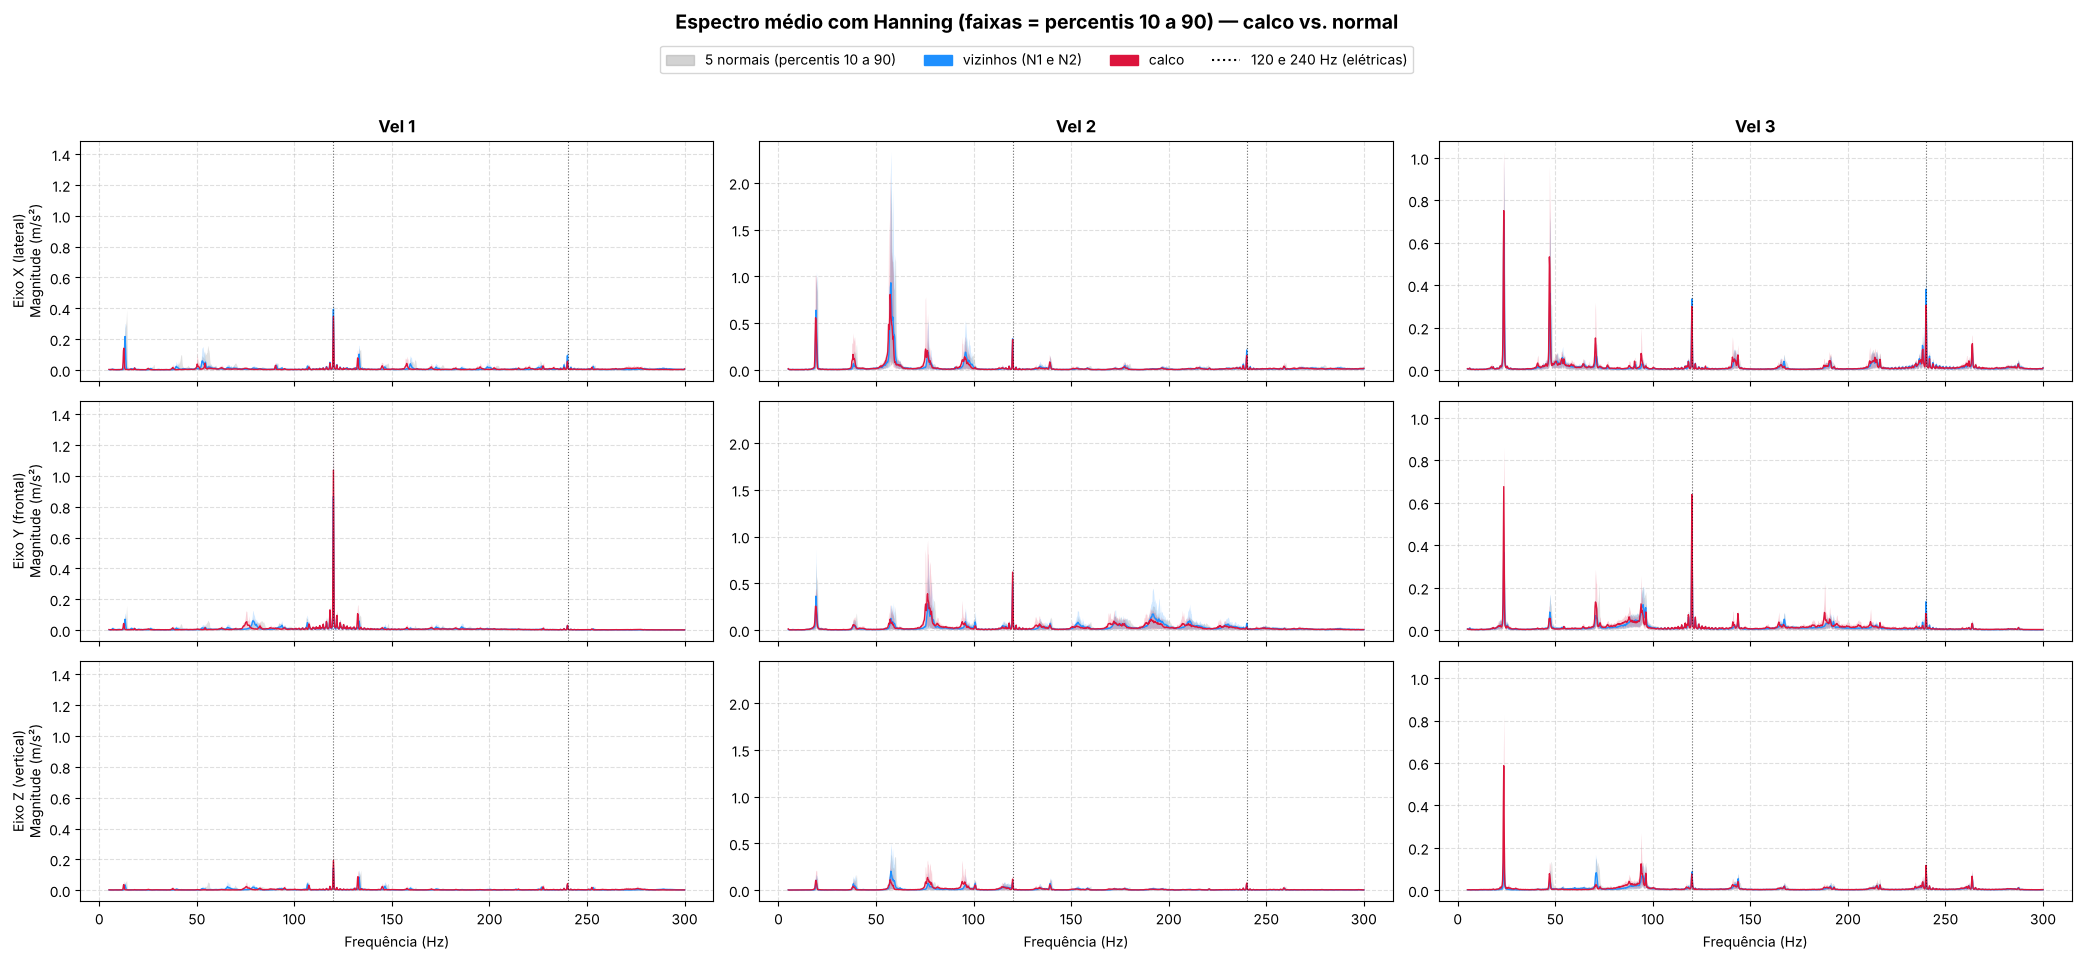

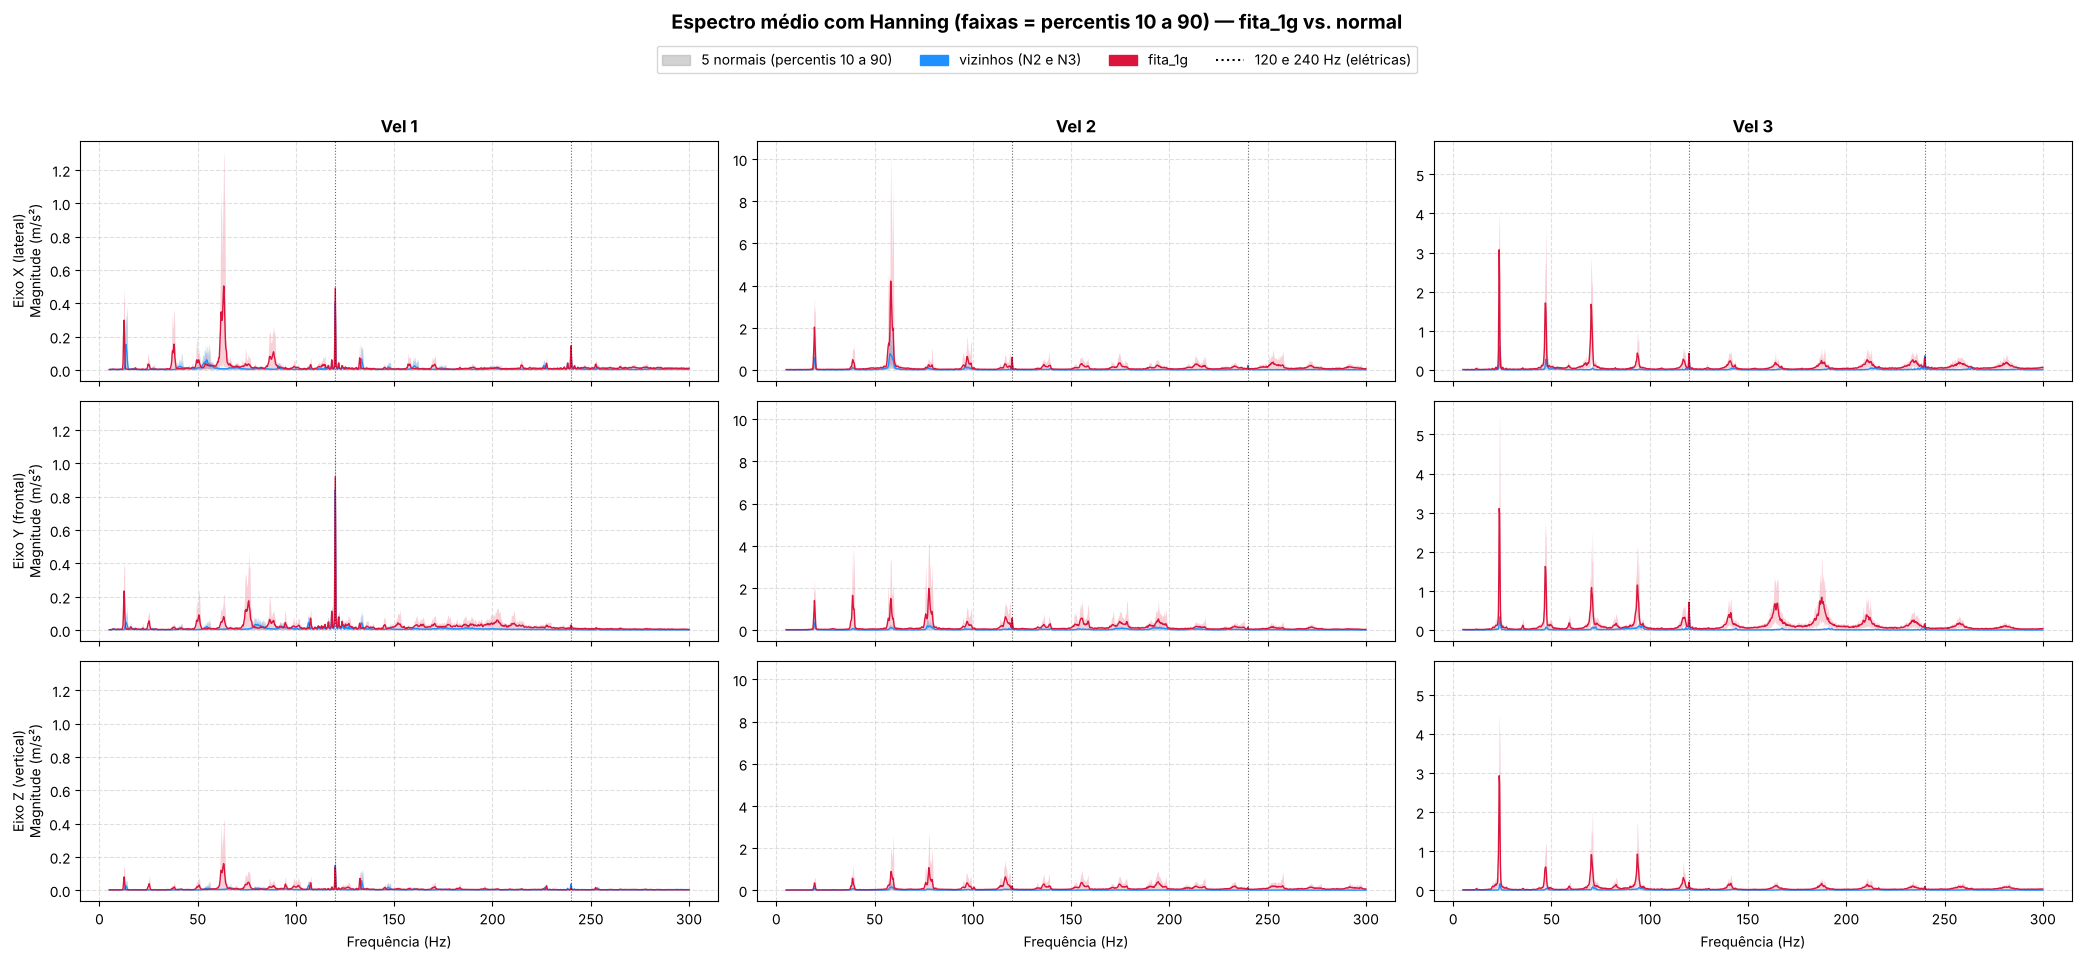

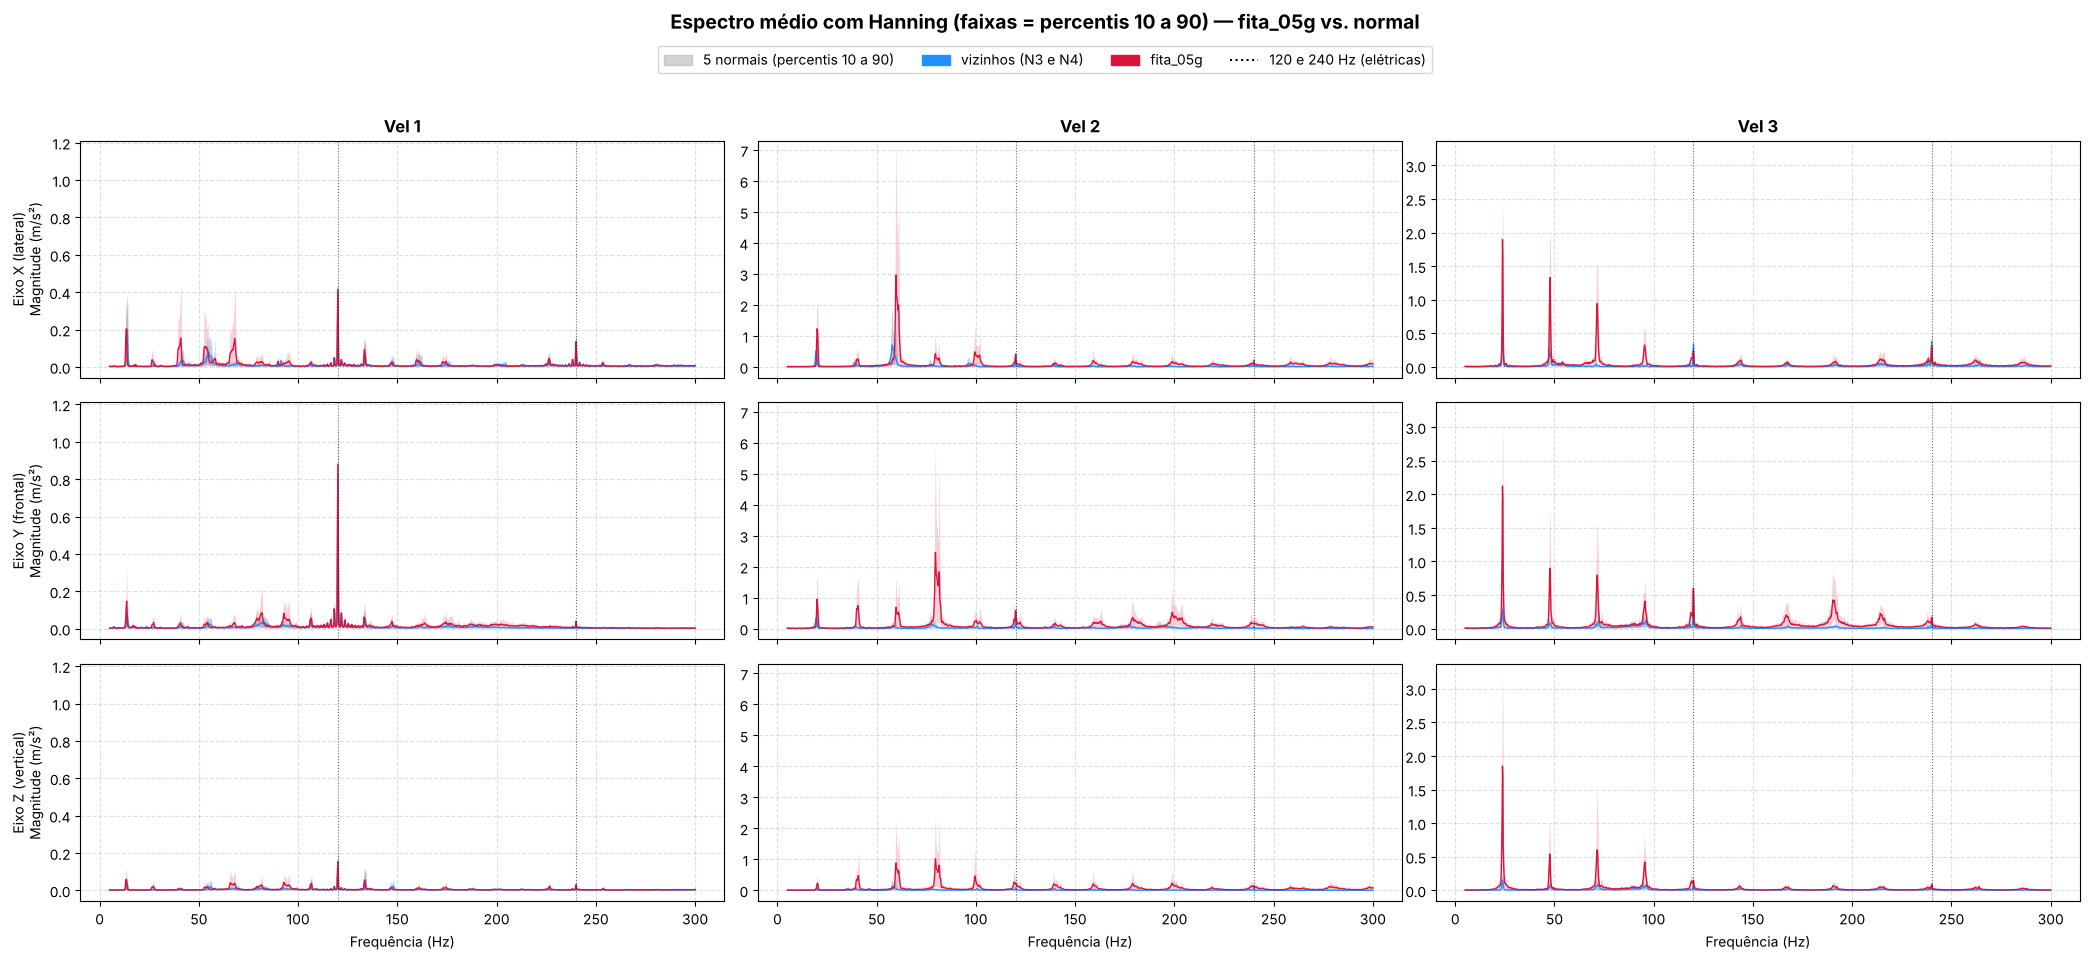

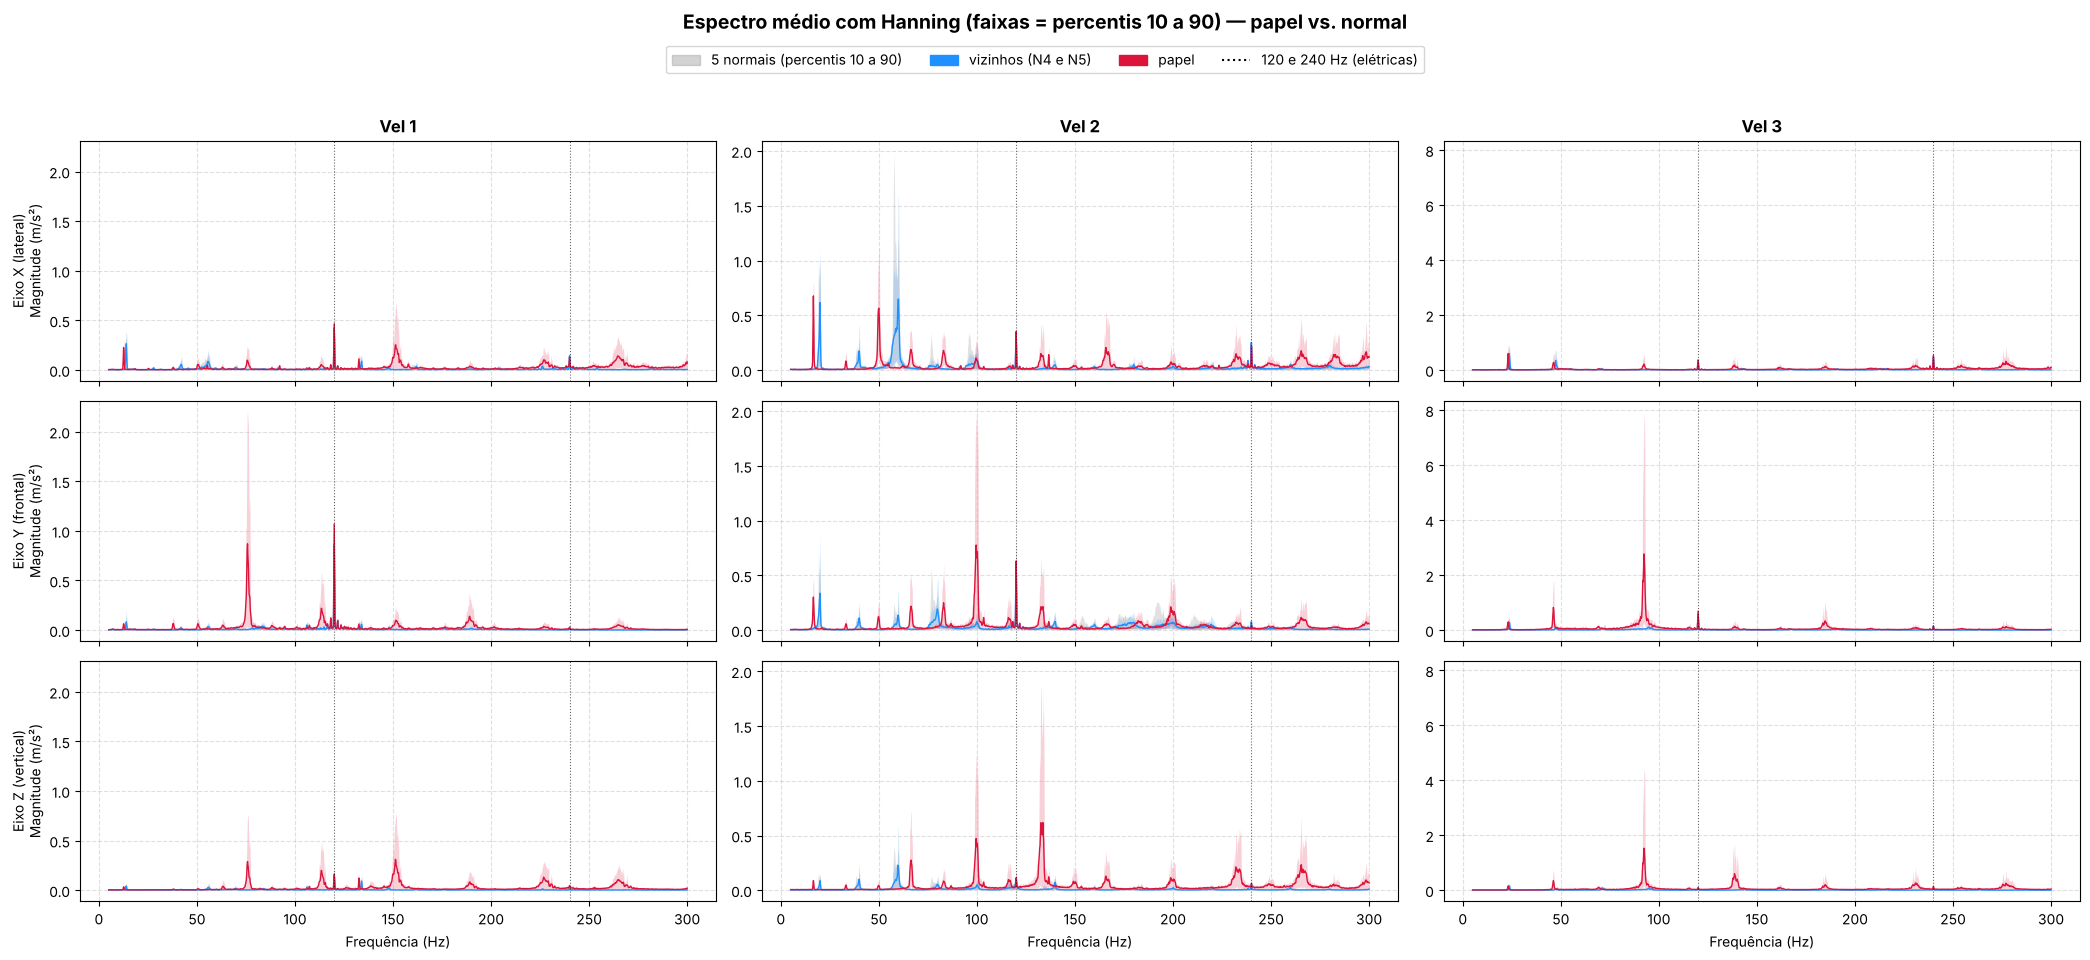

In [14]:
for condicao in condicoes_comparadas:
    plotar_espectros_comparados(features, frequencias, espectros_por_base, condicao, velocidades, vizinhos, BLOCOS_NORMAIS)

### O que encontramos no Passo 6

* **120 e 240 Hz:** aparecem com o mesmo tamanho no normal e nas quatro anomalias, como esperado de uma componente elétrica.
* **Calço:** o espectro fica **dentro da faixa cinza dos 5 normais** nas Vel 1 e 2, sem picos novos. Na **Vel 3**, o pico da rotação (1X, cerca de 23,6 Hz) fica mais alto nos eixos Y e Z (cerca de 0,68 e 0,59 m/s² no calço). O Passo 8 mostra que a amplitude de 1X no eixo Z é **3 vezes** a dos vizinhos.
* **Fitas:** o pente de harmônicas fica bem acima da faixa cinza nas Vel 2 e 3, e acima dela também em várias faixas na Vel 1 (Passo 7).
* **Papel:** linhas novas que **não existem** no normal: perto de 75 Hz (cerca de 0,88 m/s² no eixo Y), 115 e 152 Hz na Vel 1; perto de 100 Hz e 133 Hz na Vel 2; perto de 92 Hz (cerca de 2,8 m/s² no eixo Y) e 139 Hz na Vel 3.
* **Papel na Vel 2, um detalhe importante:** as harmônicas do papel aparecem **deslocadas para a esquerda** (1X perto de 17 Hz e 3X perto de 50 Hz, contra cerca de 20 e 59 Hz nos vizinhos). É o ventilador mais lento (Passo 8.1). Por isso as faixas de 35 a 65 Hz aparecem como "menores" no Passo 7: não é a vibração que diminuiu, é a harmônica que mudou de faixa.

## Passo 7 — Mapa por faixa de 10 Hz: onde o espectro muda

**O que buscamos:** resumir o Passo 6 num mapa: **em quais frequências, em quais eixos e em quanto** a anomalia muda a vibração em relação aos **vizinhos**.

1. Cada faixa de 10 Hz e eixo é uma das 90 features de FFT.
2. Calculamos a **mediana** das janelas da anomalia e a dos vizinhos, e dividimos uma pela outra: **quantas vezes a anomalia vibra mais ou menos** que os vizinhos.
3. A faixa só ganha cor quando **passa no critério dos vizinhos** (a anomalia fica do mesmo lado dos dois vizinhos, com separação de pelo menos `LIMIAR_VIZINHOS` contra cada um, e mais do que os vizinhos diferem entre si). Senão, fica **cinza**.

| Cor | Significado |
| --- | --- |
| **Vermelho** | A anomalia vibra **mais** que os vizinhos nessa faixa (quanto mais escuro, mais vezes) |
| **Azul** | A anomalia vibra **menos** que os vizinhos |
| **Cinza** | A diferença não é consistente, ou é do tamanho da diferença entre os próprios vizinhos |

Este critério é mais exigente que o do Notebook 02 anterior: lá bastava a separação contra o normal passar de 0,5; aqui a anomalia precisa se destacar **dos dois** normais vizinhos.

In [15]:
def calcular_mapa_por_faixa(features, condicao, velocidade, vizinhos, blocos_normais):
    """Mapas (eixo x faixa): log10 da razão anomalia/vizinhos (NaN = não passa no critério dos vizinhos)."""
    valores = []
    anomalia = selecionar_janelas(features, [condicao], velocidade)
    referencia = selecionar_janelas(features, vizinhos[condicao], velocidade)
    for eixo in EIXOS:
        colunas = colunas_fft_do_eixo(eixo)
        razao = np.log10((anomalia[colunas].median().to_numpy() + EPS) / (referencia[colunas].median().to_numpy() + EPS))
        passa = comparar_com_os_normais(features, condicao, velocidade, colunas, vizinhos, blocos_normais)["passa_vizinhos"].to_numpy()
        valores.append(np.where(passa, razao, np.nan))
    return np.array(valores)


def plotar_mapa_simples(features, condicao, velocidades, vizinhos, blocos_normais):
    """Um mapa por velocidade: quantas vezes a anomalia é maior (vermelho) ou menor (azul) que os vizinhos; cinza = não passa."""
    mapas = {v: calcular_mapa_por_faixa(features, condicao, v, vizinhos, blocos_normais) for v in velocidades}
    todos = np.concatenate([m.ravel() for m in mapas.values()])
    limite = max(np.log10(2), np.nanpercentile(np.abs(todos), 98)) if np.isfinite(todos).any() else np.log10(2)
    extensao = [FAIXA_FFT_HZ[0], FAIXA_FFT_HZ[1], len(EIXOS) - 0.5, -0.5]
    cmap = plt.get_cmap("RdBu_r").copy()
    cmap.set_bad("lightgrey")
    fig, axs = plt.subplots(1, len(velocidades), figsize=(7 * len(velocidades), 3.2), sharex=True, squeeze=False)
    for ax, velocidade in zip(axs[0], velocidades):
        imagem = ax.imshow(np.ma.masked_invalid(mapas[velocidade]), cmap=cmap, vmin=-limite, vmax=limite,
                           aspect="auto", extent=extensao, interpolation="nearest")
        n_cor = int(np.isfinite(mapas[velocidade]).sum())
        ax.set_title(f"Vel {velocidade}  ({n_cor} de {mapas[velocidade].size} faixas passam)", fontsize=12, fontweight="bold")
        ax.set_xlabel("Frequência (Hz)")
        ax.set_yticks(range(len(EIXOS)))
        ax.set_yticklabels([f"Eixo {e.upper()}" for e in EIXOS])
        ax.grid(False)
    vezes = [v for v in (0.1, 0.2, 0.5, 1, 2, 5, 10, 20, 50, 100) if abs(np.log10(v)) <= limite]
    barra = fig.colorbar(imagem, ax=axs[0, :], shrink=0.9, label="anomalia comparada com os vizinhos")
    barra.set_ticks(np.log10(vezes))
    barra.set_ticklabels([f"{v:g}× maior" if v > 1 else ("igual" if v == 1 else f"{1/v:g}× menor") for v in vezes])
    fig.suptitle(f"{condicao} vs. vizinhos ({' e '.join(vizinhos[condicao])}): quantas vezes a vibração mudou "
                 f"em cada faixa de {LARGURA_FAIXA_HZ} Hz", fontsize=13, fontweight="bold", y=1.12)
    fig.text(0.42, -0.12, "Cinza = a faixa não passa no critério dos vizinhos (não dá para afirmar que mudou)",
             ha="center", fontsize=10, color="dimgray")
    plt.show()

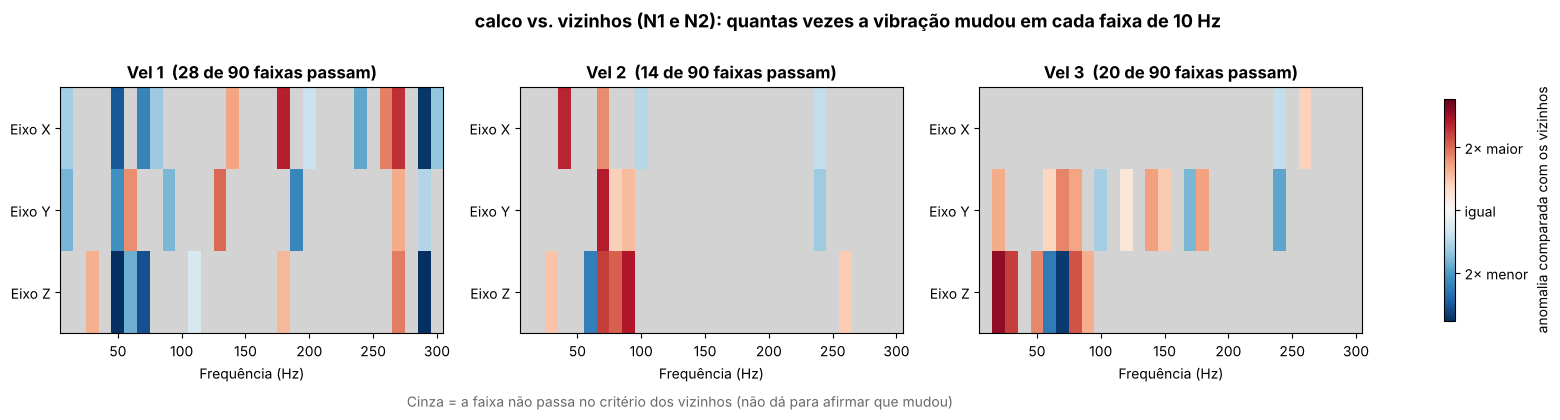

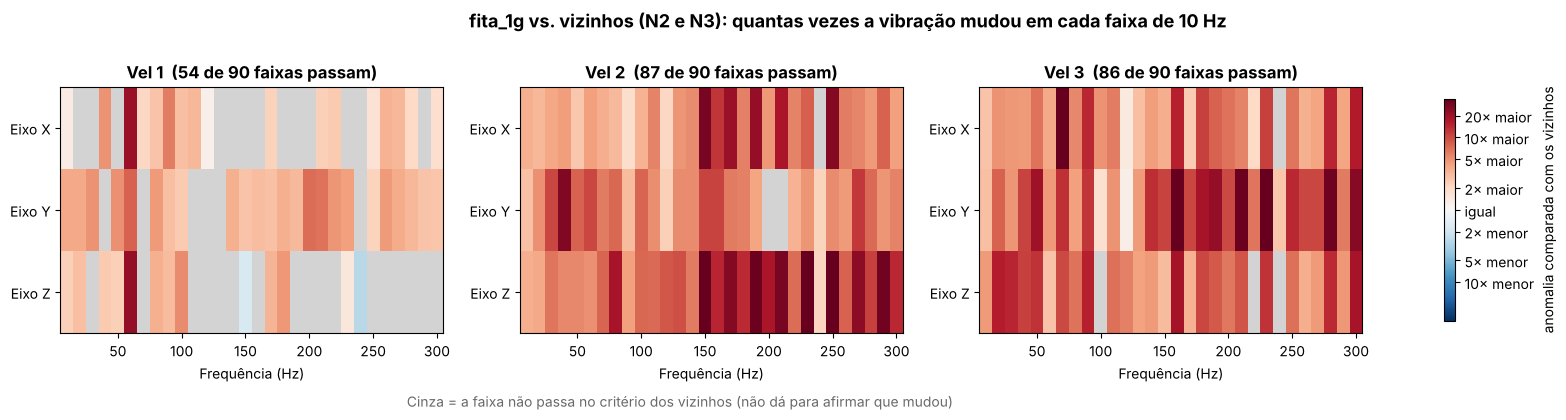

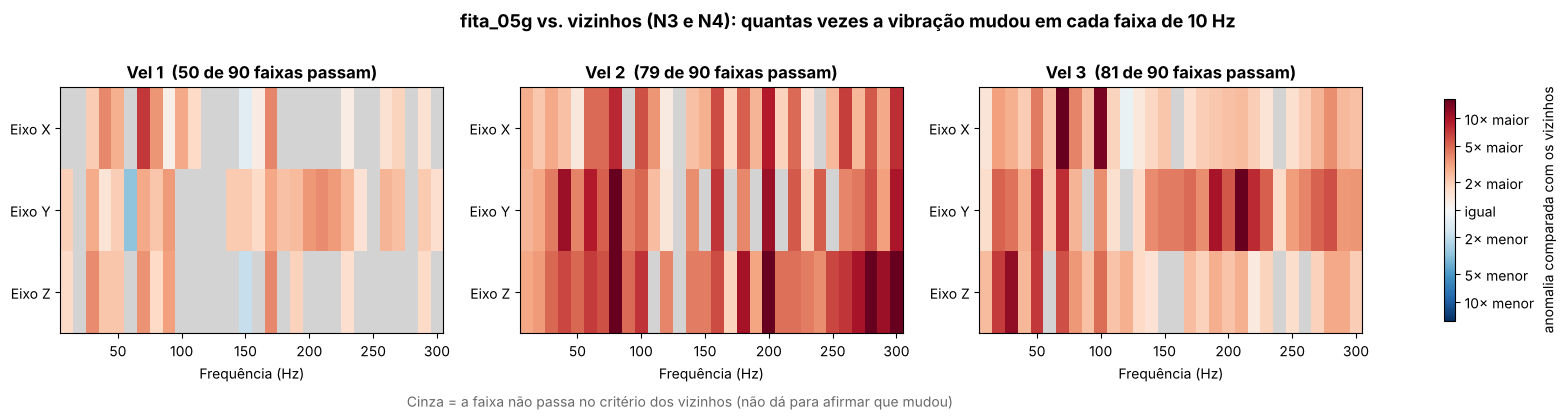

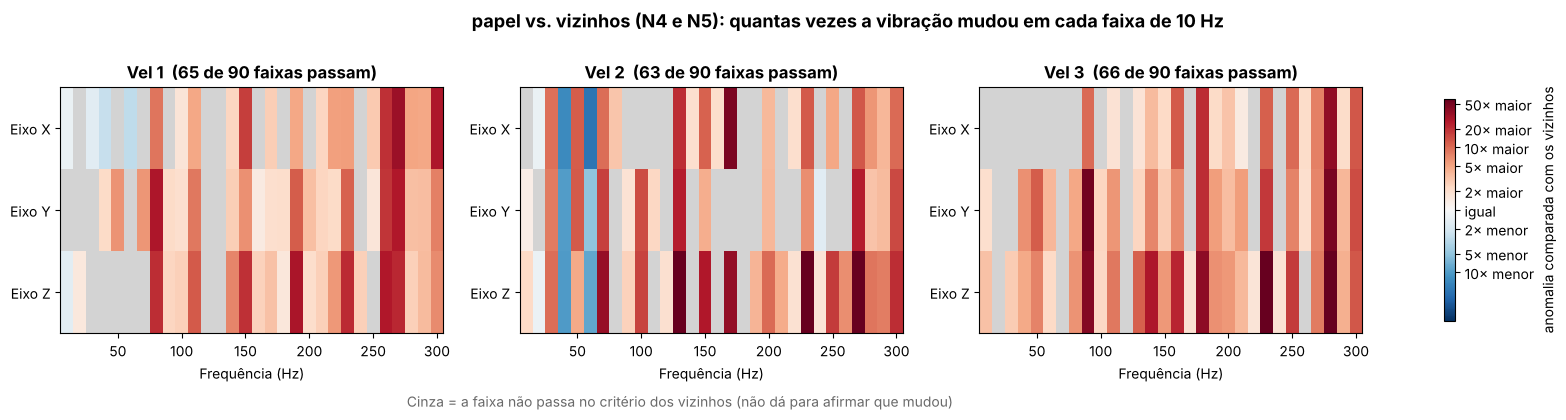

In [16]:
for condicao in condicoes_comparadas:
    plotar_mapa_simples(features, condicao, velocidades, vizinhos, BLOCOS_NORMAIS)

### O que encontramos no Passo 7

**Faixas que passam no critério dos vizinhos (de 90):**

| Anomalia | Vel 1 | Vel 2 | Vel 3 |
| --- | --- | --- | --- |
| Calço | 28 | 14 | 20 |
| Fita 1 g | 54 | 87 | 86 |
| Fita 0,5 g | 50 | 79 | 81 |
| Papel | 65 | 63 | 66 |

* **Fitas:** quase todas as faixas ficam vermelhas nas Vel 2 e 3, muitas mais de 5 a 10 vezes acima dos vizinhos. Na Vel 1 restam cerca de 50 faixas, com destaque para 55–65 Hz nos eixos X e Z na fita 1 g e 65–75 Hz no eixo X na fita 0,5 g.
* **Papel:** vermelho forte nas faixas altas (acima de cerca de 130 Hz) nas três velocidades, com várias faixas mais de 10 vezes acima. Na Vel 2, as faixas de 35 a 65 Hz ficam azuis pelo deslocamento das harmônicas (Passo 6).
* **Calço:** o mapa é **misturado**, com faixas maiores **e** menores que os vizinhos, quase sempre perto de "2 vezes". Na Vel 1 há faixas menores em 45–75 Hz (X e Z) e perto de 290 Hz. Na Vel 3, o eixo Z sobe em 15–35 Hz (rotação) e desce em 55–75 Hz. **Não há um padrão claro de "mais vibração"**, ao contrário das outras três anomalias.

## Passo 8 — Rotação 1X e harmônicas

**O que buscamos:** responder duas perguntas que o ventilador sem tacômetro nos obriga a medir pelo próprio sinal:

1. **A rotação é a mesma no normal e na anomalia?** O Notebook 01 mostrou que a rotação do normal **sobe ao longo da sessão** (aquecimento) e que as anomalias da Vel 1 giram **mais devagar** que os vizinhos. Aqui medimos isso janela por janela.
2. **1X, 2X e 3X cresceram?** O pico em 1X e nas harmônicas é a assinatura clássica de desbalanceamento.

Em cada janela, o **1X** é o pico mais alto da soma dos três eixos dentro de `FAIXA_BUSCA_1X_HZ`, em duas passadas (a primeira acha a rotação típica da base e a segunda procura só a até `DESVIO_MAX_1X_HZ` dela). A amplitude de **kX** é o maior pico a até `TOLERANCIA_HARMONICA_HZ` de k vezes o 1X.

* **8.1 — Rotação por gravação**, na ordem da sessão, e a diferença de cada anomalia para os seus vizinhos.
* **8.2 — Rotação ao longo da sessão:** todas as janelas de todas as gravações, numa figura só.
* **8.3 e 8.4 — Amplitude em 1X, 2X e 3X:** boxplots e mapa de separação, como no Passo 5 (com a rotação `f1x_hz` incluída no mapa).

In [17]:
def estimar_f1x(frequencias, espectros):
    """Rotação 1X de cada janela, em duas passadas (ver o texto acima)."""
    soma_dos_eixos = espectros.sum(axis=2)                                         # (janela, frequência)
    na_faixa = (frequencias >= FAIXA_BUSCA_1X_HZ[0]) & (frequencias <= FAIXA_BUSCA_1X_HZ[1])
    tipica = np.median(frequencias[na_faixa][soma_dos_eixos[:, na_faixa].argmax(axis=1)])
    perto = na_faixa & (np.abs(frequencias - tipica) <= DESVIO_MAX_1X_HZ)
    return frequencias[perto][soma_dos_eixos[:, perto].argmax(axis=1)]


def medir_amplitudes_harmonicas(frequencias, espectros, f1x, n_harmonicas, tolerancia_hz):
    """Amplitude de 1X, 2X, ... em cada janela e eixo: o maior pico a até tolerancia_hz de k vezes o 1X."""
    colunas = {}
    for k in range(1, n_harmonicas + 1):
        perto = np.abs(frequencias[None, :] - (k * f1x)[:, None]) <= tolerancia_hz     # (janela, frequência)
        for j, eixo in enumerate(EIXOS):
            colunas[f"amp_{k}x_{eixo}"] = np.where(perto, espectros[:, :, j], 0.0).max(axis=1)
    return pd.DataFrame(colunas)


def adicionar_colunas_de_rotacao(features, frequencias, espectros_por_base):
    """Acrescenta à tabela a rotação (f1x_hz) e as amplitudes amp_1x_x, amp_2x_x, ... de cada janela."""
    features = features.drop(columns=[c for c in features.columns if c.startswith("amp_") or c == "f1x_hz"])
    partes = []
    for nome, grupo in features.groupby("base", sort=False):
        f1x = estimar_f1x(frequencias, espectros_por_base[nome])
        amplitudes = medir_amplitudes_harmonicas(frequencias, espectros_por_base[nome], f1x, N_HARMONICAS, TOLERANCIA_HARMONICA_HZ)
        amplitudes.insert(0, "f1x_hz", f1x)
        amplitudes.index = grupo.index
        partes.append(amplitudes)
    return features.join(pd.concat(partes))


def resumir_rotacao_na_sessao(features, catalogo):
    """Tabela (grupo da sessão x velocidade) com a rotação mediana de cada gravação, em Hz."""
    mediana = features.groupby(["bloco", "velocidade"])["f1x_hz"].median().unstack()
    ordem = catalogo.drop_duplicates("bloco")
    mediana.index = ordem.set_index("bloco").loc[mediana.index, "grupo"]
    return mediana.loc[ordem["grupo"]].rename_axis(index="bloco da sessão", columns="Vel")


def rotacao_contra_vizinhos(features, condicoes, velocidades, vizinhos):
    """Rotação mediana de cada anomalia menos a de cada vizinho (Hz). Negativo = a anomalia gira mais devagar."""
    linhas = []
    for condicao in condicoes:
        for velocidade in velocidades:
            f_anom = selecionar_janelas(features, [condicao], velocidade)["f1x_hz"].median()
            linha = {"condicao": condicao, "velocidade": velocidade, "anomalia_hz": f_anom}
            for nome, bloco in zip(("antes", "depois"), (vizinhos[condicao][0], vizinhos[condicao][-1])):
                f_viz = selecionar_janelas(features, [bloco], velocidade)["f1x_hz"].median()
                linha[f"vizinho_{nome}"] = bloco
                linha[f"dif_{nome}_hz"] = f_anom - f_viz
            linhas.append(linha)
    return pd.DataFrame(linhas).set_index(["condicao", "velocidade"])


def plotar_rotacao_na_sessao(features, catalogo, velocidades, condicao_normal=CONDICAO_NORMAL):
    """Um painel por velocidade: a rotação de cada janela, gravação por gravação, na ordem da sessão."""
    blocos = catalogo.drop_duplicates("bloco").sort_values("posicao_sessao")
    fig, axs = plt.subplots(1, len(velocidades), figsize=(6.2 * len(velocidades), 4.4), squeeze=False)
    for ax, velocidade in zip(axs[0], velocidades):
        medianas_normais = []
        for _, b in blocos.iterrows():
            janelas = selecionar_janelas(features, [b["bloco"]], velocidade)
            if len(janelas) == 0:
                continue
            x = b["posicao_sessao"] + (janelas["janela"] / max(janelas["janela"].max(), 1) - 0.5) * 0.6
            normal = b["condicao"] == condicao_normal
            ax.scatter(x, janelas["f1x_hz"], s=9, alpha=0.6, color=COR_VIZINHOS if normal else COR_COMPARADA)
            if normal:
                medianas_normais.append((b["posicao_sessao"], janelas["f1x_hz"].median()))
        ax.plot(*zip(*medianas_normais), color=COR_VIZINHOS, linewidth=1.2, marker="o", markersize=4)
        ax.set_xticks(blocos["posicao_sessao"])
        ax.set_xticklabels(blocos["bloco"], rotation=45, ha="right")
        ax.set_title(f"Vel {velocidade}", fontsize=12, fontweight="bold")
        ax.set_xlabel("Bloco da sessão (na ordem de gravação)")
    axs[0, 0].set_ylabel("Rotação 1X estimada (Hz)")
    fig.legend(handles=[Patch(color=COR_VIZINHOS, label="normal (linha = mediana de cada lote)"),
                        Patch(color=COR_COMPARADA, label="anomalia")],
               loc="upper center", ncol=2, fontsize=10, bbox_to_anchor=(0.5, 0.94))
    fig.suptitle("Rotação 1X de cada janela ao longo da sessão", fontsize=14, fontweight="bold", y=0.995)
    plt.tight_layout(rect=[0, 0, 1, 0.88])
    plt.show()

### 8.1 — Rotação por gravação e contra os vizinhos

In [18]:
features = adicionar_colunas_de_rotacao(features, frequencias, espectros_por_base)
COLUNAS_ROTACAO = [f"amp_{k}x_{eixo}" for k in range(1, N_HARMONICAS + 1) for eixo in EIXOS]

print("Rotação 1X mediana de cada gravação (Hz):")
display(resumir_rotacao_na_sessao(features, catalogo).round(2))
print("Rotação da anomalia menos a de cada vizinho (Hz; negativo = a anomalia gira mais devagar):")
display(rotacao_contra_vizinhos(features, condicoes_comparadas, velocidades, vizinhos).round(2))

Rotação 1X mediana de cada gravação (Hz):


Vel,1,2,3
bloco da sessão,,,
1. N1,13.2,19.2,23.8
2. calco,12.6,19.2,23.6
3. N2,13.4,19.5,23.6
4. fita_1g,12.6,19.4,23.4
5. N3,13.8,19.4,23.8
6. fita_05g,13.4,20.2,23.8
7. N4,13.8,19.6,23.8
8. papel,12.6,16.6,23.2
9. N5,14.0,20.0,23.6


Rotação da anomalia menos a de cada vizinho (Hz; negativo = a anomalia gira mais devagar):


anomalia_hz vizinho_antes  dif_antes_hz vizinho_depois  dif_depois_hz
condicao velocidade                                                                       
calco    1                  12.6            N1          -0.6             N2           -0.8
         2                  19.2            N1           0.0             N2           -0.3
         3                  23.6            N1          -0.2             N2            0.0
fita_1g  1                  12.6            N2          -0.8             N3           -1.2
         2                  19.4            N2          -0.1             N3            0.0
         3                  23.4            N2          -0.2             N3           -0.4
fita_05g 1                  13.4            N3          -0.4             N4           -0.4
         2                  20.2            N3           0.8             N4            0.6
         3                  23.8            N3           0.0             N4            0.0
papel    1                  12.6            N4          -1.2             N5           -1.4
         2                  16.6            N4          -3.0             N5           -3.4
         3                  23.2            N4          -0.6             N5           -0.4

### O que encontramos no Passo 8.1

* **O normal acelera ao longo da sessão nas Vel 1 e 2:** Vel 1 de 13,2 Hz (N1) para 14,0 Hz (N5); Vel 2 de 19,2 para 20,0 Hz. **Na Vel 3 fica entre 23,6 e 23,8 Hz.**
* **Na Vel 1, as quatro anomalias giram mais devagar que os dois vizinhos:** calço −0,6 e −0,8 Hz; fita 1 g −0,8 e −1,2; fita 0,5 g −0,4 e −0,4; papel −1,2 e −1,4.
* **Na Vel 2**, o papel é muito mais lento (−3,0 e −3,4 Hz). A fita 0,5 g fica **mais rápida** que os dois vizinhos (+0,8 e +0,6 Hz); calço e fita 1 g ficam no nível dos vizinhos.
* **Na Vel 3** as diferenças são pequenas (até −0,6 Hz no papel).
* **Como entender:** pelo protocolo descrito pelo grupo, o ventilador ficava desligado antes de **todos** os blocos (normais e anomalias), então a diferença não parece vir do jeito de ligar. Uma carga a mais (massa da fita, atrito ou arrasto do papel, inclinação do calço) pode frear o motor fraco da Vel 1. Isso é uma hipótese: o notebook mostra que a rotação muda, não o porquê.

### 8.2 — Rotação ao longo da sessão

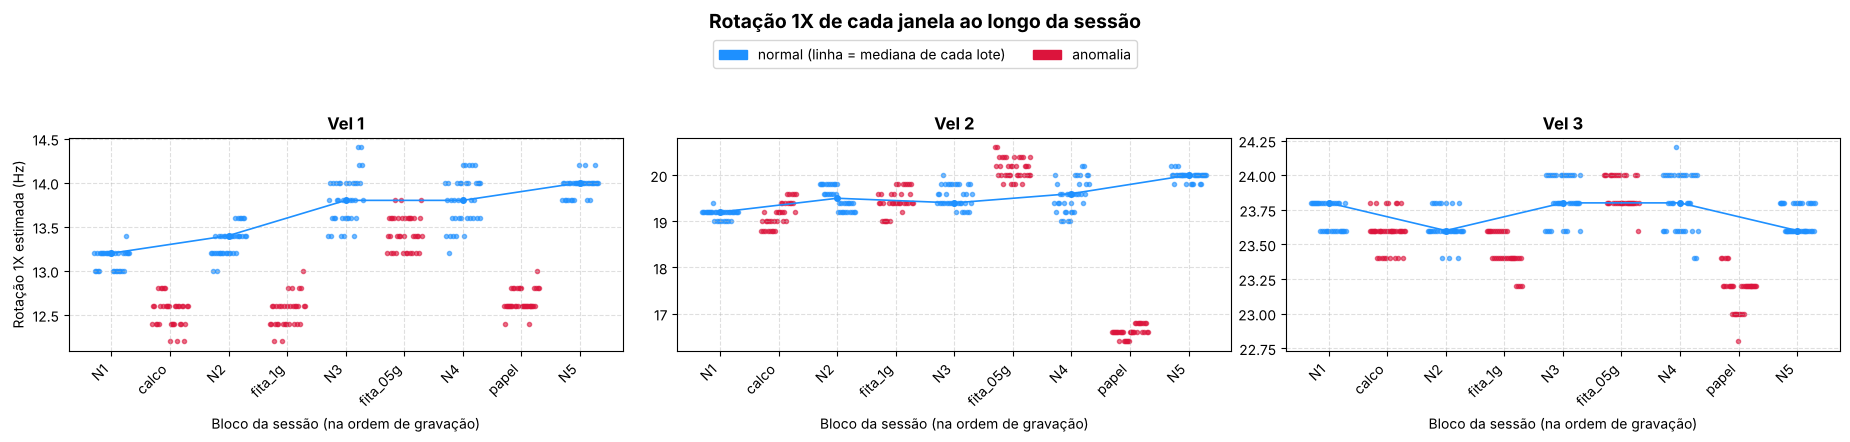

In [19]:
plotar_rotacao_na_sessao(features, catalogo, velocidades)

### O que encontramos no Passo 8.2

* A figura mostra os dois efeitos juntos: a **linha azul sobe** nas Vel 1 e 2 (aquecimento entre os lotes) e os **pontos vermelhos da Vel 1 ficam abaixo** dos dois lotes vizinhos, em todas as anomalias.
* **Dentro de cada gravação** a rotação quase não muda (cada nuvem fica em uma ou duas linhas horizontais, na resolução de 0,2 Hz da janela de 5 s).
* **Consequência para o modelo:** `f1x_hz` carrega **informação da falha** (freio na Vel 1 e no papel V2) e **informação do momento da sessão** (aquecimento). Na Vel 1, a rotação de todas as anomalias (12,6 a 13,4 Hz) fica **abaixo ou no limite** dos 5 normais (13,2 a 14,0 Hz). Um modelo pode aprender "rotação baixa = anomalia", o que funciona nesta sessão mas pode falhar com o motor frio de outra sessão, que também gira mais devagar (no NOVOS_DADOS, o normal da Vel 1 começava perto de 10,5–11 Hz).

### 8.3 e 8.4 — Harmônicas, para cada anomalia

==================== calco vs. normal (vizinhos: N1 e N2) ====================


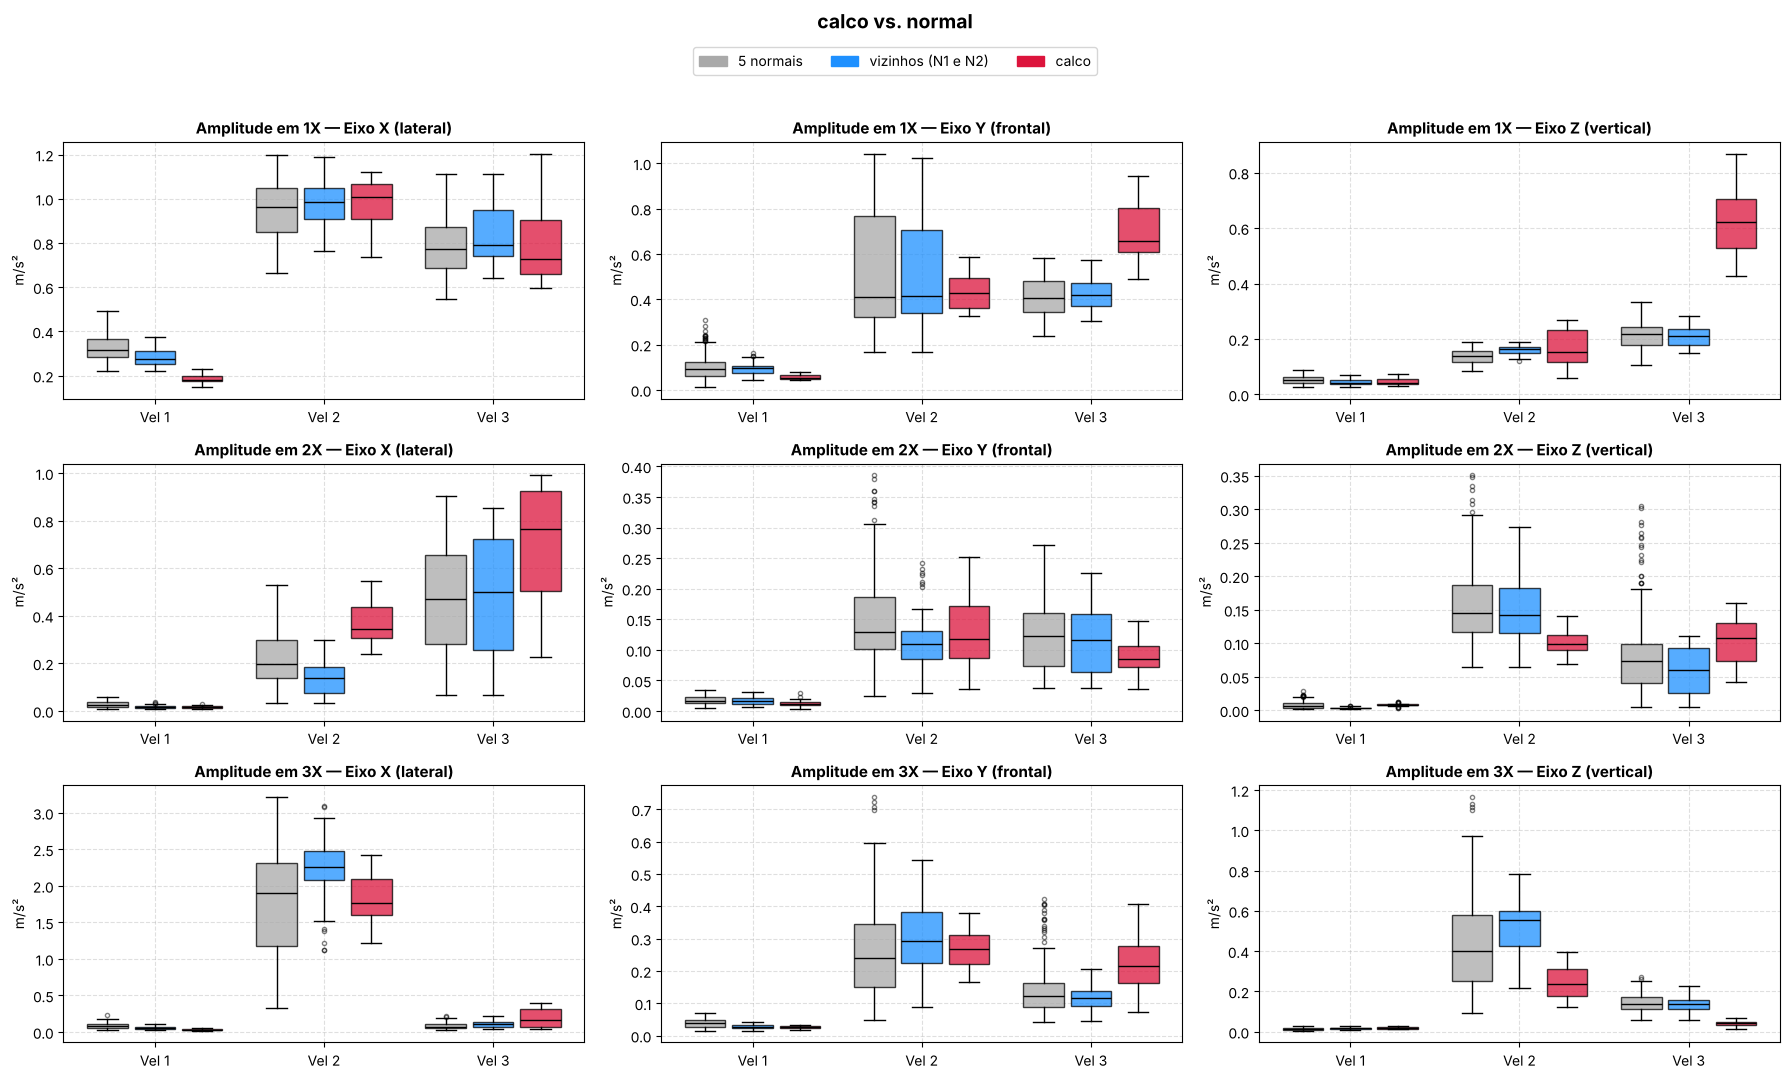

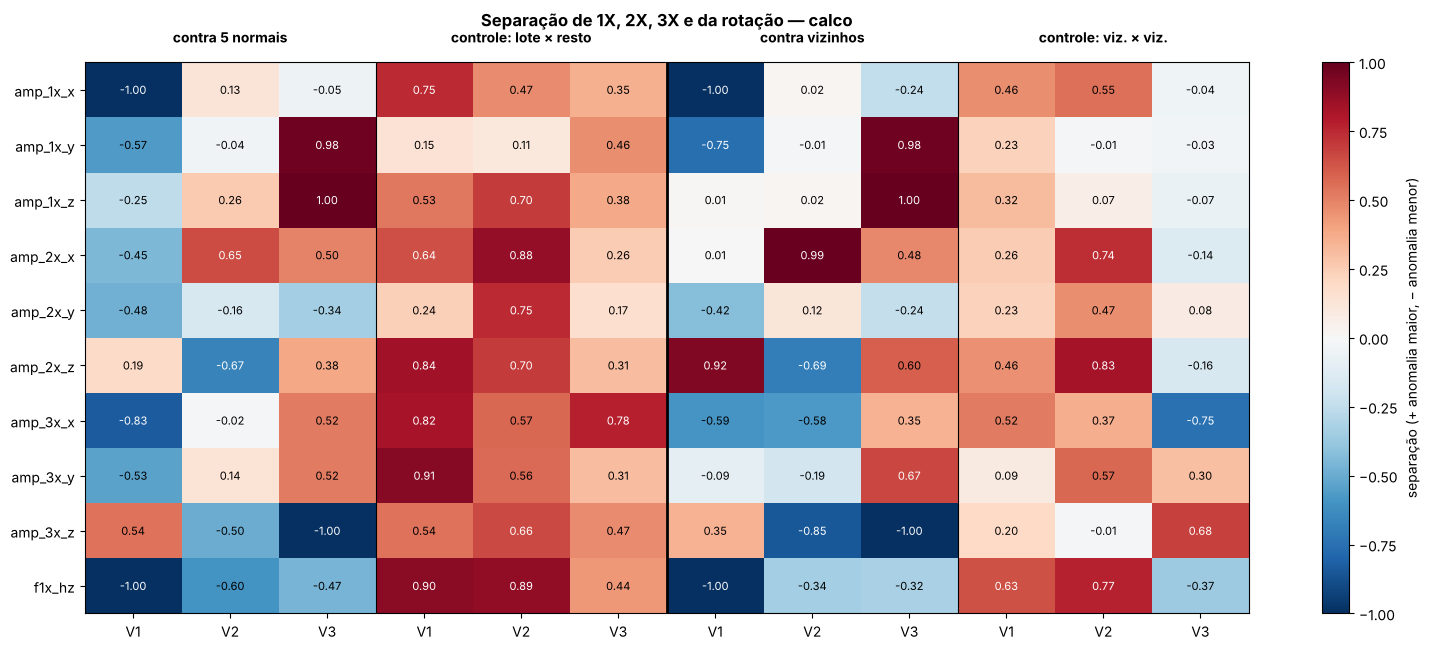

==================== fita_1g vs. normal (vizinhos: N2 e N3) ====================


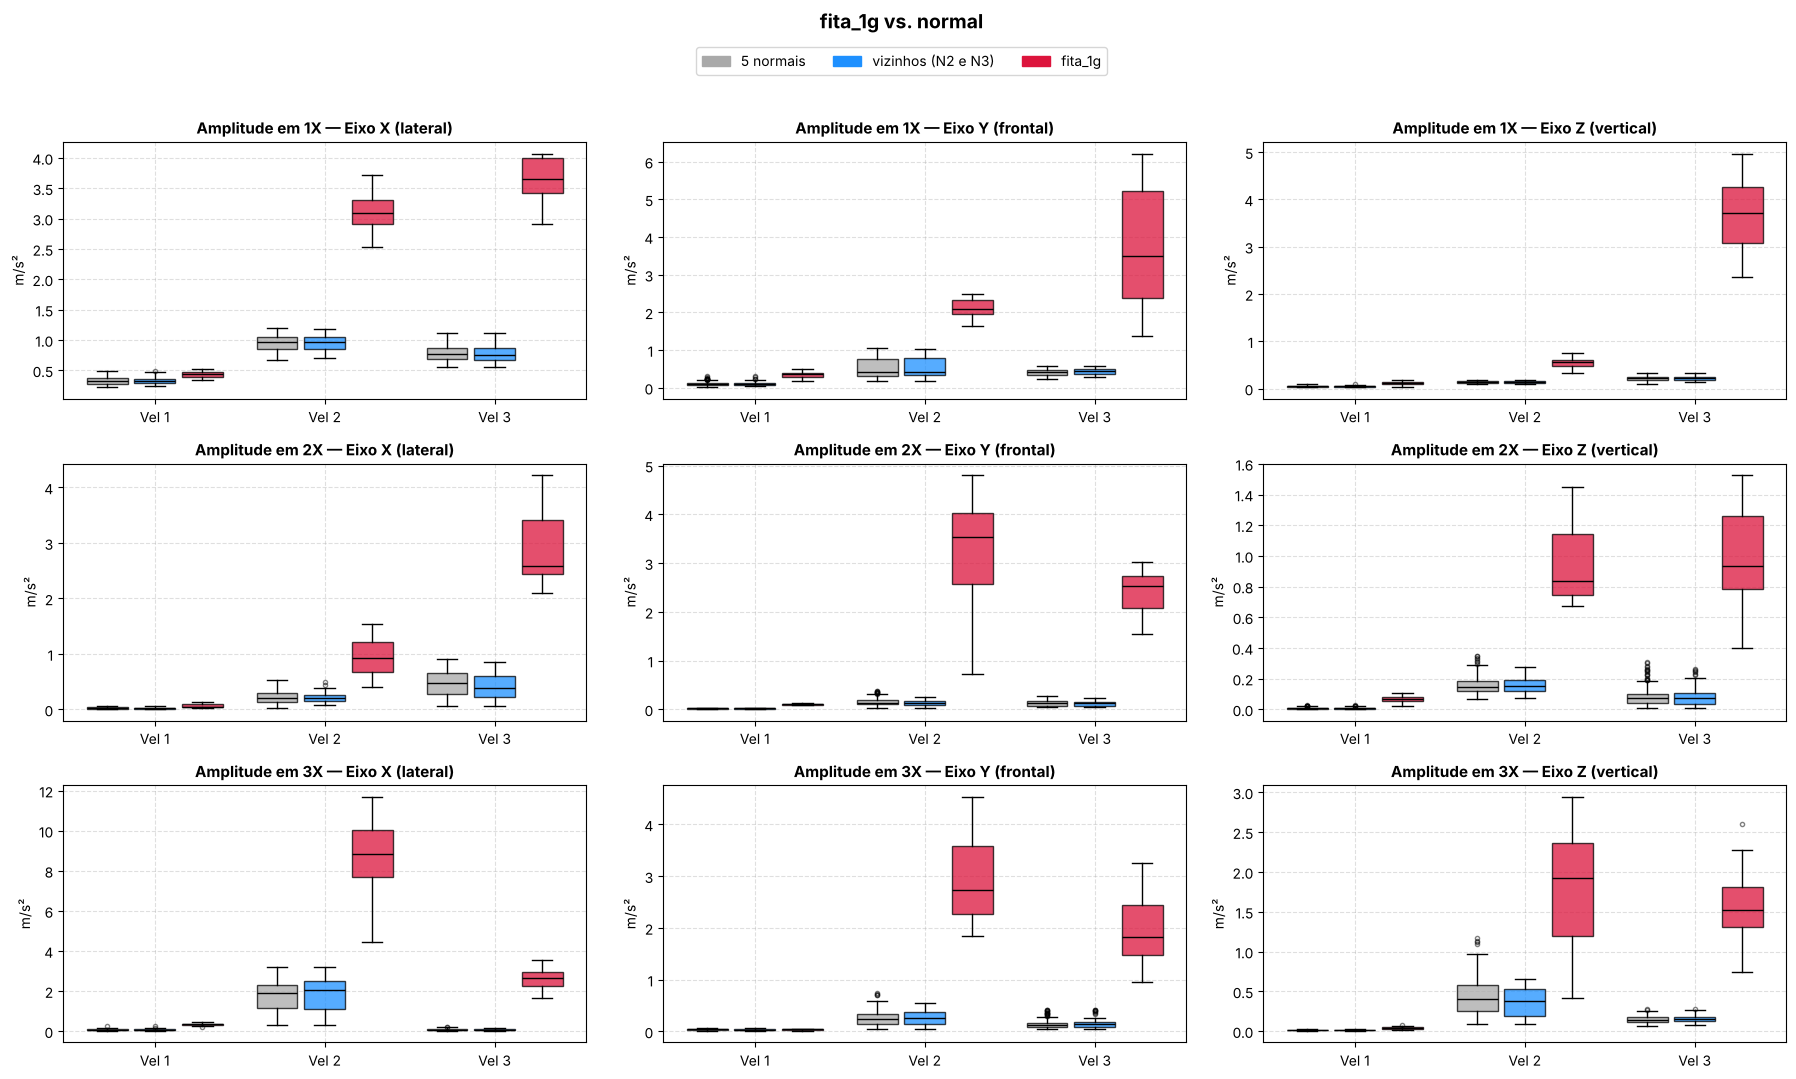

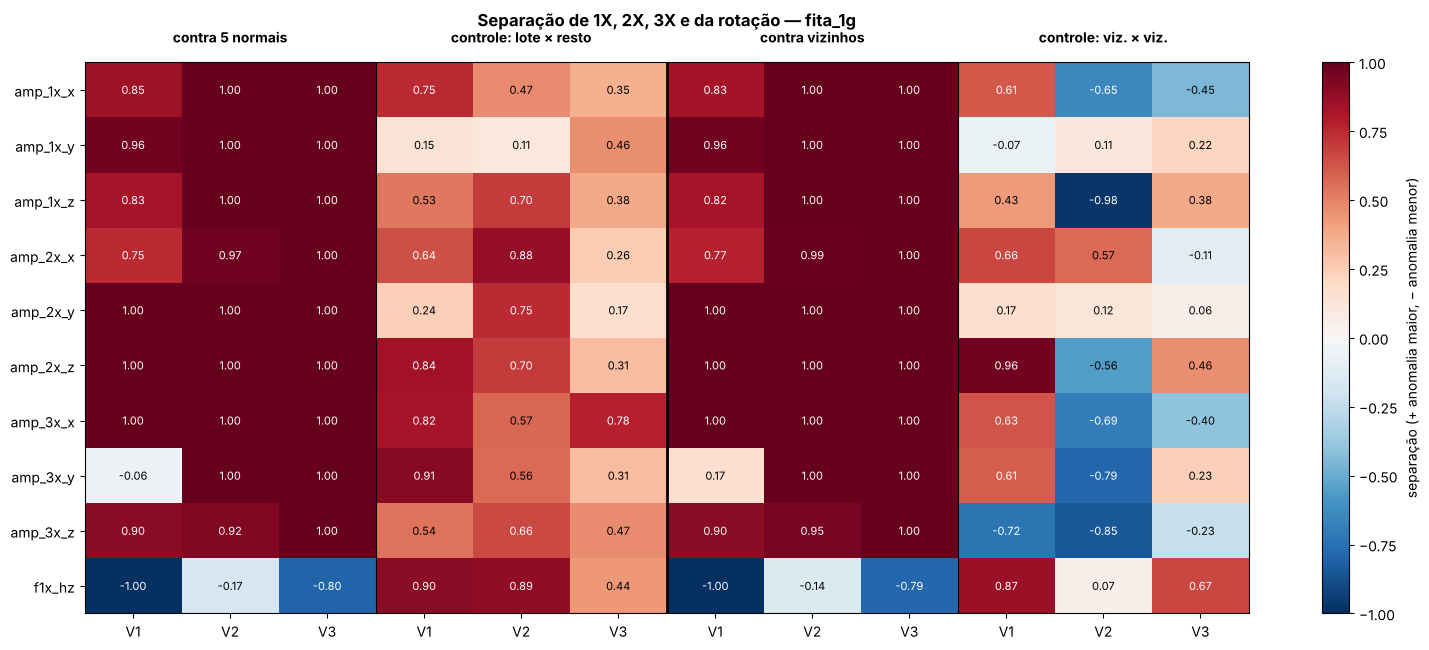

==================== fita_05g vs. normal (vizinhos: N3 e N4) ====================


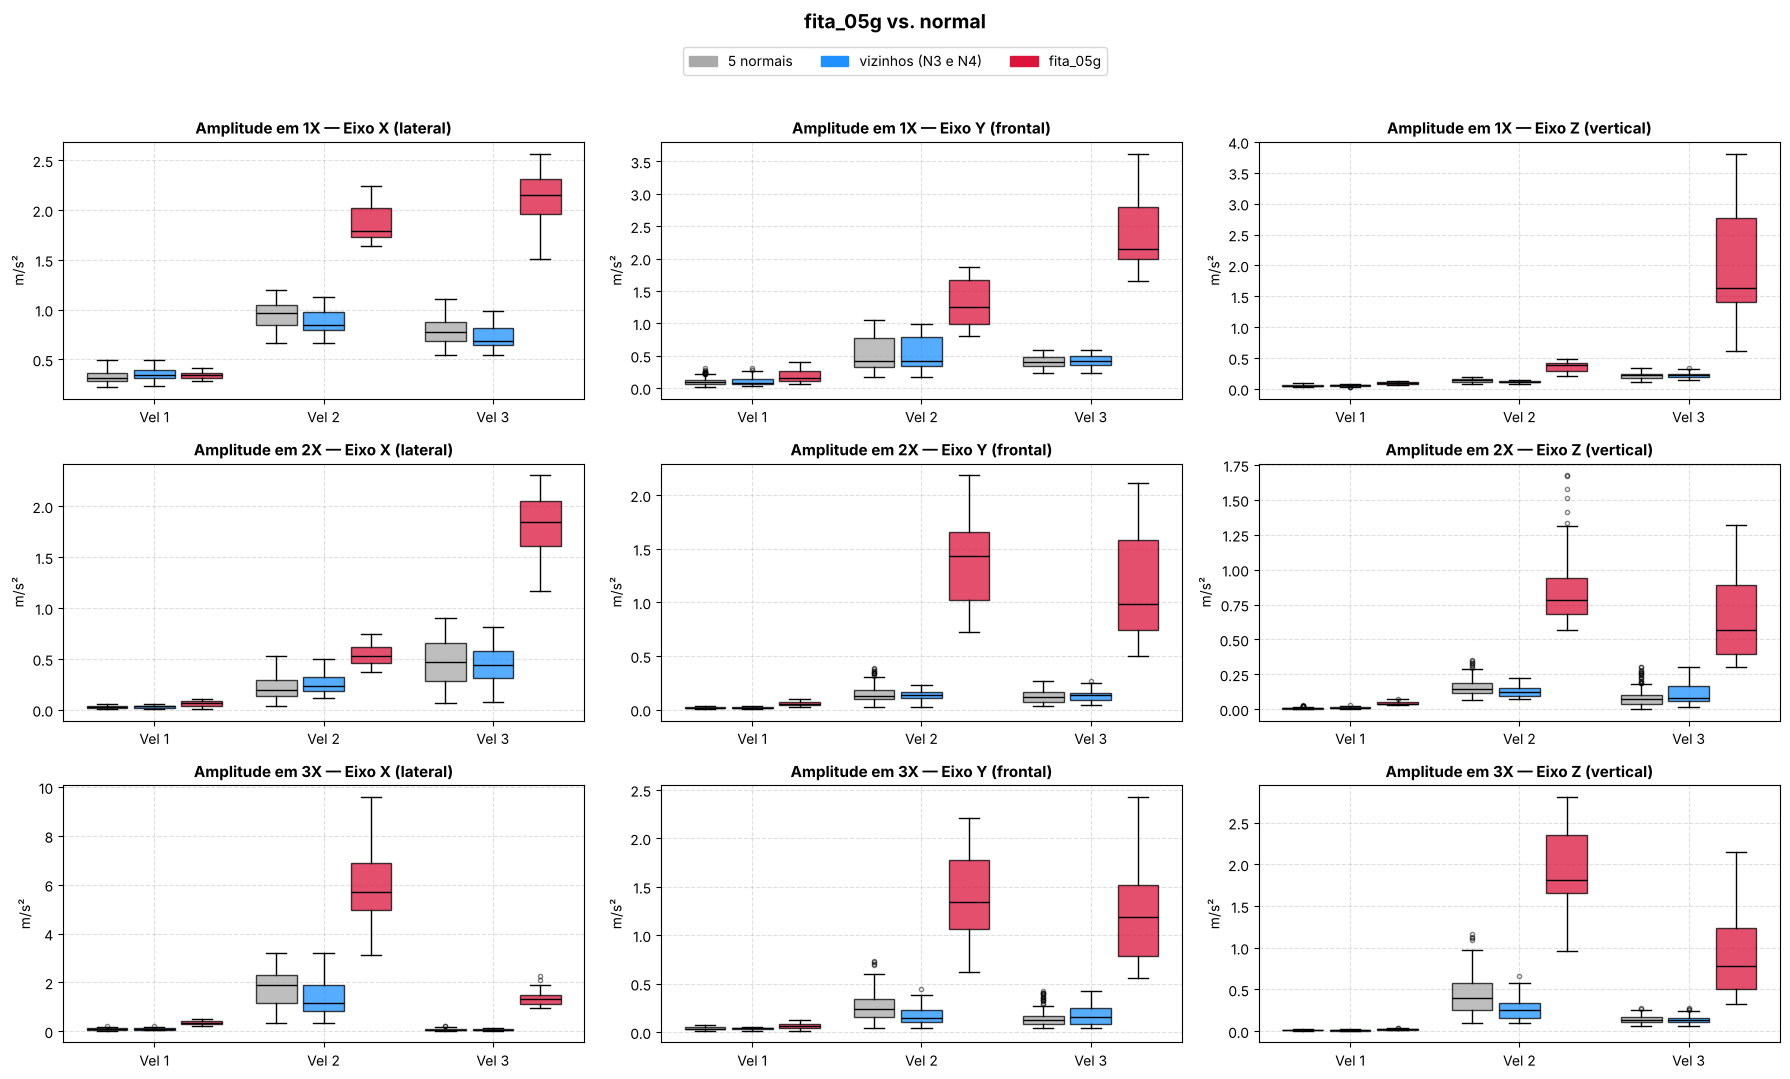

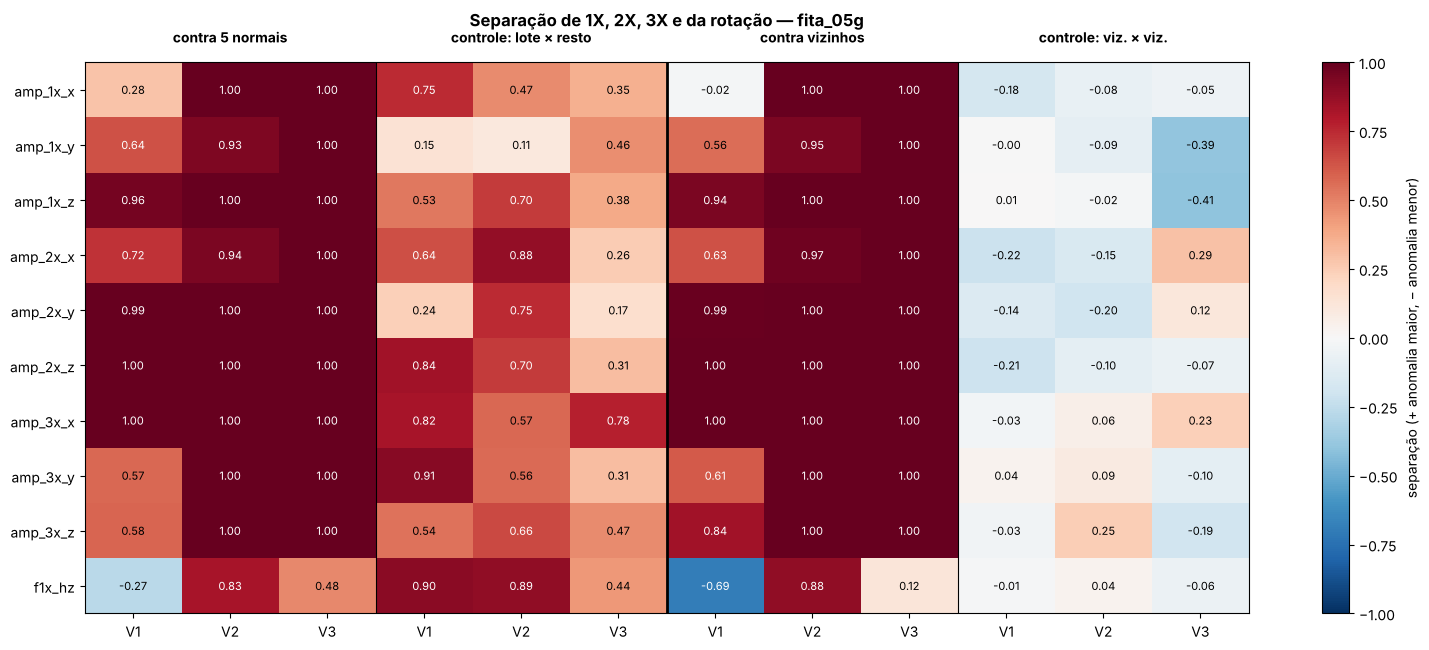

==================== papel vs. normal (vizinhos: N4 e N5) ====================


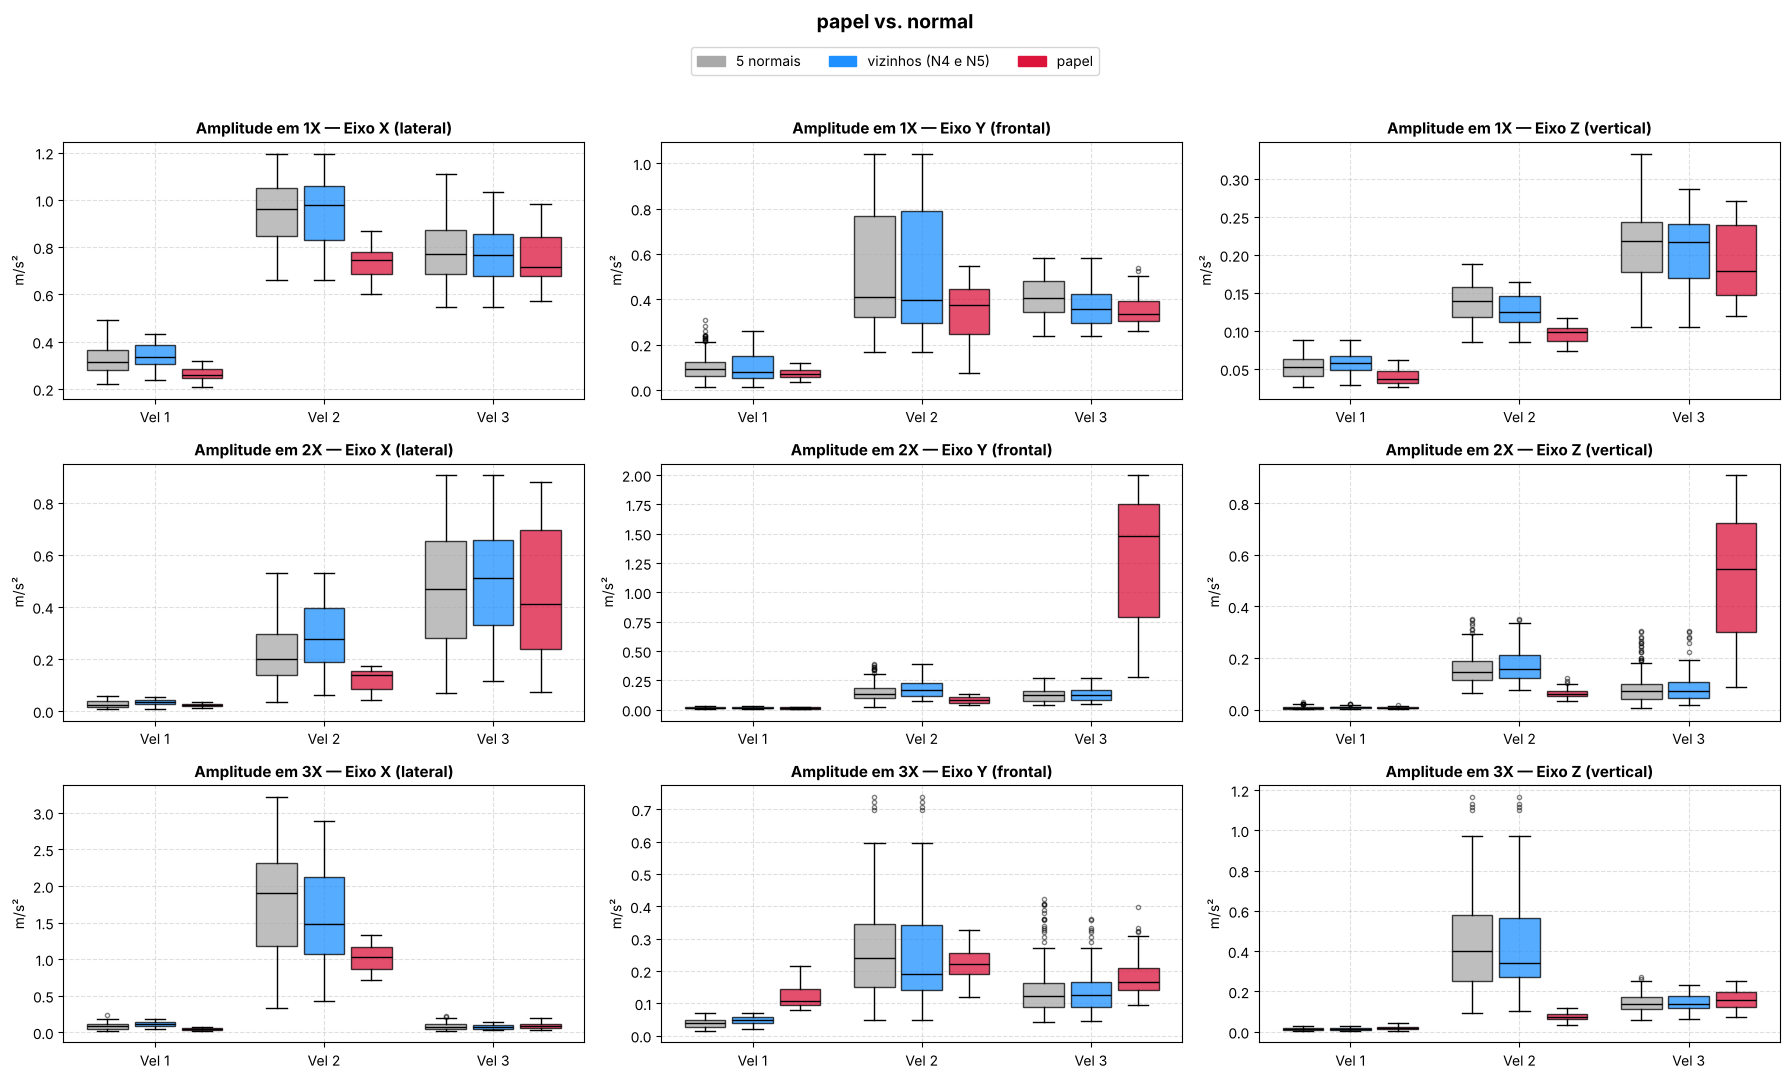

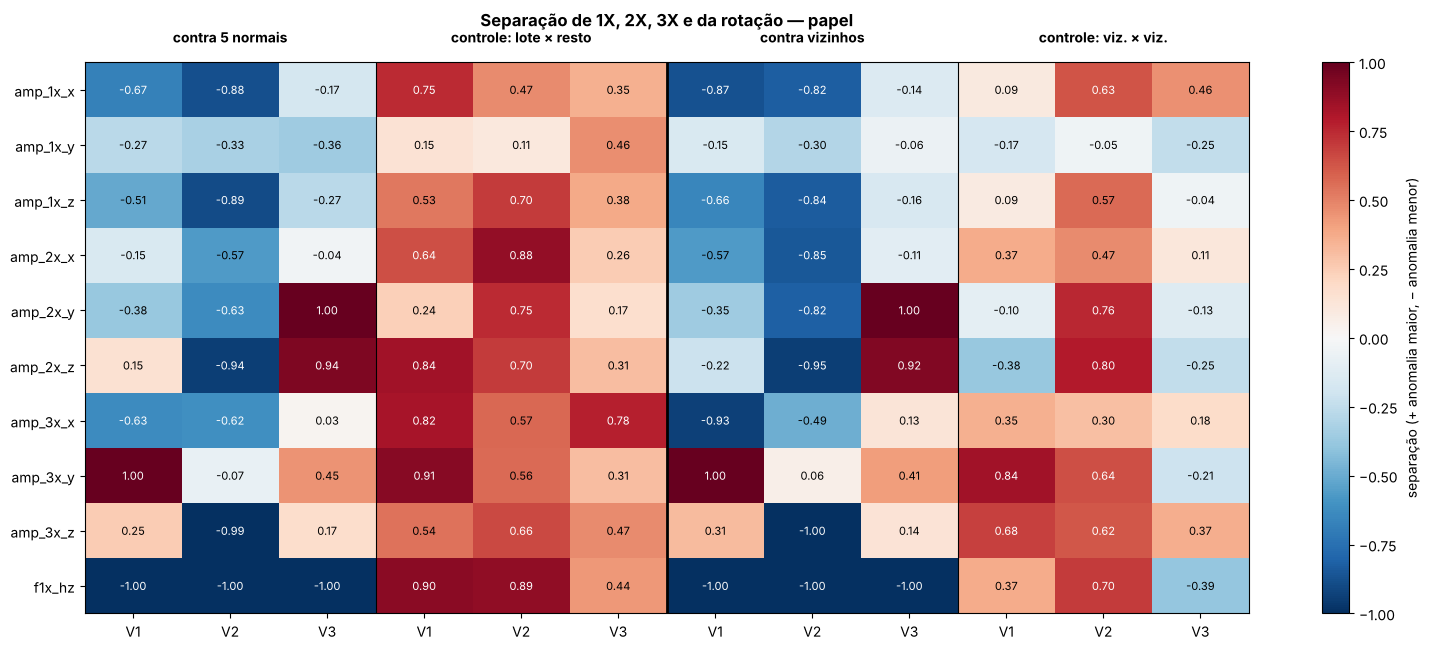

In [20]:
LINHAS_HARMONICAS = [(f"amp_{k}x", f"Amplitude em {k}X", UNIDADE) for k in range(1, N_HARMONICAS + 1)]

for condicao in condicoes_comparadas:
    print(f"==================== {condicao} vs. normal (vizinhos: {' e '.join(vizinhos[condicao])}) ====================")
    plotar_boxplots_comparativo(features, condicao, LINHAS_HARMONICAS, velocidades, vizinhos, BLOCOS_NORMAIS)
    matriz = montar_matriz_de_separacao(features, condicao, COLUNAS_ROTACAO + ["f1x_hz"], velocidades, vizinhos, BLOCOS_NORMAIS)
    plotar_mapa_de_separacao(matriz, f"Separação de 1X, 2X, 3X e da rotação — {condicao}")

### O que encontramos nos Passos 8.3 e 8.4

**Amplitude da harmônica na anomalia dividida pela dos vizinhos (medianas); entre parênteses, quantas das 9 amplitudes passam no critério dos vizinhos:**

| Anomalia | Vel 1 | Vel 2 | Vel 3 |
| --- | --- | --- | --- |
| Fita 1 g | 1,2 a 11,5 vezes (7) | 3,2 a 25,9 vezes (9) | 4,9 a 47,4 vezes (9) |
| Fita 0,5 g | 1,0 a 3,8 vezes (8) | 2,1 a 10,8 vezes (9) | 3,1 a 25,2 vezes (9) |
| Papel | 0,4 a 2,2 vezes (4) | 0,2 a 1,2 vezes (5) | 0,8 a 12,0 vezes (2) |
| Calço | 0,6 a 2,4 vezes (3) | 0,4 a 2,5 vezes (2) | 0,3 a 3,0 vezes (5) |

* **Fitas:** 1X, 2X e 3X crescem em todos os eixos nas Vel 2 e 3 e na maioria na Vel 1. É o **desbalanceamento**, e a fita 0,5 g fica abaixo da de 1 g em todas as velocidades.
* **Papel:** as harmônicas ficam **iguais ou menores** que nos vizinhos nas Vel 1 e 2 (parte disso é a harmônica mudando de faixa com a rotação mais lenta). A exceção é a 2X da Vel 3 (12 vezes no eixo Y e 7,5 no Z). O papel aparece **fora** das harmônicas (Passos 6 e 7).
* **Calço:** muda as harmônicas **para os dois lados**. Na Vel 3, a 1X do eixo Z fica 3 vezes maior e a 3X do eixo Z cai para 0,3 vez. Na Vel 1, a 1X dos eixos X e Y fica menor (0,7 e 0,6 vez).
* **A rotação no mapa:** `f1x_hz` passa no critério dos vizinhos nas quatro anomalias na Vel 1 (no calço, com separação de −1,00), mas o controle "lote × resto" dela também é alto na Vel 1 (0,90). **É a feature mais "dupla" do conjunto.**

## Passo 9 — Resumo e controles

**O que buscamos:** reunir os passos anteriores em números, para cada anomalia e velocidade, usando as **109 features** (9 de tempo, 90 de FFT, 9 amplitudes harmônicas e a rotação `f1x_hz`). Duas contagens, uma para cada régua:

| Contagem | Como é feita | Régua |
| --- | --- | --- |
| **Acima do teto (5 normais)** | quantas features têm `sep_5_normais` (em módulo) **maior que o teto** | **Teto** = a maior separação, entre todas as features e todos os lotes, de **um lote normal contra os outros 4**. É o maior "falso sinal" que uma gravação normal produz sozinha |
| **Passam nos vizinhos** | quantas features passam no critério dos vizinhos (`passa_vizinhos`) | por feature: a anomalia fica do mesmo lado dos dois vizinhos, com folga ≥ `LIMIAR_VIZINHOS` e maior que a diferença entre eles |

A primeira é **rigorosa e global**: é a mesma ideia do teto do controle da coleta anterior, só que com a variação certa (entre gravações, e não dentro de uma). A segunda é **local**: ela não pune a anomalia pela diferença entre N1 e N5, só pela diferença entre os seus dois vizinhos.

A tabela das melhores features ordena pela `forca_vizinhos` (a folga contra o **pior** dos dois vizinhos) e mostra ao lado a separação contra os 5 normais, os controles e as medianas.

As duas réguas são **guias**, não testes estatísticos: com mais de 100 features, o maior valor do controle já é, por construção, um valor alto. Os testes ficam para o Notebook 03 e a decisão sobre o calço, para o Notebook 05.

In [21]:
def teto_lote_contra_resto(features, velocidade, colunas, blocos_normais):
    """O teto do controle 'lote × resto' numa velocidade: (valor, lote que o define, feature que o define)."""
    controle = controle_lote_contra_resto(features, velocidade, colunas, blocos_normais).abs()
    feature, lote = controle.stack().idxmax()
    return controle.loc[feature, lote], lote, feature


def resumir_melhores_features(features, condicao, colunas, velocidades, vizinhos, blocos_normais, n_top=N_TOP):
    """Melhores features (pela força contra os vizinhos) e as duas contagens, por velocidade. Devolve (melhores, contagens)."""
    linhas_melhores, linhas_contagens = [], []
    for velocidade in velocidades:
        tabela = comparar_com_os_normais(features, condicao, velocidade, colunas, vizinhos, blocos_normais)
        teto, lote, _ = teto_lote_contra_resto(features, velocidade, colunas, blocos_normais)
        anomalia = selecionar_janelas(features, [condicao], velocidade)
        referencia = selecionar_janelas(features, vizinhos[condicao], velocidade)
        for feature in tabela["forca_vizinhos"].sort_values(ascending=False).head(n_top).index:
            linhas_melhores.append({
                "velocidade": velocidade, "feature": feature,
                "forca_vizinhos": tabela.loc[feature, "forca_vizinhos"], "viz_x_viz": tabela.loc[feature, "viz_x_viz"],
                "sep_5_normais": tabela.loc[feature, "sep_5_normais"],
                "controle_lote_resto": tabela.loc[feature, "controle_lote_resto"],
                "mediana_vizinhos": referencia[feature].median(), "mediana_anomalia": anomalia[feature].median(),
            })
        linhas_contagens.append({
            "velocidade": velocidade, "teto_5_normais": teto, "lote_que_define_o_teto": lote,
            "acima_do_teto_5_normais": int((tabela["sep_5_normais"].abs() > teto).sum()),
            "passam_nos_vizinhos": int(tabela["passa_vizinhos"].sum()), "total_de_features": len(colunas),
        })
    return pd.DataFrame(linhas_melhores), pd.DataFrame(linhas_contagens)

In [22]:
COLUNAS_TODAS = COLUNAS_TEMPO + COLUNAS_FFT + COLUNAS_ROTACAO + ["f1x_hz"]

contagens_por_condicao = {}
for condicao in condicoes_comparadas:
    melhores, contagens = resumir_melhores_features(features, condicao, COLUNAS_TODAS, velocidades, vizinhos, BLOCOS_NORMAIS)
    contagens_por_condicao[condicao] = contagens.set_index("velocidade")
    print(f"==================== {condicao} (vizinhos: {' e '.join(vizinhos[condicao])}) ====================")
    display(contagens.set_index("velocidade").round(2))
    print(f"As {N_TOP} features com maior força contra os vizinhos, em cada velocidade:")
    display(melhores.set_index(["velocidade", "feature"]).round(3))

resumo = pd.concat({c: t[["acima_do_teto_5_normais", "passam_nos_vizinhos"]] for c, t in contagens_por_condicao.items()},
                   names=["condicao"]).unstack("velocidade")
print("Resumo das duas contagens (de 109 features):")
display(resumo)

==================== calco (vizinhos: N1 e N2) ====================


,teto_5_normais,lote_que_define_o_teto,acima_do_teto_5_normais,passam_nos_vizinhos,total_de_features
velocidade,,,,,
1,0.91,N5,4,33,109
2,0.95,N3,2,18,109
3,0.86,N2,10,32,109


As 5 features com maior força contra os vizinhos, em cada velocidade:


forca_vizinhos  viz_x_viz  sep_5_normais  controle_lote_resto  mediana_vizinhos  mediana_anomalia
velocidade feature                                                                                                           
1          f1x_hz                    1.000      0.635         -1.000                0.902            13.200            12.600
           amp_1x_x                  0.998      0.463         -1.000                0.750             0.276             0.182
           fft_005_015Hz_x           0.998      0.463         -1.000                0.750             0.276             0.182
           fft_045_055Hz_z           0.997      0.515         -0.696                0.775             0.027             0.007
           fft_235_245Hz_x           0.931     -0.232         -0.981                0.722             0.113             0.060
2          fft_035_045Hz_x           0.974      0.737          0.651                0.878             0.136             0.345
           amp_2x_x                  0.974      0.737          0.651                0.878             0.136             0.345
           fft_075_085Hz_z           0.910     -0.014          0.981                0.575             0.169             0.351
           fft_235_245Hz_x           0.887     -0.211         -0.941                0.894             0.222             0.166
           fft_065_075Hz_z           0.849      0.005          0.895                0.406             0.016             0.038
3          std_y                     1.000     -0.087          0.976                0.472             0.733             1.039
           std_z                     1.000      0.319          0.988                0.653             0.419             0.648
           fft_015_025Hz_z           1.000     -0.068          1.000                0.378             0.210             0.621
           amp_1x_z                  1.000     -0.068          1.000                0.378             0.210             0.621
           amp_3x_z                  0.997      0.683         -0.999                0.471             0.138             0.042

==================== fita_1g (vizinhos: N2 e N3) ====================


,teto_5_normais,lote_que_define_o_teto,acima_do_teto_5_normais,passam_nos_vizinhos,total_de_features
velocidade,,,,,
1,0.91,N5,43,70,109
2,0.95,N3,87,103,109
3,0.86,N2,100,101,109


... (8 outputs left out)

As 5 features com maior força contra os vizinhos, em cada velocidade:


forca_vizinhos  viz_x_viz  sep_5_normais  controle_lote_resto  mediana_vizinhos  mediana_anomalia
velocidade feature                                                                                                           
1          std_x                       1.0     -0.054          1.000                0.521             0.619             1.572
           std_y                       1.0      0.100          1.000                0.189             0.809             2.242
           std_z                       1.0      0.668          1.000                0.707             0.253             1.711
           kurt_x                      1.0      0.032          1.000                0.301            -0.228             0.653
           pico_x                      1.0      0.132          1.000                0.494             2.160             6.098
2          std_y                       1.0      0.280          1.000                0.800             1.121             2.451
           std_z                       1.0      0.787          1.000                0.847             0.563             2.777
           fft_025_035Hz_x             1.0     -0.100          1.000                0.467             0.014             0.137
           pico_y                      1.0      0.304          0.993                0.799             4.161             7.855
           pico_z                      1.0      0.853          1.000                0.946             2.009             9.650
3          std_x                       1.0      0.604          1.000                0.587             1.071             2.223
           std_y                       1.0     -0.584          1.000                0.472             0.745             6.326
           std_z                       1.0     -0.472          1.000                0.653             0.394             4.660
           pico_y                      1.0     -0.588          1.000                0.531             2.558            14.536
           pico_x                      1.0      0.457          1.000                0.395             3.805             8.221

Resumo das duas contagens (de 109 features):


acima_do_teto_5_normais          passam_nos_vizinhos          
velocidade                       1   2    3                   1    2    3
condicao                                                                 
calco                            4   2   10                  33   18   32
fita_1g                         43  87  100                  70  103  101
fita_05g                        22  67   73                  66   98   98
papel                           54  48   69                  78   76   75

### O que encontramos no Passo 9

**As duas contagens (de 109 features):**

| Anomalia | Acima do teto, Vel 1 / 2 / 3 | Passam nos vizinhos, Vel 1 / 2 / 3 |
| --- | --- | --- |
| Fita 1 g | 43 / 87 / 100 | 70 / 103 / 101 |
| Fita 0,5 g | 22 / 67 / 73 | 66 / 98 / 98 |
| Papel | 54 / 48 / 69 | 78 / 76 / 75 |
| **Calço** | **4 / 2 / 10** | **33 / 18 / 32** |

* **Teto "lote × resto":** 0,91 (Vel 1), 0,95 (Vel 2) e 0,86 (Vel 3). É alto: um lote normal sozinho chega a separar quase perfeitamente dos outros em alguma feature.
* **Fitas e papel** passam com folga nas duas réguas e nas três velocidades. O caso mais fraco delas é a **fita 0,5 g na Vel 1** (22 features acima do teto), o que repete a física já vista: força centrífuga pequena na velocidade baixa.
* **Calço:** quase nenhuma feature passa a régua global (4, 2 e 10), mas 18 a 33 passam no critério dos vizinhos. Ou seja, **o calço é diferente dos seus dois vizinhos, mas essa diferença fica dentro do que o normal faz ao longo da sessão inteira**. O Passo 9.3 mostra se 18 a 33 é muito ou pouco.
* **Melhores features do calço:** Vel 1, `f1x_hz` e as features da rotação (1X do eixo X, faixa de 5–15 Hz), todas **menores**; Vel 2, a faixa de 35–45 Hz e a 2X do eixo X (cerca de 2,5 vezes); Vel 3, `std_y`, `std_z` e a 1X do eixo Z, com força de 1,00 e controle viz. × viz. perto de zero.

### 9.1 — Quem define o teto, e por que o controle antigo não serve aqui

A tabela abaixo mostra, para cada velocidade:

* o **teto "lote × resto"**, o lote e a feature que o definem, e quantas features passam de 0,8 nesse controle (o quanto os lotes normais diferem entre si);
* para comparação, o **teto do controle antigo** (segunda metade contra a primeira metade das gravações normais, os 5 lotes juntos), que era o usado na coleta anterior.

Se o teto antigo for bem menor que o novo, o controle antigo **não enxerga** a diferença entre lotes: com ele, até um lote normal gravado em outro momento passaria por "anomalia".

In [23]:
def dividir_ao_meio(janelas):
    """Divide cada base em primeira e segunda metade (pela ordem das janelas) e junta as metades."""
    primeiras, segundas = [], []
    for _, grupo in janelas.groupby("base", sort=False):
        grupo = grupo.sort_values("janela")
        meio = len(grupo) // 2
        primeiras.append(grupo.iloc[:meio])
        segundas.append(grupo.iloc[len(grupo) - meio:])
    return pd.concat(primeiras), pd.concat(segundas)


def mostrar_quem_define_o_teto(features, colunas, velocidades, blocos_normais, n=3, limite=0.8):
    """Por velocidade: teto 'lote × resto' (lote, as n features mais altas) e o teto antigo 'metade × metade'."""
    linhas = []
    for velocidade in velocidades:
        controle = controle_lote_contra_resto(features, velocidade, colunas, blocos_normais).abs()
        maximo_por_feature = controle.max(axis=1).sort_values(ascending=False)
        teto, lote, _ = teto_lote_contra_resto(features, velocidade, colunas, blocos_normais)
        primeira, segunda = dividir_ao_meio(selecionar_janelas(features, blocos_normais, velocidade))
        antigo = calcular_separacao(segunda, primeira, colunas).abs()
        linhas.append({
            "velocidade": velocidade, "teto lote × resto": round(teto, 3), "lote": lote,
            "features que definem o teto": ", ".join(f"{f} ({v:.2f})" for f, v in maximo_por_feature.head(n).items()),
            f"features com lote × resto > {limite}": int((maximo_por_feature > limite).sum()),
            "teto antigo (metade × metade)": round(antigo.max(), 3),
            "feature do teto antigo": antigo.idxmax(),
        })
    return pd.DataFrame(linhas).set_index("velocidade")

In [24]:
with pd.option_context("display.max_colwidth", None):
    display(mostrar_quem_define_o_teto(features, COLUNAS_TODAS, velocidades, BLOCOS_NORMAIS))

,teto lote × resto,lote,features que definem o teto,features com lote × resto > 0.8,teto antigo (metade × metade),feature do teto antigo
velocidade,,,,,,
1,0.912,N5,"fft_035_045Hz_y (0.91), amp_3x_y (0.91), f1x_hz (0.90)",15,0.194,fft_075_085Hz_y
2,0.946,N3,"pico_z (0.95), fft_255_265Hz_x (0.94), fft_145_155Hz_z (0.92)",22,0.338,fft_235_245Hz_y
3,0.864,N2,"kurt_z (0.86), fft_235_245Hz_x (0.84), fft_235_245Hz_y (0.80)",4,0.237,fft_225_235Hz_z


### O que encontramos no Passo 9.1

* **O controle antigo não serve aqui:** o teto "metade × metade" fica em 0,19 (Vel 1), 0,34 (Vel 2) e 0,24 (Vel 3), contra 0,91, 0,95 e 0,86 do "lote × resto". Com ele, quase tudo passaria (inclusive um lote normal gravado em outro momento), porque **dentro de cada gravação o normal quase não muda**: a variação está entre os lotes.
* **Quem define o teto:** na Vel 1 é o **N5** (`fft_035_045Hz_y`, `amp_3x_y` e `f1x_hz`), o último lote e o mais rápido. Na Vel 2 é o **N3** (`pico_z` e faixas altas). Na Vel 3 é o **N2** (`kurt_z`).
* **Quantas features passam de 0,8 nesse controle:** 15 (Vel 1), 22 (Vel 2) e **só 4 (Vel 3)**. Na Vel 3 os lotes normais são muito parecidos entre si, e é por isso que é nela que o calço mais aparece.

### 9.2 — Que tipo de feature passa no critério dos vizinhos?

Para cada anomalia e velocidade, separamos as features que **passam no critério dos vizinhos** por família. Isso ajuda a ligar a diferença a uma causa física e é a primeira leitura do **calço**:

| Família | Features |
| --- | --- |
| tempo | `std`, `kurt` e `pico` |
| FFT baixa | faixas de 5 a 45 Hz (rotação, 1X e 2X) |
| FFT média | faixas de 45 a 155 Hz |
| FFT alta | faixas de 155 a 305 Hz |
| harmônicas | `amp_1x` a `amp_3x` |
| rotação | `f1x_hz` |

Se uma anomalia passa **só** em rotação e FFT baixa, a diferença pode ser só o ventilador girando mais devagar, e não uma vibração nova.

In [25]:
def familia_da_feature(feature):
    """Família de uma feature, para o resumo do Passo 9.2."""
    if feature == "f1x_hz":
        return "rotação"
    if feature.startswith("amp_"):
        return "harmônicas"
    if feature.startswith("fft_"):
        inicio = int(feature.split("_")[1])
        return "FFT baixa (5-45 Hz)" if inicio < 45 else ("FFT média (45-155 Hz)" if inicio < 155 else "FFT alta (155-305 Hz)")
    return "tempo"


FAMILIAS = ["tempo", "FFT baixa (5-45 Hz)", "FFT média (45-155 Hz)", "FFT alta (155-305 Hz)", "harmônicas", "rotação"]


def contar_por_familia(features, condicoes, colunas, velocidades, vizinhos, blocos_normais):
    """Quantas features de cada família passam no critério dos vizinhos, por anomalia e velocidade."""
    linhas = []
    for condicao in condicoes:
        for velocidade in velocidades:
            tabela = comparar_com_os_normais(features, condicao, velocidade, colunas, vizinhos, blocos_normais)
            passam = pd.Series([familia_da_feature(f) for f in tabela.index[tabela["passa_vizinhos"]]], dtype=object)
            contagem = passam.value_counts().reindex(FAMILIAS, fill_value=0)
            linhas.append({"condicao": condicao, "velocidade": velocidade, **contagem.to_dict(), "total": int(contagem.sum())})
    total = pd.Series([familia_da_feature(f) for f in colunas]).value_counts().reindex(FAMILIAS)
    linhas.append({"condicao": "(de quantas)", "velocidade": 0, **total.to_dict(), "total": len(colunas)})
    return pd.DataFrame(linhas).set_index(["condicao", "velocidade"])

In [26]:
display(contar_por_familia(features, condicoes_comparadas, COLUNAS_TODAS, velocidades, vizinhos, BLOCOS_NORMAIS))

tempo  FFT baixa (5-45 Hz)  FFT média (45-155 Hz)  FFT alta (155-305 Hz)  harmônicas  rotação  total
condicao     velocidade                                                                                                      
calco        1               1                    3                     12                     13           3        1     33
             2               2                    2                      9                      3           2        0     18
             3               7                    3                     12                      5           5        0     32
fita_1g      1               8                    8                     20                     26           7        1     70
             2               7                   12                     33                     42           9        0    103
             3               6                   12                     32                     42           9        0    101
fita_05g     1               7                    8                     19                     23           8        1     66
             2               9                   12                     27                     40           9        1     98
             3               8                   12                     29                     40           9        0     98
papel        1               8                    6                     20                     39           4        1     78
             2               7                   10                     23                     30           5        1     76
             3               6                    5                     23                     38           2        1     75
(de quantas) 0               9                   12                     33                     45           9        1    109

### O que encontramos no Passo 9.2

* **Fitas:** passam em todas as famílias, inclusive 7 a 9 das 9 harmônicas. É o retrato do desbalanceamento.
* **Papel:** domina a **FFT alta** (30 a 39 das 45 faixas acima de 155 Hz) e passa em poucas harmônicas (2 a 5).
* **Calço:**
  * **Vel 1:** passa sobretudo em faixas de FFT (12 médias e 13 altas), mais 3 harmônicas, a rotação e só 1 feature de tempo.
  * **Vel 2:** 18 features, a maioria faixas médias (9).
  * **Vel 3:** 7 das 9 features de tempo, 12 faixas médias e 5 harmônicas.
* **Leitura:** na Vel 3 o calço aparece como **vibração mais forte** (tempo e 1X). Nas Vel 1 e 2 ele aparece em faixas espalhadas, sem aumento geral, o que é mais difícil de interpretar e mais fácil de ser confundido com diferença entre gravações.

### 9.3 — Placebo: um lote normal passaria no critério dos vizinhos?

O critério dos vizinhos é novo, então precisamos de uma régua para ele também. A ideia é tratar um **lote normal como se fosse uma anomalia**: N2 comparado com N1 e N3, N3 com N2 e N4, N4 com N3 e N5. Não há falha nenhuma nesses casos, então o número de features que passam é o **falso sinal** do critério.

* Se uma anomalia passa em **muito mais** features que os placebos, a diferença dela para os vizinhos não é só o normal mudando ao longo da sessão.
* Se passa em **números parecidos**, o critério não consegue separá-la do normal.

**Limitação:** os vizinhos do placebo estão mais distantes no tempo (N2 e N4 têm 4 blocos entre si; os vizinhos de uma anomalia têm 2). Vizinhos mais distantes diferem mais entre si, o que torna o critério um pouco **mais difícil** para o placebo. Por isso a comparação é uma régua aproximada, não exata.

In [27]:
def placebo_dos_vizinhos(features, blocos_normais, colunas, velocidades):
    """Trata cada lote normal do meio (N2, N3, ...) como anomalia, com os lotes normais de antes e de depois como vizinhos.

    Devolve uma tabela (lote x velocidade) com quantas features passam no critério dos vizinhos.
    """
    linhas = []
    for i in range(1, len(blocos_normais) - 1):
        lote = blocos_normais[i]
        vizinhos_do_lote = {lote: [blocos_normais[i - 1], blocos_normais[i + 1]]}
        outros = [b for b in blocos_normais if b != lote]
        for velocidade in velocidades:
            tabela = comparar_com_os_normais(features, lote, velocidade, colunas, vizinhos_do_lote, outros)
            linhas.append({"bloco": f"{lote} (placebo, vizinhos {' e '.join(vizinhos_do_lote[lote])})",
                           "velocidade": velocidade, "passam_nos_vizinhos": int(tabela["passa_vizinhos"].sum())})
    return pd.DataFrame(linhas).pivot(index="bloco", columns="velocidade", values="passam_nos_vizinhos")

In [28]:
placebo = placebo_dos_vizinhos(features, BLOCOS_NORMAIS, COLUNAS_TODAS, velocidades)
anomalias = resumo["passam_nos_vizinhos"].rename(index=lambda c: f"{c} (vizinhos {' e '.join(vizinhos[c])})")
print("Quantas das 109 features passam no critério dos vizinhos: placebos (normais) e anomalias")
display(pd.concat([placebo, anomalias]).rename_axis(columns="Vel"))

Quantas das 109 features passam no critério dos vizinhos: placebos (normais) e anomalias


Vel,1,2,3
"N2 (placebo, vizinhos N1 e N3)",0,12,3
"N3 (placebo, vizinhos N2 e N4)",1,0,2
"N4 (placebo, vizinhos N3 e N5)",0,0,0
calco (vizinhos N1 e N2),33,18,32
fita_1g (vizinhos N2 e N3),70,103,101
fita_05g (vizinhos N3 e N4),66,98,98
papel (vizinhos N4 e N5),78,76,75


### O que encontramos no Passo 9.3

| Bloco | Vel 1 | Vel 2 | Vel 3 |
| --- | --- | --- | --- |
| N2 (placebo) | 0 | 12 | 3 |
| N3 (placebo) | 1 | 0 | 2 |
| N4 (placebo) | 0 | 0 | 0 |
| **Calço** | **33** | **18** | **32** |

* **Um lote normal quase nunca passa no critério dos vizinhos:** 0 a 3 features em 8 dos 9 casos, com o maior valor em N2 na Vel 2 (12).
* **O calço passa em 33, 18 e 32**, de 1,5 a mais de 30 vezes o maior placebo da mesma velocidade. **A diferença do calço para os seus vizinhos não é só o normal mudando ao longo da sessão.**
* **A Vel 2 é o caso mais fraco:** 18 no calço contra 12 no placebo N2. É também a velocidade em que os lotes normais mais diferem entre si (Passo 9.1).
* **Ressalva:** como dito acima, os vizinhos do placebo estão mais distantes no tempo, o que deixa o critério um pouco mais difícil para ele. A régua é aproximada. A decisão sobre o calço continua sendo a regra combinada (recall ≥ 85% com falso alarme ≤ 5% em 2 das 3 velocidades), medida no Notebook 05.

## Passo 10 — Todas as gravações entre si e falha contra falha

**O que buscamos:** até aqui cada falha foi comparada com o normal, que é a pergunta do **modelo 1** (detecção). Agora comparamos **todas as gravações entre si**, inclusive os lotes normais uns contra os outros e as falhas entre si, que é a pergunta do **modelo 2** (diagnóstico: "qual é a falha?").

### 10.1 — Mapa de distinção entre todas as gravações

Um mapa por velocidade, com os 9 blocos **na ordem da sessão**. Cada célula responde: **quantas das 109 features separam as duas gravações acima do teto "lote × resto"** daquela velocidade (Passo 9)? O mapa é simétrico.

* **Entre dois lotes normais**, o número mostra o quanto o normal muda **sozinho** de um momento a outro da sessão. Lotes distantes (N1 × N5) devem ter números maiores que lotes próximos, se for aquecimento.
* **Entre duas falhas**, compare o número com o de dois normais que estejam **à mesma distância na sessão**: se as duas falhas se separam bem mais que os normais equivalentes, a diferença vem das falhas, e não do tempo.

### 10.2 — Tabela dos pares de falhas

Para cada par de falhas e velocidade: quantas features superam o teto, qual feature separa melhor o par e as medianas nas duas falhas.

In [29]:
def montar_matriz_de_distincao(features, blocos, colunas, velocidade, teto):
    """Para cada par de blocos: quantas features os separam acima do teto (matriz simétrica)."""
    matriz = pd.DataFrame(np.nan, index=blocos, columns=blocos)
    for i, a in enumerate(blocos):
        for b in blocos[i + 1:]:
            janelas_a, janelas_b = selecionar_janelas(features, [a], velocidade), selecionar_janelas(features, [b], velocidade)
            if len(janelas_a) and len(janelas_b):
                n = int((calcular_separacao(janelas_b, janelas_a, colunas).abs() > teto).sum())
                matriz.loc[a, b] = matriz.loc[b, a] = n
    return matriz


def plotar_matrizes_de_distincao(features, blocos, colunas, velocidades, blocos_normais, condicao_normal_blocos):
    """Um mapa por velocidade: quantas features separam cada par de gravações acima do teto 'lote × resto'."""
    fig, axs = plt.subplots(1, len(velocidades), figsize=(6.3 * len(velocidades), 6), squeeze=False)
    matrizes = {}
    for ax, velocidade in zip(axs[0], velocidades):
        teto = teto_lote_contra_resto(features, velocidade, colunas, blocos_normais)[0]
        matriz = montar_matriz_de_distincao(features, blocos, colunas, velocidade, teto)
        matrizes[velocidade] = matriz
        ax.imshow(matriz.to_numpy(dtype=float), cmap="Greens", vmin=0, vmax=len(colunas))
        for i in range(len(blocos)):
            for j in range(len(blocos)):
                valor = matriz.iat[i, j]
                ax.text(j, i, "—" if np.isnan(valor) else f"{int(valor)}", ha="center", va="center", fontsize=9,
                        color="white" if (not np.isnan(valor) and valor > 0.6 * len(colunas)) else "black")
        ax.set_xticks(range(len(blocos)))
        ax.set_xticklabels(blocos, rotation=45, ha="right", fontsize=9)
        ax.set_yticks(range(len(blocos)))
        ax.set_yticklabels(blocos, fontsize=9)
        for k, bloco in enumerate(blocos):
            if bloco not in condicao_normal_blocos:
                ax.get_xticklabels()[k].set_color(COR_COMPARADA)
                ax.get_yticklabels()[k].set_color(COR_COMPARADA)
        ax.grid(False)
        ax.set_title(f"Vel {velocidade} (teto = {teto:.2f})", fontsize=12, fontweight="bold")
    fig.suptitle(f"Quantas das {len(colunas)} features separam cada par de gravações acima do teto 'lote × resto' "
                 f"(blocos na ordem da sessão; anomalias em vermelho)", fontsize=13, fontweight="bold")
    plt.tight_layout(rect=[0, 0, 1, 0.94])
    plt.show()
    return matrizes


def resumir_pares_de_falhas(features, falhas, colunas, velocidades, blocos_normais):
    """Para cada par de falhas e velocidade: features acima do teto 'lote × resto' e a melhor feature."""
    linhas = []
    for velocidade in velocidades:
        teto = teto_lote_contra_resto(features, velocidade, colunas, blocos_normais)[0]
        for i, falha_a in enumerate(falhas):
            for falha_b in falhas[i + 1:]:
                a, b = selecionar_janelas(features, [falha_a], velocidade), selecionar_janelas(features, [falha_b], velocidade)
                separacao = calcular_separacao(b, a, colunas)
                melhor = separacao.abs().idxmax()
                linhas.append({"par": f"{falha_a} × {falha_b}", "velocidade": velocidade, "teto": teto,
                               "features acima do teto": int((separacao.abs() > teto).sum()),
                               "melhor feature": melhor, "separação": separacao[melhor],
                               "mediana na 1ª falha": a[melhor].median(), "mediana na 2ª falha": b[melhor].median()})
    return pd.DataFrame(linhas).set_index(["par", "velocidade"]).sort_index(level=0, sort_remaining=False)

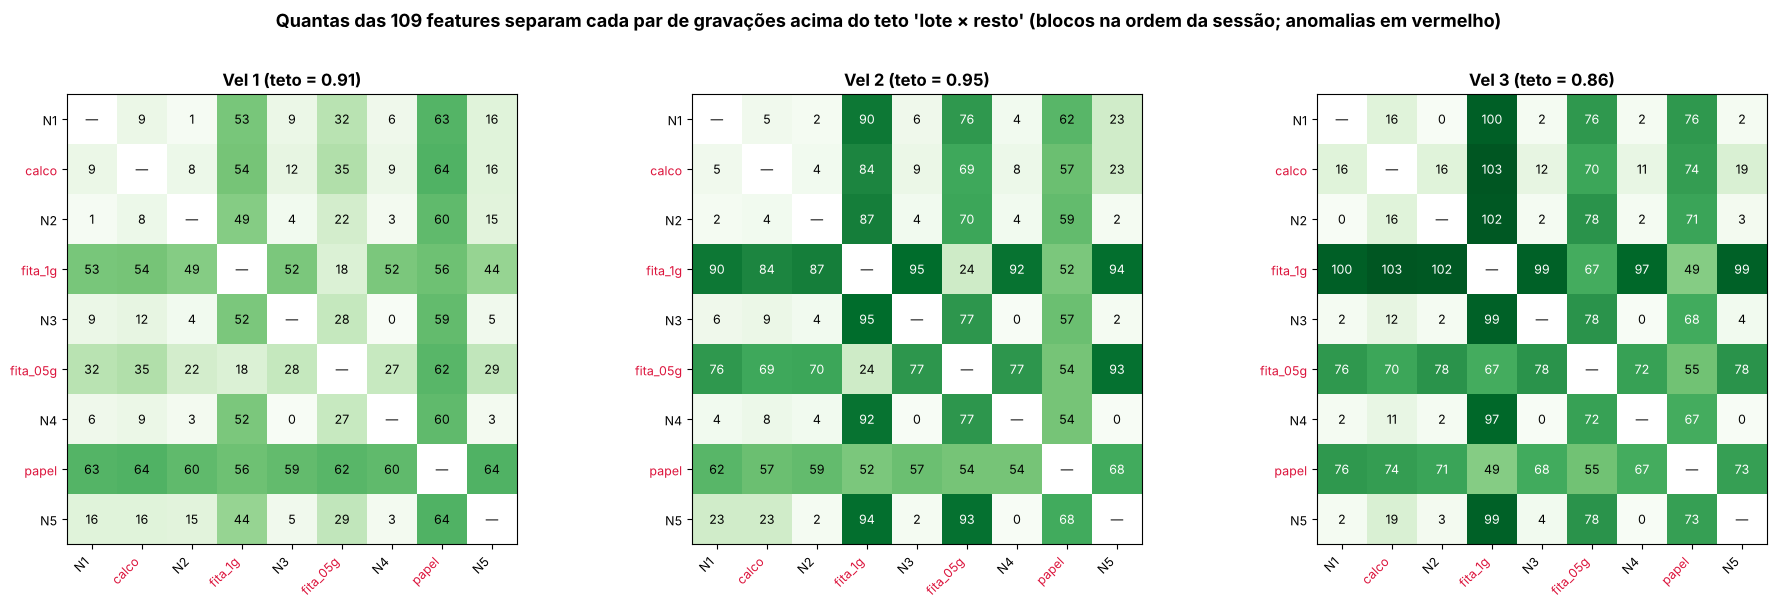

teto  features acima do teto   melhor feature  separação  mediana na 1ª falha  mediana na 2ª falha
par                velocidade                                                                                                     
calco × fita_05g   1           0.912                      35            std_x        1.0                0.552                0.828
                   2           0.946                      69            std_x        1.0                2.121                6.325
                   3           0.864                      70            std_x        1.0                1.263                2.830
calco × fita_1g    1           0.912                      54            std_x        1.0                0.552                1.469
                   2           0.946                      84            std_x        1.0                2.121                9.260
                   3           0.864                     103            std_x        1.0                1.263                4.855
calco × papel      1           0.912                      64            std_x        1.0                0.552                1.572
                   2           0.946                      57            std_y        1.0                1.485                2.451
                   3           0.864                      74            std_x        1.0                1.263                2.223
fita_05g × papel   1           0.912                      62            std_x        1.0                0.828                1.572
                   2           0.946                      54            std_x       -1.0                6.325                2.051
                   3           0.864                      55  fft_015_025Hz_x       -1.0                2.154                0.718
fita_1g × fita_05g 1           0.912                      18            std_x       -1.0                1.469                0.828
                   2           0.946                      24            std_y       -1.0                7.388                6.402
                   3           0.864                      67            std_x       -1.0                4.855                2.830
fita_1g × papel    1           0.912                      56            std_y        1.0                1.141                2.242
                   2           0.946                      52            std_x       -1.0                9.260                2.051
                   3           0.864                      49            std_x       -1.0                4.855                2.223

In [30]:
ordem_blocos = catalogo.drop_duplicates("bloco")["bloco"].tolist()
matrizes_distincao = plotar_matrizes_de_distincao(features, ordem_blocos, COLUNAS_TODAS, velocidades, BLOCOS_NORMAIS, BLOCOS_NORMAIS)

pares = resumir_pares_de_falhas(features, condicoes_comparadas, COLUNAS_TODAS, velocidades, BLOCOS_NORMAIS)
display(pares.round(3))

### O que encontramos no Passo 10

**10.1 — O normal contra ele mesmo:**
* **Vel 3:** os lotes normais quase não se separam (0 a 4 features entre qualquer par).
* **Vel 1:** de 0 a 16. O N5 é o que mais se afasta (15 e 16 contra N1 e N2).
* **Vel 2:** de 0 a 23. N1 × N5 é o maior (23), coerente com o aquecimento: os lotes mais distantes na sessão são os mais diferentes.

**Calço contra os normais:**
* **Vel 1:** 8 a 16 (contra N1 e N2, 9 e 8).
* **Vel 2:** 4 a 23 (contra N1 e N2, 5 e 4).
* **Vel 3:** **11 a 19**, contra no máximo 4 entre dois normais.

Nas Vel 1 e 2, o calço se separa dos normais **tanto quanto os normais se separam entre si**. Na Vel 3, ele se separa mais.

**10.2 — Falha contra falha (features acima do teto, Vel 1 / 2 / 3):**

| Par | Features | Melhor feature |
| --- | --- | --- |
| Fita 1 g × fita 0,5 g | **18 / 24** / 67 | `std_x` ou `std_y`: mesma assinatura, a de 1 g maior |
| Fita 1 g × papel | 56 / 52 / 49 | `std_y`, `std_x`, `std_x` |
| Fita 0,5 g × papel | 62 / 54 / 55 | `std_x`, `std_x`, faixa de 15–25 Hz no eixo X (a 1X) |
| Calço × fita 1 g | 54 / 84 / 103 | `std_x` nas três |
| Calço × fita 0,5 g | 35 / 69 / 70 | `std_x` nas três |
| Calço × papel | 64 / 57 / 74 | `std_x`, `std_y`, `std_x` |

* **Todos os pares se separam bem mais que dois normais quaisquer** na mesma velocidade (no máximo 16, 23 e 4).
* **O par mais difícil é fita 1 g × fita 0,5 g nas Vel 1 e 2.** É esperado: é a mesma falha com massas diferentes, e as features de intensidade (`std`) são as que melhor as separam. Se o modelo de diagnóstico juntar as duas como "fita", o problema some; se mantiver separadas, este é o par a vigiar.
* **O calço se distingue das outras três falhas** com folga, porque elas são fortes e ele é fraco. **A dificuldade do calço é contra o normal, não contra as outras falhas.**

## Conclusão do Notebook 02 (NOVOS_2.0)

1. **O controle precisa ser entre gravações:** dentro de cada gravação o normal quase não muda (teto antigo de 0,19 a 0,34), mas entre lotes ele muda bastante (teto "lote × resto" de 0,86 a 0,95). Este notebook usa duas réguas: a global (lote × resto) e a local (vizinhos), com um placebo para a local.
2. **Fita 1 g, fita 0,5 g e papel** superam as duas réguas nas três velocidades. Em força: **fita 1 g > papel ≈ fita 0,5 g**, com a fita 0,5 g na Vel 1 como o caso mais fraco das três (22 features acima do teto).
3. **Calço:**
   * Fica **dentro** da variação global do normal (4, 2 e 10 features acima do teto).
   * É **diferente dos seus vizinhos** muito mais do que um lote normal é dos dele (33, 18 e 32 features, contra 0 a 12 nos placebos).
   * **Vel 3 é onde ele mais aparece:** vibração maior em Y e Z (`std` cerca de 1,4 a 1,6 vez) e 1X do eixo Z 3 vezes maior, numa velocidade em que os lotes normais são quase idênticos.
   * **Vel 1 e 2:** aparece em rotação (mais lenta na Vel 1) e em faixas espalhadas, com sinais para os dois lados, numa variação do tamanho da que existe entre lotes normais.
   * **Leitura preliminar, não a decisão:** se o calço passar na regra dos 85%, é provável que seja pela Vel 3; as Vel 1 e 2 são as incertas. A decisão é do Notebook 05.
4. **A prévia de 12 nov vs. o Notebook 01:** a prévia acusou 94% do calço na Vel 1, enquanto o Notebook 01 o viu parecido com o normal. As melhores features do calço na Vel 1 são a rotação e a 1X (menores que nos vizinhos), justamente as que o Notebook 01 não olhou em intensidade. Isso **indica** que a prévia enxergou a rotação mais lenta, mas não prova: o detector da prévia usava as 109 features juntas.
5. **Rotação (`f1x_hz`):** o normal acelera ao longo da sessão nas Vel 1 e 2 (cerca de 0,8 Hz), e **todas as anomalias giram mais devagar na Vel 1** (−0,4 a −1,4 Hz contra os vizinhos), com o papel V2 bem mais lento (cerca de −3 Hz). É uma feature útil e perigosa ao mesmo tempo: ela pode separar as anomalias nesta sessão pelo motivo errado em outra.
6. **Assinaturas físicas, iguais às da coleta anterior:** fita = 1X e harmônicas (desbalanceamento, crescendo com a massa e a velocidade); papel = vibração larga e linhas novas fora das harmônicas; calço = mudanças pequenas e para os dois lados, mais claras na Vel 3.
7. **Diagnóstico:** todos os pares de falhas se separam; o mais difícil é **fita 1 g × fita 0,5 g nas Vel 1 e 2**.
8. **120 e 240 Hz:** iguais em todas as condições (elétricas).

**Limite principal:** continua existindo **uma gravação por anomalia e velocidade**. Os vizinhos e o placebo reduzem, mas não eliminam, o risco de a diferença ser "gravação A × gravação B". O teste trancado por blocos do Notebook 05 e o teste em outra sessão (NOVOS_DADOS) são os que respondem isso.

## O que conferir antes de seguir para o Notebook 03

* [ ] **Passo 2:** os vizinhos de cada anomalia batem com a ordem real da sessão (a ordem entre as fitas é assumida).
* [ ] **Passo 5:** nas fitas e no papel, a cor forte dos blocos de comparação **some** nos blocos de controle; no calço, isso só acontece na Vel 3.
* [ ] **Passos 6 e 7:** as faixas onde cada anomalia aparece estão anotadas, e o deslocamento das harmônicas do papel na Vel 2 foi entendido como rotação mais lenta.
* [ ] **Passo 8:** a subida da rotação do normal ao longo da sessão (Vel 1 e 2) e o freio das anomalias na Vel 1 estão anotados.
* [ ] **Passo 9:** as duas contagens e o placebo estão anotados para as quatro anomalias, em especial para o calço.
* [ ] **Passo 10:** o par mais difícil (fita 1 g × fita 0,5 g nas Vel 1 e 2) está anotado.

**Próximo passo:** Notebook 03, a **análise estatística** (distribuições, log e autocorrelação das janelas), com as mesmas bases. Com gravações de 3 min, a autocorrelação define quantas janelas são de fato independentes, o que importa para os blocos do Notebook 05.